# Charge injection on an ETROC2 + LGAD hybrid: what the sensor costs, and what it does not

**Chip** `ET2p01_Bar4` — an ETROC2 **version 2.01 bonded to an LGAD**, i.e. a hybrid module.
**Campaign** CERN climate chamber, January 2024. **Temperatures** −25, 0 and +22 °C.
**Sensor bias** 210 V, 0 V with the cable still plugged in, or not recorded, depending on the
configuration. **Pixels** 9, rows {2, 8, 14} × columns {2, 8, 14}. **Charges** 6–28 fC
(QSel 5–27; the injected charge is QSel + 1 fC, ETROC2 Reference Manual rev 0.60 §3.1.4, applied
by the loaders since 2026-10-18).

This is the companion to `qinj_studies/01_bare_et2p01_tid_jan2024.ipynb`, which analyses a
**bare** ET2.01 die from the same chip revision and the same January-2024 campaign. Both
notebooks import the same `qinj_common.py`, so the turn-off estimator, the preamp gain fit, the
S-curve fit, the TOT law and the quantisation floor are literally the same functions. Any
difference between the two sets of results is therefore a difference in the data.

**Run notebook 01 first** — section 10 here reads the tables it writes into `outputs/`.

## Why a sensor-loaded measurement is the one that matters

The injection is internal: a charge step at the preamplifier input, with the sensor playing no
part in generating it. The injected charge is therefore identical bare or bonded, and — worth
saying explicitly because this is the one notebook in the folder with a sensor on the chip —
**no LGAD multiplication enters any number here**. "Gain" throughout means the **preamp gain**,
the charge-to-threshold response of the front end in threshold-DAC LSB per fC; the sensor
contributes its capacitance to the preamplifier input node and nothing else. What is
*not* identical is what the preamplifier input sees, because a bonded LGAD adds detector
capacitance. The textbook expectation is that this raises the noise, roughly as
`ENC ≈ a + b·C_det`, and slightly slows the preamplifier edge, while leaving the
charge-to-TOT mapping largely alone.

This data set is the only place in the campaign where that expectation can be tested against a
measurement, and it is worth stating up front that **the measurement does not come out the way
the expectation reads**. It is also the only Q_inj threshold-scan set with a sensor attached
that exists anywhere in this programme.

## Primary configuration

`2024-01-18__0c_v15_HV_210_highpower` — **0 °C, sensor bias 210 V, `highpower`** — is used for
every headline number. It is the only configuration with the full charge set, a stated bias, a
stated power mode **and** a baseline map that passes its cross-check. Everything else in the
campaign appears in the inventory and in the bracket comparisons.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import qinj_common as Q
from qinj_style import apply_style

apply_style(0.55)
pd.set_option("display.width", 200, "display.max_columns", 80)

LEDGER = []
SN = Q.load_hybrid_summary_numbers()      # the published numbers, for cross-checking
PRIMARY = SN["primary"]
CFG_22 = "2024-01-19__22c_v20_HV_210_highpower"
CFG_M25 = "2024-01-12__m25c_v4"
CFG_ONR = "2024-01-12_22C_ONR__(none)"
CFG_HV0 = "2024-01-16__m25c_v12_HV_off_CablePluggedIn"
CFG_HVREF = "2024-01-16__m25c_v10"
TDC_CONFIGS = [CFG_M25, PRIMARY, CFG_22, CFG_ONR]

BARE = Q.OUTDIR / "bare_results.json"
if not BARE.exists():
    raise SystemExit("Run 01_bare_et2p01_tid_jan2024.ipynb first: section 10 needs its outputs/.")
with open(BARE) as fh:
    B = json.load(fh)

print("primary configuration:", PRIMARY)
print("bare-die reference   :", B["chip"], "-", B["kind"], "-", B["condition"])

primary configuration: 2024-01-18__0c_v15_HV_210_highpower
bare-die reference   : ET2p01_W36_6 - bare die, no sensor - 0 MRad, +12 °C


## 1. Provenance

Everything read here is under `data/hybrid_et2p01_cc_jan2024/`. It is the **reduced** form of
the `cern_Jan2024/CC` raw tree: about 12 GB of translated hit files and binary-search logs,
which live on LPC EOS at
`root://cmseos.fnal.gov//store/group/lpcmtdstudies/cern_Jan2024/CC/` and are **not** staged.

| file | RAW / DERIVED | what it is |
|---|---|---|
| `cc_points.feather` | RAW | one row per (config, pixel, charge, threshold): TOA/TOT/CAL mean and standard deviation in raw codes, plus the hit count. |
| `cc_fpga_probes.csv.gz` | RAW | every probe point of every binary search — the S-curve as data, with a real denominator. |
| `cc_turnoff.csv` | DERIVED | the reduction's own turn-off per (config, pixel, charge). Recomputed here from the probes rather than taken on trust. |
| `cc_tdc_dirs.csv.gz` | RAW | one row per scanned point directory, including those that produced no hits. This is what makes the censoring flag computable rather than assumed. |
| `cc_blnw.csv.gz` | RAW | the autocalibration baseline and noise-width maps, all 256 pixels of 19 maps. |
| `cc_configs.csv` | RAW + DERIVED | the configuration inventory: temperature, bias state and power tag, each with the provenance of how it was determined. |
| `cc_noiseonly.csv` | RAW | the in-configuration NoiseOnly scans — a baseline and noise measurement taken inside the configuration itself. |
| `aux_lv_timeseries.csv.gz` | RAW | the low-voltage rails from `PowerHistory_v2.sqlite`, one sample per rail per minute. |
| `aux_baseline_history.csv.gz` | RAW, aggregated | `BaselineHistory_CC_Jan2024_CERN.sqlite`, averaged per run and minute. |
| `table_aux_power_lv.csv`, `summary_numbers.json` | DERIVED | the published per-day rail summary and the published headline numbers, used here only for cross-checking. |

In [2]:
prov = pd.DataFrame([Q.file_row(p) for p in sorted(Q.HYB_DIR.iterdir()) if p.is_file()])
prov["MB"] = (prov.bytes / 1e6).round(3)
print(prov[["file", "bytes", "MB", "md5"]].to_string(index=False))

P = Q.load_hybrid_points()
PR = Q.load_hybrid_probes()
CFG = Q.load_hybrid_configs()
BLNW = Q.load_hybrid_blnw()
NO = Q.load_hybrid_noiseonly()
TD = Q.load_hybrid_tdc_dirs()
BLNW["applies_to_configs"] = BLNW.applies_to_configs.fillna("")
print("\ncc_points.feather   %6d rows x %d columns" % P.shape)
print("cc_fpga_probes      %6d turn-off probe points" % len(PR))
print("cc_tdc_dirs         %6d scanned point directories, %d of which produced no hits"
      % (len(TD), int((TD.n_nem + TD.n_bin == 0).sum()) if "n_nem" in TD else -1))
print("cc_configs          %6d configurations" % len(CFG))

                       file   bytes    MB                              md5
              PROVENANCE.md    7166 0.007 02de26c27498bb1060625c41c1a362e3
aux_baseline_history.csv.gz  103395 0.103 56d65ceec8df9e24eb29a4ba6e50ca8a
   aux_lv_timeseries.csv.gz  161004 0.161 df851467b6e05bec42f13e571c700e1d
             cc_blnw.csv.gz   44320 0.044 5ce2d9cb41b57815c046042b58dece69
             cc_configs.csv   10995 0.011 0418c23834af8933eaa2f3f0ffcdff02
      cc_fpga_probes.csv.gz  126377 0.126 ac52fd05c8a0b1e80c8310ae72d088df
           cc_noiseonly.csv   44755 0.045 313eb6c0dda21af7f6aff7facf8d4988
          cc_points.feather 1187466 1.187 a0f99500063c9f99c2215f96e1b624ee
         cc_tdc_dirs.csv.gz  118901 0.119 6b7f1c13738436760bd6e958c13f3932
             cc_turnoff.csv  101248 0.101 51a919ee1bfe5653270389a894b7494b
       summary_numbers.json   39915 0.040 9cfd699fc55d6a6a9a815afba4ab3c0e
     table_aux_power_lv.csv    1237 0.001 2f1d6e88c512609fe42e46fcf2702488

cc_points.feather    132

## 2. The configuration inventory — what each number is a measurement *of*

Temperature, bias state and power mode are **parsed from directory names only**. There is no
high-voltage log anywhere in this campaign, no on-chip temperature-sensor reading, and no
chamber-temperature log. Where the campaign did not record something, the tables below say
`not recorded` — never a guess and never an inferred value.

Two pixel sets exist and they do not overlap: rows {2, 8, 14} for the primary, the 22 °C
flagship and the whole −25 °C series; rows {0, 3, 12} for `22C_ONR` and 2024-01-11. Columns
are always {2, 8, 14}. **Only `22C_ONR` shares pixels with the bare-die set**, so the
bare-versus-hybrid comparison in section 10 is set-to-set, never pixel-to-pixel.

In [3]:
inv = CFG[CFG.n_turnoff_dirs > 0][["day", "tag", "temperature_C", "temperature_source",
                                   "hv_state", "hv_source", "power_tag", "n_tdc_dirs",
                                   "n_turnoff_dirs", "n_noiseonly_dirs", "n_pixels", "pixels"]]
inv = inv.copy()
inv["pixel_set"] = inv.pixels.apply(lambda s: "rows " + ",".join(
    sorted({str(int(x.strip()[1:].split("C")[0])) for x in s.split(";")}, key=int)))
inv["data"] = np.where(inv.n_tdc_dirs > 100, "full TDC sweep", "turn-off only")
print(inv[["temperature_C", "hv_state", "power_tag", "n_pixels", "pixel_set",
           "n_tdc_dirs", "n_turnoff_dirs", "data"]].to_string())
print("\nprovenance of each metadata field (how it was determined):")
print(CFG.loc[TDC_CONFIGS, ["temperature_source", "hv_source"]].to_string())

                                           temperature_C               hv_state     power_tag  n_pixels    pixel_set  n_tdc_dirs  n_turnoff_dirs            data
config                                                                                                                                                          
2024-01-11__(none)                          not recorded           not recorded  not recorded         9  rows 0,3,12           0              54   turn-off only
2024-01-12__0c_v2                                      0           not recorded  not recorded         9  rows 2,8,14           0              54   turn-off only
2024-01-12__m25c_v4                                  -25           not recorded  not recorded         9  rows 2,8,14        4260              54  full TDC sweep
2024-01-12_22C_ONR__(none)                            22           not recorded  not recorded         9  rows 0,3,12        2869              54  full TDC sweep
2024-01-13__m25c_v6               

## 3. Baseline, per configuration and per pixel — stricter than on the bare die

The bare campaign had one autocalibration map per condition. This campaign **renamed the chip
whenever the bias changed**, so a map found at a day's root can belong to a different bias
state than the scan taken that day. The rule applied here, recorded per pixel with its own
source and cross-check:

1. Prefer the map attributed to the configuration by name; a per-configuration map supersedes
   a day-level one.
2. **Accept it only if it passes a cross-check.** On a configuration with sweep points,
   `min(dac) − BL` must equal 5, since the sweep starts at `BL + 5`. On a turn-off-only
   configuration there is no sweep, so the map must instead agree with the in-configuration
   NoiseOnly peak.
3. If it fails, fall back to `min(dac) − 5`, or to the NoiseOnly peak, and say which.

**A noise width is carried only where the baseline came from an attributed map that passed.**
A map that cannot be attributed to a configuration carries no usable `NW` either, which is why
some configurations below have a preamp gain, a σ and a NoiseOnly RMS but no `NW`.

In [4]:
rows = []
for cfg in CFG.index:
    pix = [tuple(int(x) for x in s.strip()[1:].split("C")) for s in CFG.loc[cfg, "pixels"].split(";")]
    mp = BLNW[BLNW.applies_to_configs.str.split("; ").apply(lambda L: cfg in L)]
    if (mp.map_source == "config_subdir").any():
        mp = mp[mp.map_source == "config_subdir"]
    if len(mp) == 0:
        mp = BLNW[(BLNW.day == CFG.loc[cfg, "day"]) & (BLNW.map_source == "day_root")]
        src0 = "day_root map of same day (chip renamed, not attributed by name)"
    else:
        src0 = f"attributed map ({mp.map_source.iloc[0]})"
    mp = mp.drop_duplicates(["row", "col"]).set_index(["row", "col"])
    no = NO[NO.config == cfg].set_index(["row", "col"])
    pts = P[P.config == cfg]
    for (r, c) in pix:
        blm = float(mp.loc[(r, c), "baseline_dac"]) if (r, c) in mp.index else np.nan
        nwm = float(mp.loc[(r, c), "noise_width_dac"]) if (r, c) in mp.index else np.nan
        peak = float(no.loc[(r, c), "noise_peak_dac"]) if (r, c) in no.index else np.nan
        nrms = float(no.loc[(r, c), "noise_rms_dac"]) if (r, c) in no.index else np.nan
        mind = pts[(pts.row == r) & (pts.col == c)].dac.min() if len(pts) else np.nan
        bl, src, chk = blm, src0, "unverified"
        if not np.isnan(mind):
            chk = "min(dac)-BL = %d" % (mind - blm)
            if mind - blm != Q.BL_OFFSET:
                bl, src = mind - Q.BL_OFFSET, "min(dac)-5 (map failed the BL_offset check)"
        elif not np.isnan(peak) and not np.isnan(blm):
            d = blm - peak
            chk = "map - NoiseOnly peak = %+.0f" % d
            if abs(d) > 5:
                bl, src = peak, "NoiseOnly peak (attributed map fails by %+.0f DAC)" % d
        elif np.isnan(blm) and not np.isnan(peak):
            bl, src, chk = peak, "NoiseOnly peak (no map)", "n/a"
        rows.append(dict(config=cfg, row=r, col=c, BL_dac=bl, BL_source=src, BL_check=chk,
                         BL_map_dac=blm, NW_map_dac=nwm, noise_peak_dac=peak, noise_rms_dac=nrms))
BLC = pd.DataFrame(rows)
BLC["NW_valid"] = ~(BLC.BL_source.str.startswith("NoiseOnly peak")
                    | BLC.BL_source.str.startswith("day_root map"))
BLC.loc[~BLC.NW_valid, "NW_map_dac"] = np.nan
BLC.to_csv(Q.OUTDIR / "hybrid_baseline_by_config_pixel.csv", index=False)

keep = CFG.index[CFG.n_turnoff_dirs > 0]
print(BLC[BLC.config.isin(keep)].groupby(["config", "BL_source", "BL_check"]).size().to_string())
print("\nThe BL_offset = 5 check passes on every pixel of all four sweep configurations:",
      bool((P.merge(BLC, on=["config", "row", "col"]).groupby(["config", "row", "col"])
            .apply(lambda g: g.dac.min() - g.BL_dac.iloc[0]) == Q.BL_OFFSET).all()))
Q.check("mean baseline, primary config", BLC[BLC.config == PRIMARY].BL_dac.mean(),
        SN["BL"]["mean"], 0.02, "DAC", LEDGER)

config                                      BL_source                                                        BL_check                  
2024-01-11__(none)                          attributed map (day_root)                                        unverified                    9
2024-01-12_22C_ONR__(none)                  attributed map (day_root)                                        min(dac)-BL = 5               9
2024-01-12__0c_v2                           NoiseOnly peak (attributed map fails by +60 DAC)                 map - NoiseOnly peak = +60    1
                                            NoiseOnly peak (attributed map fails by +62 DAC)                 map - NoiseOnly peak = +62    2
                                            NoiseOnly peak (attributed map fails by +63 DAC)                 map - NoiseOnly peak = +63    2
                                            NoiseOnly peak (attributed map fails by +64 DAC)                 map - NoiseOnly peak = +64    2
                  

/var/folders/st/45tl5ffn70sg25zsxp7lfsb40000gq/T/ipykernel_16768/2341262674.py:44: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bool((P.merge(BLC, on=["config", "row", "col"]).groupby(["config", "row", "col"])


np.True_

In [5]:
D = P.merge(BLC[["config", "row", "col", "BL_dac", "BL_source", "NW_map_dac"]],
            on=["config", "row", "col"], how="left")
D = Q.add_tdc_derived(D, nhit="n_hits")
D["offset"] = D.dac - D.BL_dac
D["thr_mv"] = D.offset * Q.LSB_MV
D["cal_rms_gt2"] = D.cal_std > 2      # a flag, never a cut
DP = D[D.config == PRIMARY].copy()
print("primary config: %d points, %d pixels, offsets %d to %d, %d hits in total"
      % (len(DP), DP.groupby(["row", "col"]).ngroups, DP.offset.min(), DP.offset.max(), DP.n_hits.sum()))
print("points flagged cal_rms > 2 codes (flagged, not cut): %d of %d (%.1f %%)"
      % (DP.cal_rms_gt2.sum(), len(DP), 100 * DP.cal_rms_gt2.mean()))

primary config: 3550 points, 9 pixels, offsets 5 to 190, 1836195 hits in total
points flagged cal_rms > 2 codes (flagged, not cut): 125 of 3550 (3.5 %)


## 4. Explainer figures

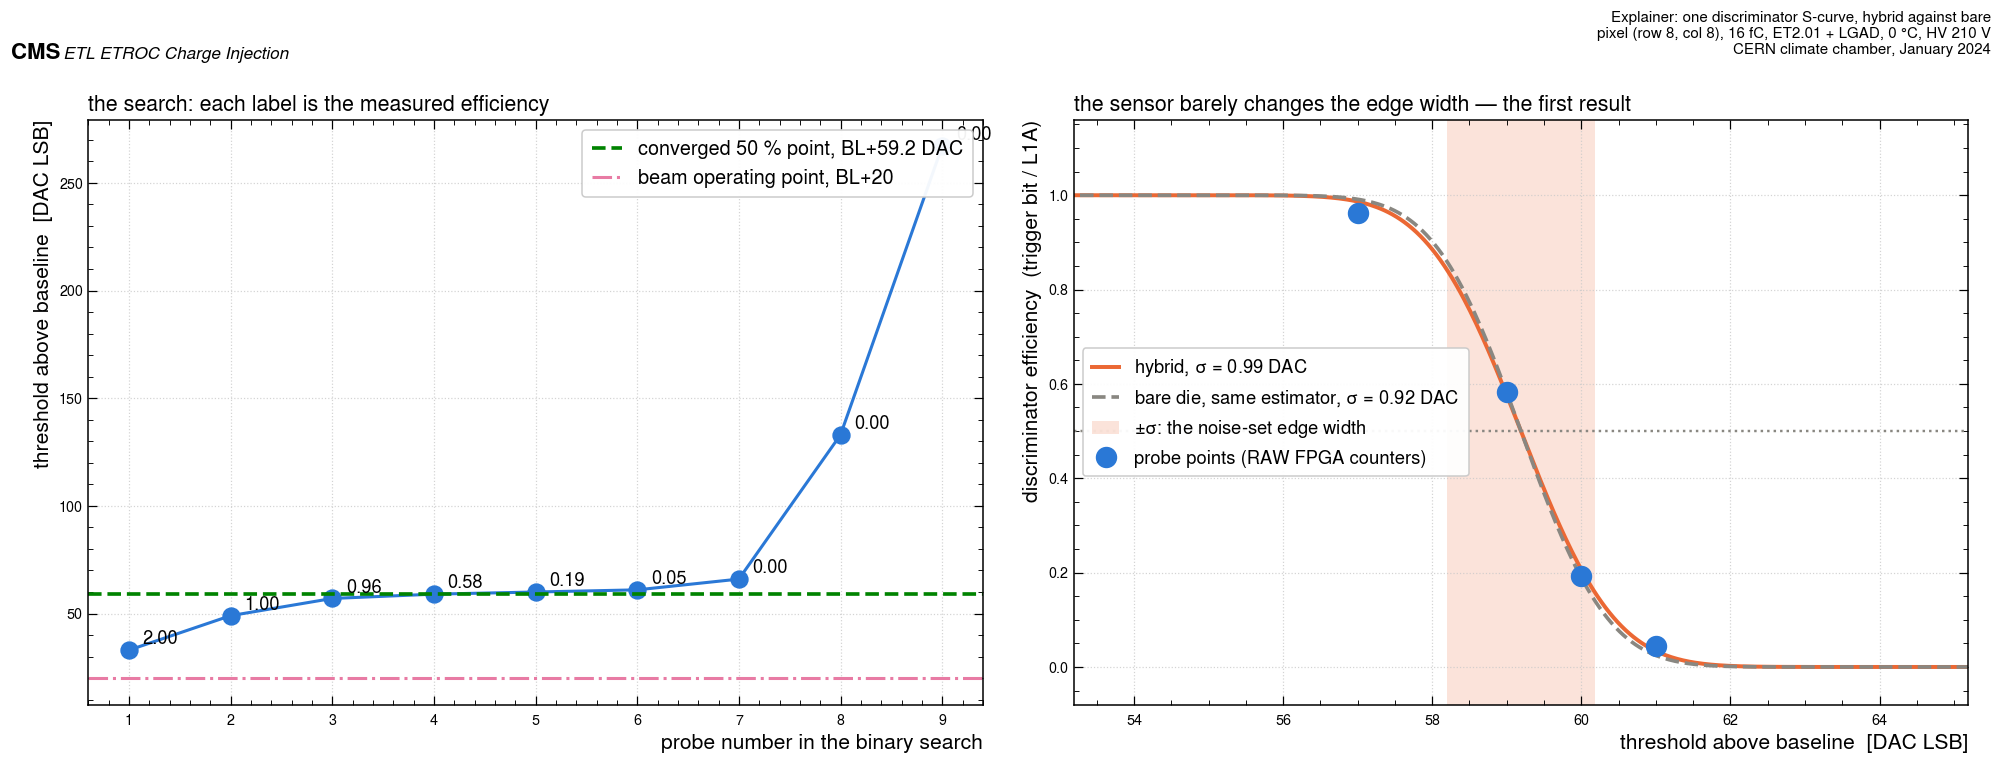

In [6]:
# --- Explainer 1: one hybrid S-curve, with the bare chip's edge drawn beside it.
gh = PR[(PR.config == PRIMARY) & (PR.row == 8) & (PR.col == 8) & (PR.charge_fC == 16)].sort_values("dac")
bl_h = float(BLC[(BLC.config == PRIMARY) & (BLC.row == 8) & (BLC.col == 8)].BL_dac.iloc[0])
cv_h, _ = Q.curves_from(gh, keys=("row", "col", "charge_fC"))
sig_h, _, mu_h, _ = Q.scurve_sigma(cv_h, boot=0)
mu_h = mu_h[0]
to_h = Q.turnoff_50pct(gh.dac, gh.frac)

fig, axs = plt.subplots(1, 2, figsize=(18, 6.4))
ax = axs[0]
ax.plot(np.arange(1, len(gh) + 1), gh.dac - bl_h, "o-", ms=11, lw=2.0, color=Q.C_BLUE)
for i, (d_, f_) in enumerate(zip(gh.dac, gh.frac), start=1):
    ax.annotate(f"{f_:.2f}", (i, d_ - bl_h), textcoords="offset points", xytext=(9, 4), fontsize=12)
ax.axhline(to_h - bl_h, color=Q.C_GREEN, ls="--", lw=2.4,
           label=f"converged 50 % point, BL+{to_h - bl_h:.1f} DAC")
ax.axhline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2.0, label="beam operating point, BL+20")
ax.set_xlabel("probe number in the binary search")
ax.set_ylabel("threshold above baseline  [DAC LSB]")
ax.set_title("the search: each label is the measured efficiency", loc="left", fontsize=14)
ax.legend(fontsize=13, loc="upper right")

ax = axs[1]
ax.errorbar(gh.dac - bl_h, gh.frac,
            yerr=np.sqrt(np.clip(gh.frac, 0, 1) * (1 - np.clip(gh.frac, 0, 1)) / gh.header_max),
            fmt="o", ms=13, color=Q.C_BLUE, zorder=5, label="probe points (RAW FPGA counters)")
xx = np.linspace(mu_h - 8, mu_h + 8, 600)
ax.plot(xx - bl_h, Q.gauss_cdf(xx, mu_h, sig_h), "-", color=Q.C_ORANGE, lw=2.6,
        label=f"hybrid, $\\sigma$ = {sig_h:.2f} DAC")
ax.plot(xx - bl_h, Q.gauss_cdf(xx, mu_h, B["sigma_dac"]), "--", color=Q.GREY, lw=2.4,
        label=f"bare die, same estimator, $\\sigma$ = {B['sigma_dac']:.2f} DAC")
ax.axhline(0.5, color=Q.GREY, ls=":", lw=1.6)
ax.axvspan(mu_h - sig_h - bl_h, mu_h + sig_h - bl_h, color=Q.C_ORANGE, alpha=0.18, lw=0,
           label="$\\pm\\sigma$: the noise-set edge width")
ax.set_xlim(mu_h - 6 - bl_h, mu_h + 6 - bl_h)
ax.set_ylim(-0.08, 1.16)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("discriminator efficiency  (trigger bit / L1A)")
ax.legend(loc="center left", fontsize=12)
ax.set_title("the sensor barely changes the edge width — the first result", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "Explainer: one discriminator S-curve, hybrid against bare",
       tag="pixel (row 8, col 8), 16 fC, ET2.01 + LGAD, 0 °C, HV 210 V", scale=0.62)
Q.save_fig(fig, "hyb_expl1_scurve")
plt.show()

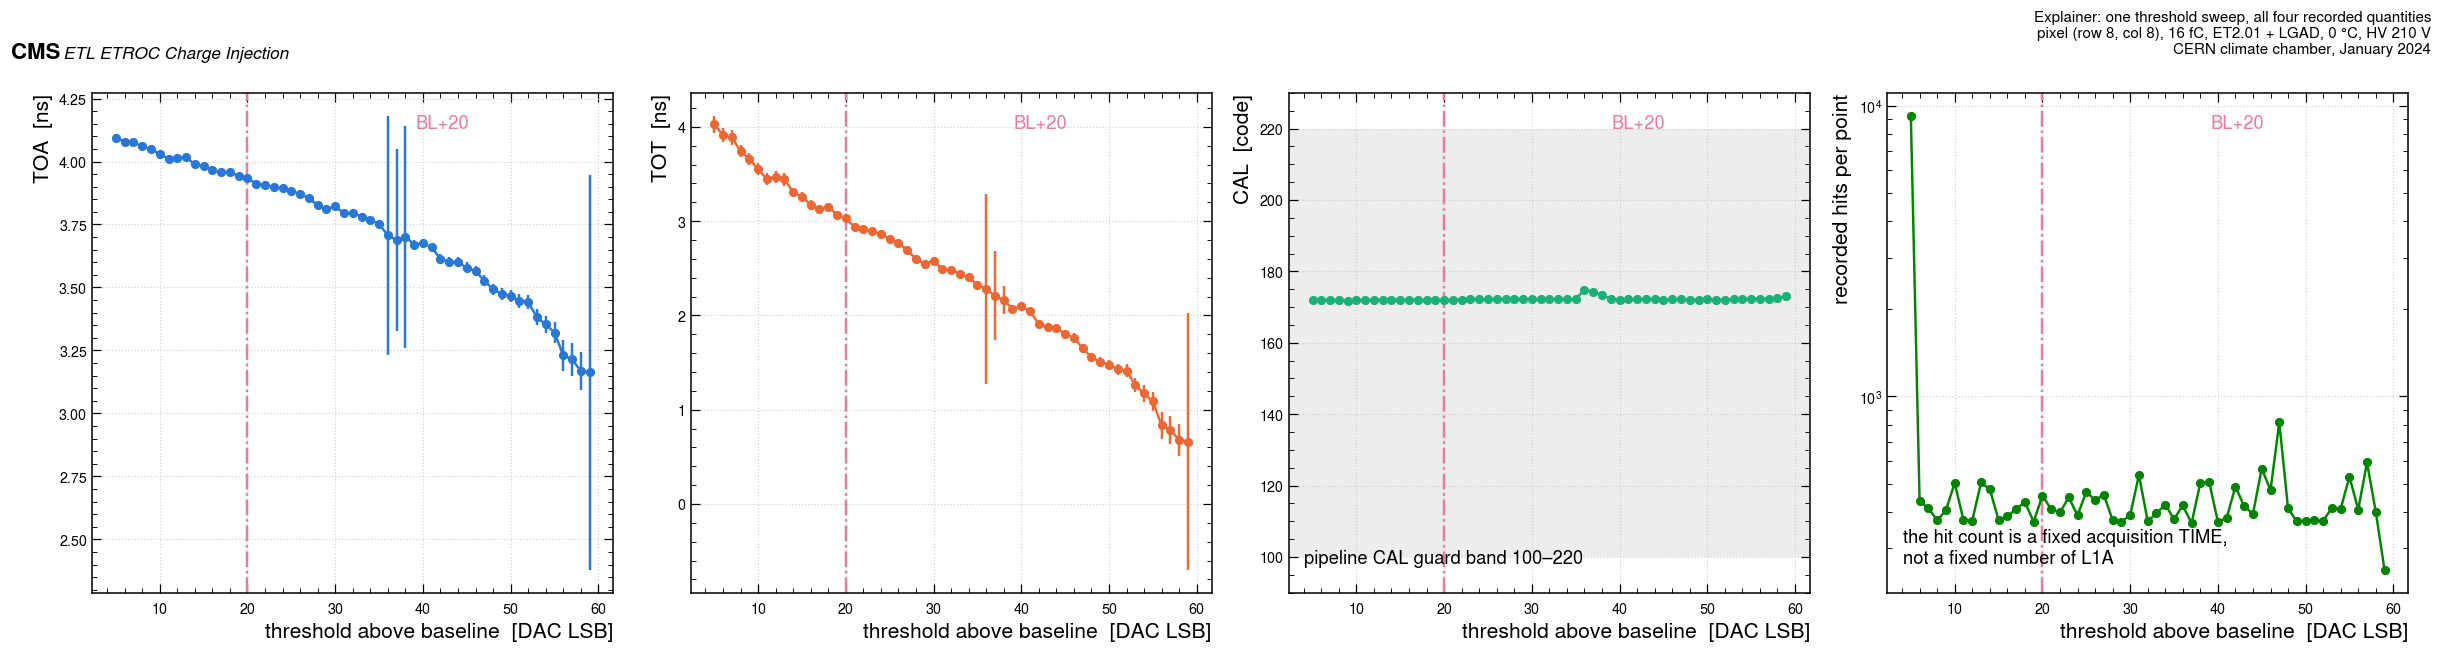

In [7]:
# --- Explainer 2: what one threshold sweep records.
pix, qq = (8, 8), 16
d = DP[(DP.row == pix[0]) & (DP.col == pix[1]) & (DP.charge_fC == qq)].sort_values("offset")
fig, axs = plt.subplots(1, 4, figsize=(22, 5.4))
for ax, (col, lab, cc) in zip(axs, [("toa_ns", "TOA  [ns]", Q.C_BLUE),
                                    ("tot_ns", "TOT  [ns]", Q.C_ORANGE),
                                    ("cal_mean", "CAL  [code]", Q.C_AQUA),
                                    ("n_hits", "recorded hits per point", Q.C_GREEN)]):
    yerr = d.jitter_ps / 1e3 if col == "toa_ns" else (d.tot_std_ns if col == "tot_ns" else None)
    ax.errorbar(d.offset, d[col], yerr=yerr, fmt="o-", ms=5, lw=1.6, color=cc)
    ax.set_xlabel("threshold above baseline  [DAC LSB]")
    ax.set_ylabel(lab)
    ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=1.6)
    ax.text(0.62, 0.93, "BL+20", transform=ax.transAxes, color=Q.C_MAG, fontsize=12)
axs[2].axhspan(*Q.CAL_GUARD, color=Q.GREY, alpha=0.15, lw=0)
axs[2].set_ylim(min(Q.CAL_GUARD) - 10, max(Q.CAL_GUARD) + 10)
axs[2].text(0.03, 0.06, "pipeline CAL guard band 100–220", transform=axs[2].transAxes, fontsize=12)
axs[3].set_yscale("log")
axs[3].text(0.03, 0.06, "the hit count is a fixed acquisition TIME,\nnot a fixed number of L1A",
            transform=axs[3].transAxes, fontsize=12)
fig.tight_layout()
Q.fig_header(fig, "Explainer: one threshold sweep, all four recorded quantities",
       tag=f"pixel (row {pix[0]}, col {pix[1]}), {qq} fC, ET2.01 + LGAD, 0 °C, HV 210 V", scale=0.62)
Q.save_fig(fig, "hyb_expl2_sweep_quantities")
plt.show()

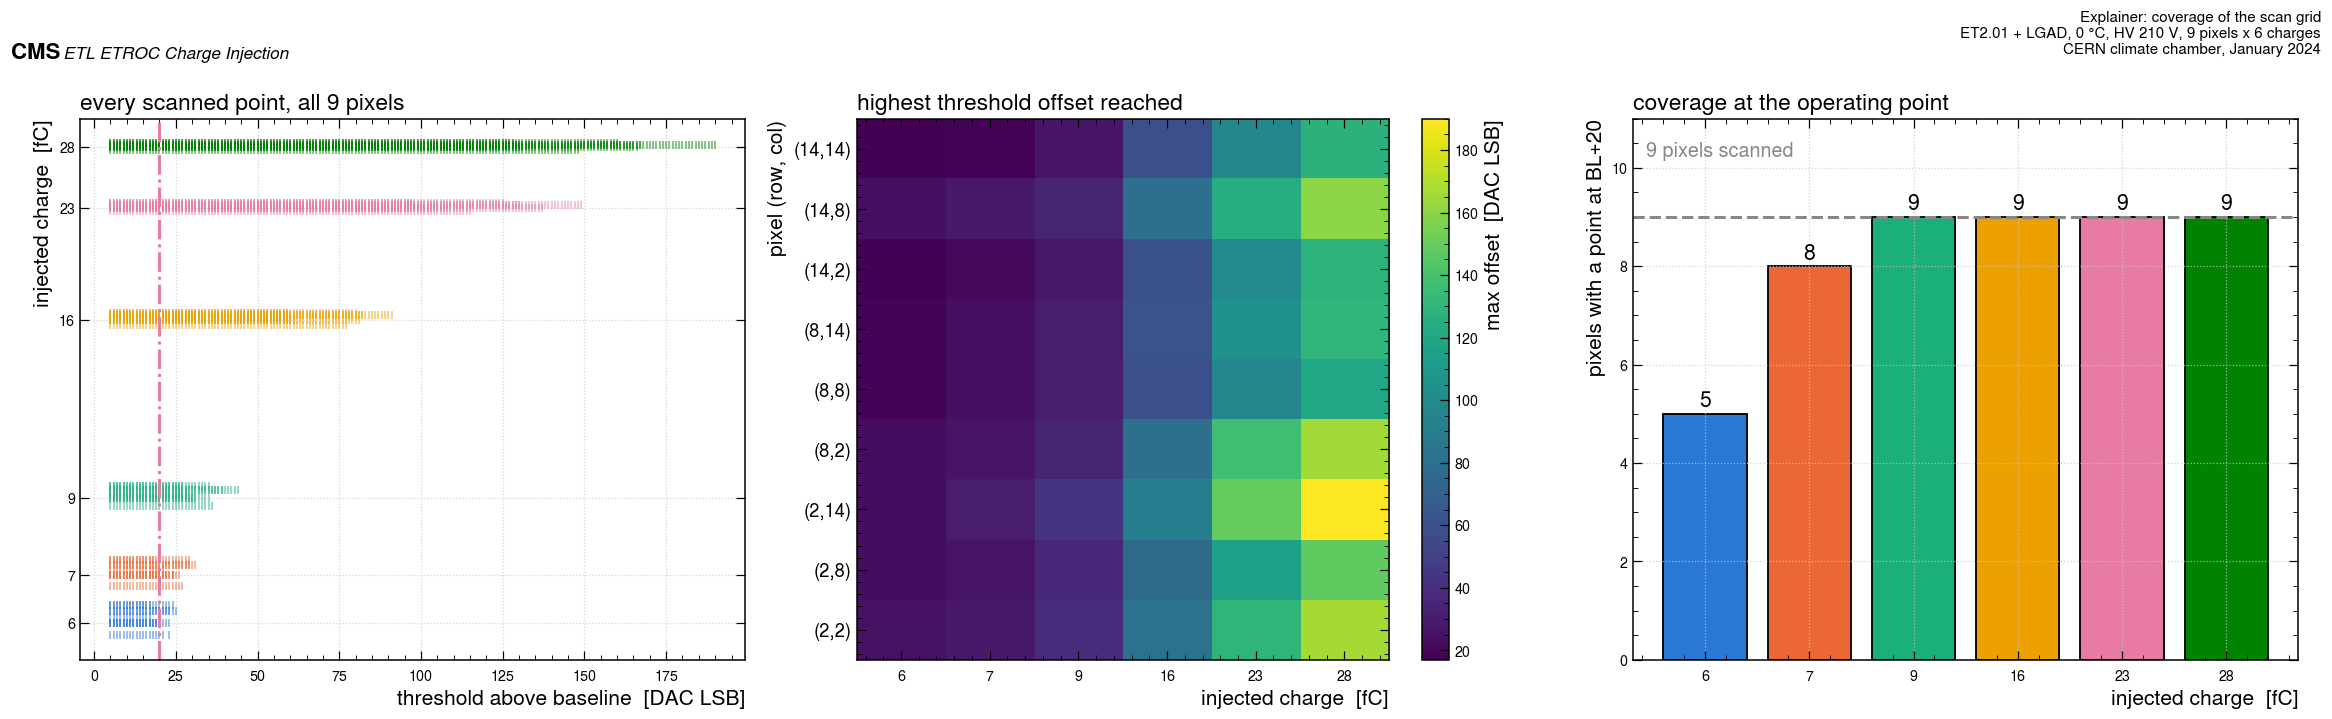

pixels with a point exactly at BL+20, by charge: {6: 5, 7: 8, 9: 9, 16: 9, 23: 9, 28: 9}
On the bare die the same count was: {'6': 9, '7': 12, '9': 12, '16': 12, '23': 12, '28': 12}


In [8]:
# --- Explainer 3: coverage of the scan grid.
fig, axs = plt.subplots(1, 3, figsize=(21, 6.0))
ax = axs[0]
for ch in Q.CHARGES:
    sub = DP[DP.charge_fC == ch]
    for (r, c), gg in sub.groupby(["row", "col"]):
        ax.plot(gg.offset, np.full(len(gg), ch) + 0.35 * (hash((r, c)) % 7 - 3) / 3, "|", ms=5,
                color=Q.CCOL[ch], alpha=0.6)
Q.charge_axis(ax, axis="y")
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("injected charge  [fC]")
ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
ax.set_title("every scanned point, all 9 pixels", loc="left", fontsize=15)

ax = axs[1]
cover = (DP.groupby(["row", "col", "charge_fC"]).offset.max().reset_index()
           .pivot_table(index=["row", "col"], columns="charge_fC", values="offset"))
im = ax.imshow(cover.values, aspect="auto", cmap="viridis", origin="lower")
ax.set_xticks(range(len(cover.columns)))
ax.set_xticklabels([str(int(c)) for c in cover.columns])
ax.set_yticks(range(len(cover.index)))
ax.set_yticklabels([f"({r},{c})" for r, c in cover.index], fontsize=12)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("pixel (row, col)")
ax.grid(False)
ax.set_title("highest threshold offset reached", loc="left", fontsize=15)
plt.colorbar(im, ax=ax, label="max offset  [DAC LSB]")

ax = axs[2]
n20 = DP[DP.offset == Q.OP_OFFSET].groupby("charge_fC").size().reindex(Q.CHARGES).fillna(0).astype(int)
ax.bar([str(c) for c in Q.CHARGES], n20.values, color=[Q.CCOL[c] for c in Q.CHARGES],
       edgecolor="black", lw=1.2)
ax.axhline(9, color=Q.GREY, ls="--", lw=2)
ax.text(0.02, 0.93, "9 pixels scanned", transform=ax.transAxes, fontsize=13, color=Q.GREY)
for i, v in enumerate(n20.values):
    ax.text(i, v + 0.15, str(v), ha="center", fontsize=14)
ax.set_ylim(0, 11)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("pixels with a point at BL+20")
ax.set_title("coverage at the operating point", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "Explainer: coverage of the scan grid",
       tag="ET2.01 + LGAD, 0 °C, HV 210 V, 9 pixels x 6 charges", scale=0.62)
Q.save_fig(fig, "hyb_expl3_scan_grid")
plt.show()
print("pixels with a point exactly at BL+20, by charge:", n20.to_dict())
print("On the bare die the same count was:", B["jitter_off20_n_by_charge"])

**6 fC reaches the operating point on only 5 of 9 pixels here**, against 9 of 12 on the bare
die. That is the lower preamp gain showing up as reduced coverage, and it is why the pooled 6 and
7 fC numbers below average fewer pixels than the rest.

## 5. What the campaign actually monitored

The request behind this analysis asked what auxiliary data exists. Every directory name, both
`PowerHistory_v2.sqlite` files, the `BaselineHistory` sqlite and every JSON, YAML, config,
text and log file in the raw tree were searched. The result:

| auxiliary quantity | present? | where |
|---|---|---|
| Low-voltage rails, V and I | **yes** | `PowerHistory_v2.sqlite`, table `power_v2`, ~5 s sampling |
| Autocalibration baseline / noise-width history | **yes** | `BaselineHistory_CC_Jan2024_CERN.sqlite`, and the map pickles |
| High voltage (sensor bias) | **no** | no HV channel in either sqlite, no HV column, no HV token in any note |
| On-chip temperature sensor (VTemp) | **no** | no column, no file, no directory name anywhere |
| Chamber or plate temperature log | **no** | only the coarse tag in directory names (`m25c`, `0c`, `22c`) |
| Voltage reference as a monitored value | **no** | "VRef" appears only as the *scan type*; ET2.01 took its reference externally |
| RFSel | **no** | nowhere in this campaign, or in the bare-die one |
| Injections per point | **no** | the sweep acquires for a fixed time |

One further absence is worth recording because it limits the figure below: **the scan windows
are not recoverable**. Directory modification times in both the EOS original and the working
copy are upload and copy times, not acquisition times, and no scan file carries a wall-clock
stamp. The only genuine timestamps in the campaign are inside the two sqlite logs, so the
auxiliary figures anchor on those and on calendar days.

In [9]:
LV = Q.load_hybrid_lv()
BH = Q.load_hybrid_bl_history()
AUX = Q.load_hybrid_aux_power()
LV["day"] = LV.timestamp.dt.date
print("low-voltage log: %s to %s, %d samples retained (1 per rail per minute)"
      % (LV.timestamp.min(), LV.timestamp.max(), len(LV)))
day_med = LV[LV.V > 0.5].groupby(["day", "rail"]).agg(
    V=("V", "median"), I_A=("I_A", "median"), P_mW=("P_mW", "median"), n=("V", "size")).round(4)
print()
print(day_med.to_string())
pub = AUX.set_index(["day", "rail"])
for day, cfgname in [("2024-01-18", PRIMARY), ("2024-01-19", CFG_22)]:
    got = float(day_med.loc[(pd.Timestamp(day).date(), "Analog"), "I_A"])
    want = float(pub.loc[(day, "Analog"), "I_median_A"])
    Q.check(f"analog rail current, {day} ({cfgname.split('__')[1]})", got, want, 0.002, "A", LEDGER)

low-voltage log: 2024-01-12 17:53:32.083710 to 2024-01-19 13:53:04.230081, 19470 samples retained (1 per rail per minute)

                        V     I_A      P_mW     n
day        rail                                  
2024-01-12 Analog   1.276  0.4758  606.7725   367
           Digital  1.224  0.1127  137.9350   367
2024-01-13 Analog   1.277  0.4659  594.8712  1440
           Digital  1.224  0.1107  135.4968  1440
2024-01-14 Analog   1.277  0.4660  595.0820  1440
           Digital  1.224  0.1107  135.4968  1440
2024-01-15 Analog   1.277  0.4627  590.6125  1440
           Digital  1.224  0.1220  149.3277  1440
2024-01-16 Analog   1.277  0.4627  590.2776  1440
           Digital  1.224  0.1219  149.3275  1440
2024-01-17 Analog   1.278  0.4633  591.7618  1334
           Digital  1.224  0.1110  135.9750  1334
2024-01-18 Analog   1.278  0.3419  437.0760  1440
           Digital  1.223  0.1149  140.6376  1440
2024-01-19 Analog   1.278  0.4994  638.6328   834
           Digital  1.224  

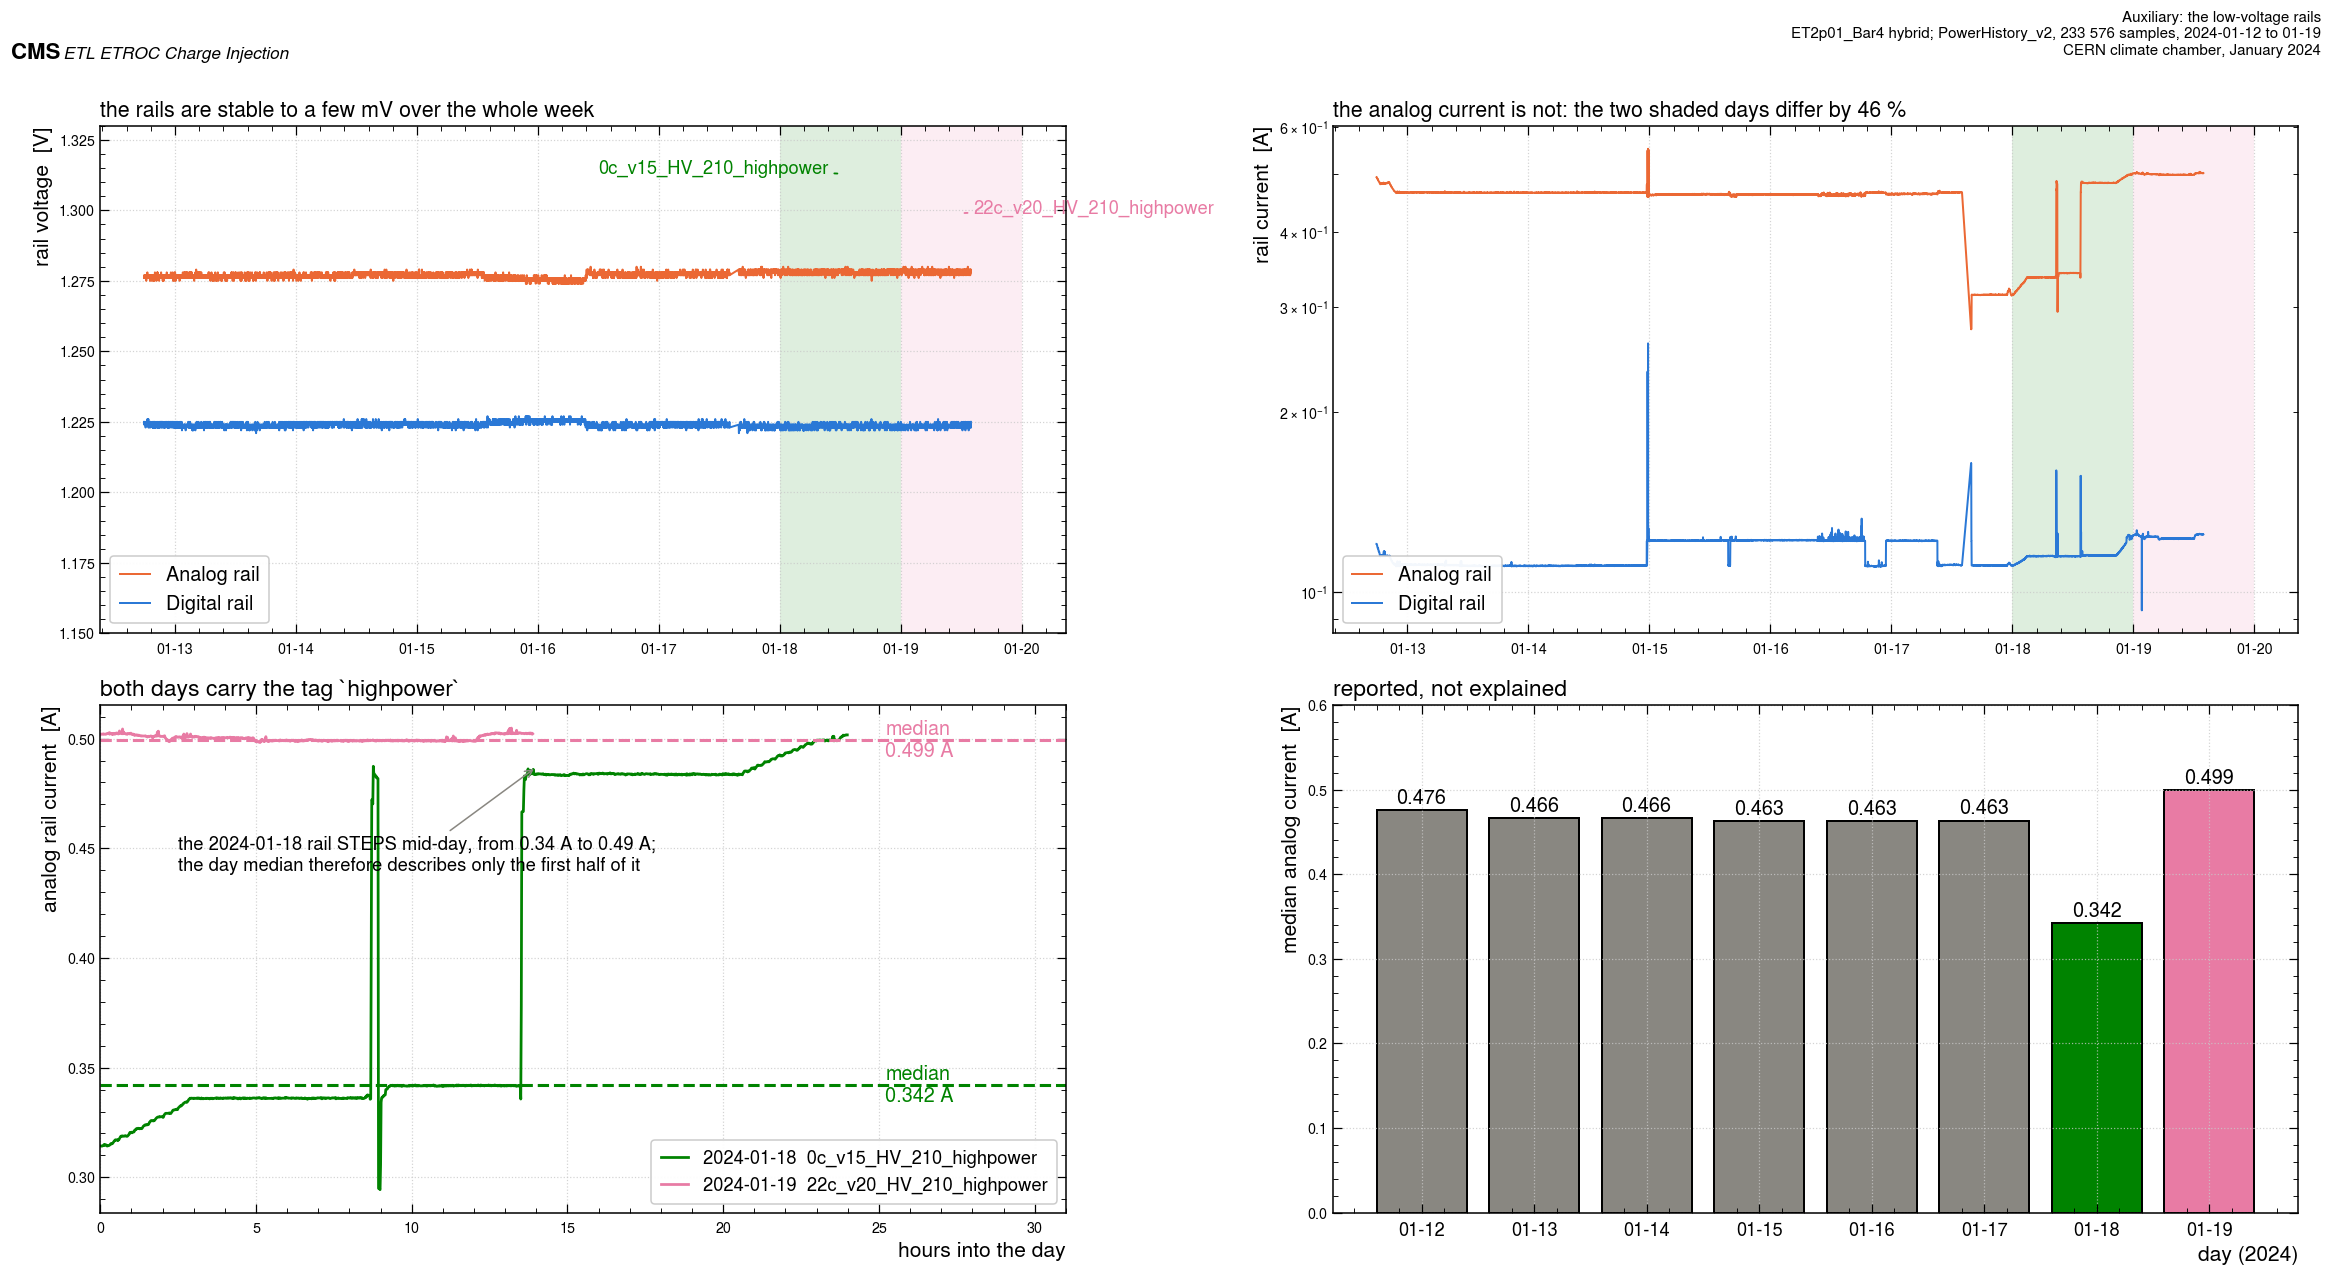

In [10]:
fig, axs = plt.subplots(2, 2, figsize=(21, 11))
COLR = {"Analog": Q.C_ORANGE, "Digital": Q.C_BLUE}
FLAG = {"2024-01-18": (PRIMARY, Q.C_GREEN), "2024-01-19": (CFG_22, Q.C_MAG)}

ax = axs[0, 0]
for rail, g in LV.groupby("rail"):
    ax.plot(g.timestamp, g.V, "-", lw=1.3, color=COLR[rail], label=f"{rail} rail")
for k, (d, (cfg, c)) in enumerate(FLAG.items()):
    t0 = pd.Timestamp(d)
    ax.axvspan(t0, t0 + pd.Timedelta(days=1), color=c, alpha=0.13, lw=0)
    ax.annotate(cfg.split("__")[1], xy=(t0 + pd.Timedelta(hours=12), 1.313 - 0.014 * k),
                ha="right" if k == 0 else "left", fontsize=12, color=c,
                xytext=(-8 if k == 0 else 8, 0), textcoords="offset points",
                arrowprops=dict(arrowstyle="-", color=c, lw=1.2))
ax.set_ylabel("rail voltage  [V]")
ax.set_ylim(1.15, 1.33)
ax.legend(fontsize=13, loc="lower left")
ax.set_title("the rails are stable to a few mV over the whole week", loc="left", fontsize=14)

ax = axs[0, 1]
for rail, g in LV.groupby("rail"):
    ax.plot(g.timestamp, g.I_A, "-", lw=1.3, color=COLR[rail], label=f"{rail} rail")
for d, (cfg, c) in FLAG.items():
    t0 = pd.Timestamp(d)
    ax.axvspan(t0, t0 + pd.Timedelta(days=1), color=c, alpha=0.13, lw=0)
ax.set_ylabel("rail current  [A]")
ax.set_yscale("log")
ax.legend(fontsize=13, loc="lower left")
I18 = float(day_med.loc[(pd.Timestamp("2024-01-18").date(), "Analog"), "I_A"])
I19 = float(day_med.loc[(pd.Timestamp("2024-01-19").date(), "Analog"), "I_A"])
ax.set_title("the analog current is not: the two shaded days differ by %.0f %%" % (100 * (I19 / I18 - 1)),
             loc="left", fontsize=14)

ax = axs[1, 0]
for d, (cfg, c) in FLAG.items():
    g = LV[(LV.rail == "Analog") & (LV.timestamp.dt.date == pd.Timestamp(d).date()) & (LV.V > 0.5)]
    ax.plot((g.timestamp - pd.Timestamp(d)).dt.total_seconds() / 3600, g.I_A, "-", lw=1.8,
            color=c, label=f"{d}  {cfg.split('__')[1]}")
    ax.axhline(g.I_A.median(), color=c, ls="--", lw=2)
    ax.text(25.2, g.I_A.median(), f"median\n{g.I_A.median():.3f} A", color=c, fontsize=13,
            va="center", ha="left")
ax.annotate("the 2024-01-18 rail STEPS mid-day, from 0.34 A to 0.49 A;\n"
            "the day median therefore describes only the first half of it",
            xy=(14.0, 0.487), xytext=(2.5, 0.44), fontsize=12,
            arrowprops=dict(arrowstyle="->", color=Q.GREY))
ax.set_xlabel("hours into the day")
ax.set_ylabel("analog rail current  [A]")
ax.set_xlim(0, 31)
ax.legend(fontsize=12, loc="lower right")
ax.set_title("both days carry the tag `highpower`", loc="left", fontsize=15)

ax = axs[1, 1]
ana = day_med.xs("Analog", level="rail").reset_index()
cols = [FLAG[str(d)][1] if str(d) in FLAG else Q.GREY for d in ana.day]
ax.bar(range(len(ana)), ana.I_A, color=cols, edgecolor="black", lw=1.3)
for i, v in enumerate(ana.I_A):
    ax.text(i, v + 0.008, f"{v:.3f}", ha="center", fontsize=13)
ax.set_xticks(range(len(ana)))
ax.set_xticklabels([str(d)[5:] for d in ana.day], fontsize=12)
ax.set_ylabel("median analog current  [A]")
ax.set_ylim(0, 0.6)
ax.set_xlabel("day (2024)")
ax.set_title("reported, not explained", loc="left", fontsize=15)
for ax in axs[0]:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
fig.tight_layout()
Q.fig_header(fig, "Auxiliary: the low-voltage rails",
       tag="ET2p01_Bar4 hybrid; PowerHistory_v2, 233 576 samples, 2024-01-12 to 01-19", scale=0.62)
Q.save_fig(fig, "hyb_aux1_lv_rails")
plt.show()

**`highpower` is a directory tag, not a measurement.** Both flagship configurations carry it,
yet the median analog supply current on their two days differs by the amount printed above:
0.342 A on 2024-01-18
against 0.500 A on 2024-01-19. Either the tag does not fully describe the power state, or the
per-day medians mix scan and idle periods — and because the scan windows are not recoverable
(section 5), this cannot be settled from the staged data. It is reported, not explained, and
it means the two flagship configurations may differ in power state as well as in temperature.

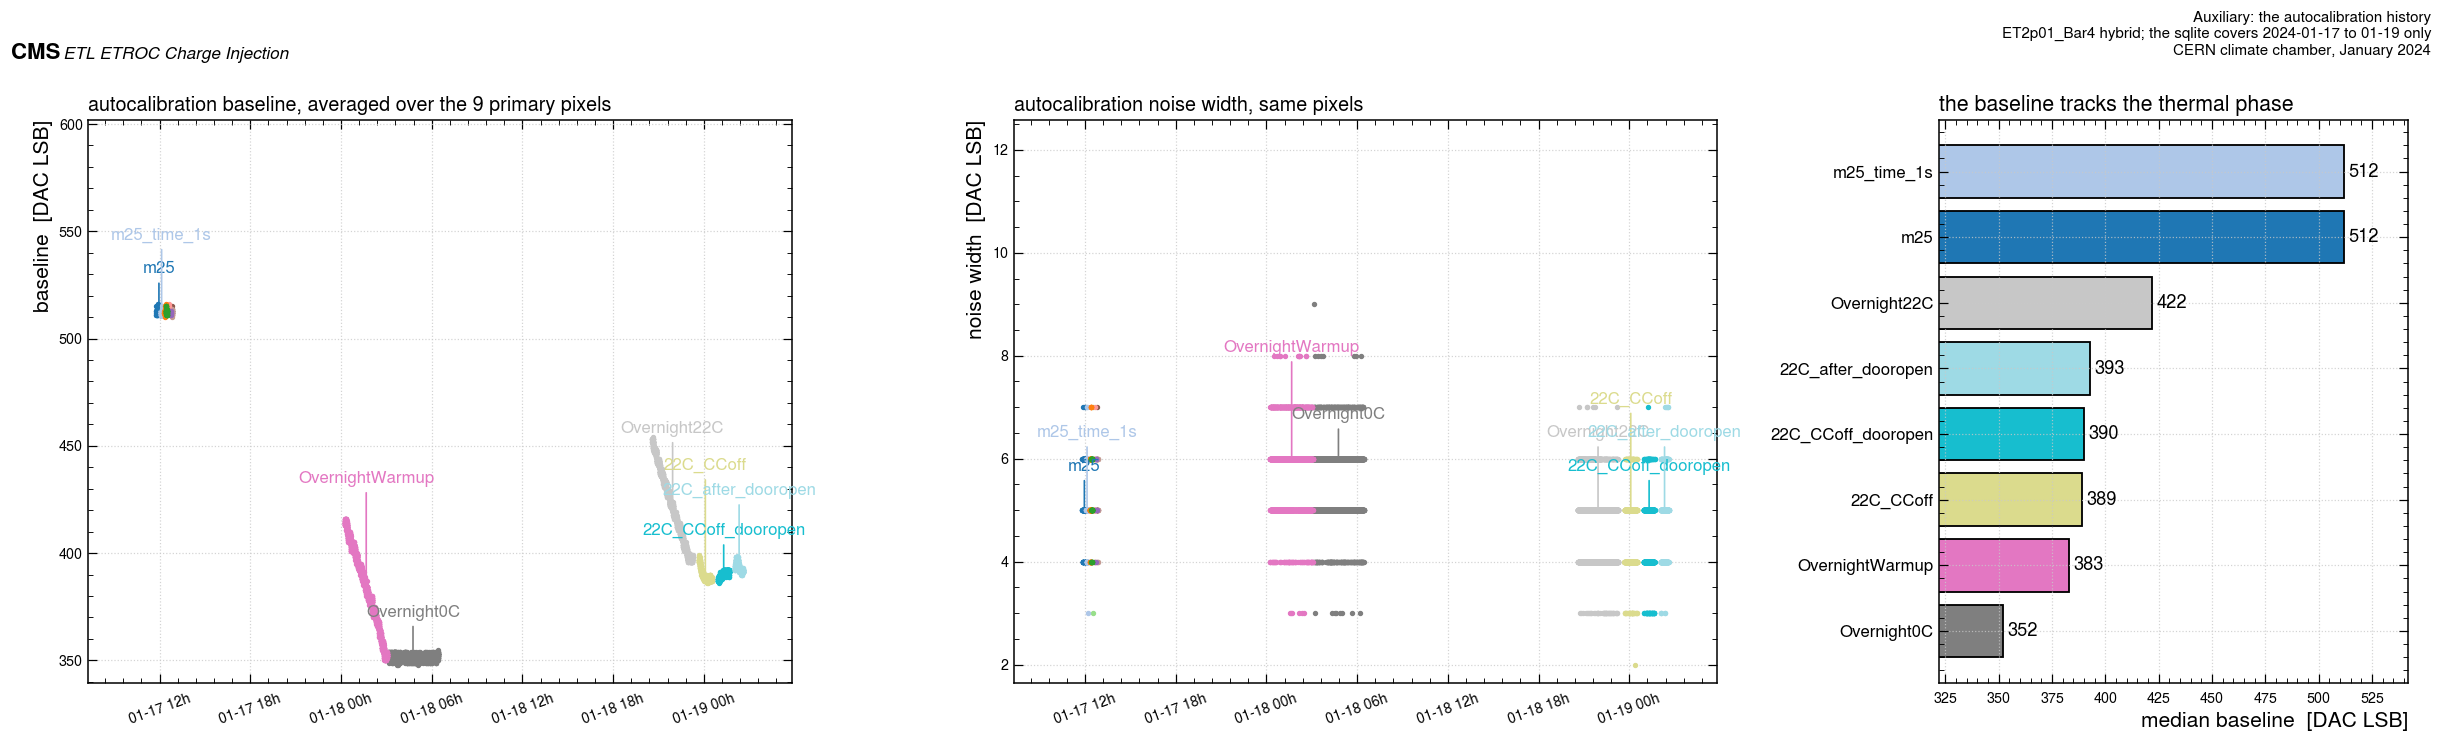

                                           BL   NW     n                             t
condition                                                                             
22C_CCoff_Jan_18_2024_time_3s           389.0  5.0   619 2024-01-19 00:05:52.345051904
22C_CCoff_dooropen_Jan_18_2024_time_3s  390.0  5.0   538 2024-01-19 01:18:42.479711232
22C_after_dooropen_Jan_18_2024_time_3s  393.0  5.0   400 2024-01-19 02:19:55.196040704
CCoff_Jan_17_2024_time_3s               513.0  5.0    13 2024-01-17 12:48:36.425075968
CCoff_Jan_17_2024_time_3s_v2            512.0  5.0    13 2024-01-17 12:49:52.675225088
Overnight0C_Jan_18_2024_time_3s         352.0  6.0  2460 2024-01-18 04:45:42.233404928
Overnight22C_Jan_18_2024_time_3s        422.0  5.0  1931 2024-01-18 21:55:58.712218880
OvernightWarmup_Jan_18_2024_time_3s     383.0  6.0  2054 2024-01-18 01:40:02.764787456
m25_Jan_17_2024                         512.0  5.0   139 2024-01-17 11:57:21.304577024
m25_Jan_17_2024_time_10s                512

In [11]:
BH["condition"] = BH.note.str.replace(r"^Run\d+_", "", regex=True)
fig, axs = plt.subplots(1, 3, figsize=(22, 6.2), gridspec_kw=dict(width_ratios=[1.5, 1.5, 1]))
phases = [c for c in BH.condition.unique()]
pal = plt.get_cmap("tab20")(np.linspace(0, 1, len(phases)))
PC = dict(zip(phases, pal))
ph_stats = BH.groupby("condition").agg(BL=("BL_mean_primary", "median"),
                                       NW=("NW_mean_primary", "median"), n=("note", "size"),
                                       t=("timestamp", "median"))
major = ph_stats[ph_stats.n >= 100].sort_values("t")


def short(name):
    return (name.replace("_time_3s", "").replace("_Jan_18_2024", "")
                .replace("_Jan_17_2024", "").replace("_2024", ""))


for ax, col, lab in [(axs[0], "BL_mean_primary", "baseline  [DAC LSB]"),
                     (axs[1], "NW_mean_primary", "noise width  [DAC LSB]")]:
    for ph, g in BH.groupby("condition"):
        ax.plot(g.timestamp, g[col], ".", ms=5, color=PC[ph])
    ax.set_ylabel(lab)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %Hh"))
    for lb in ax.get_xticklabels():
        lb.set_rotation(20)
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, hi + 0.42 * (hi - lo))
    x0, x1 = ax.get_xlim()
    ax.set_xlim(x0 - 0.06 * (x1 - x0), x1 + 0.03 * (x1 - x0))
    for k, (ph, r) in enumerate(major.iterrows()):
        ax.annotate(short(ph), xy=(r.t, BH[BH.condition == ph][col].median()),
                    xytext=(0, 26 + 22 * (k % 3)), textcoords="offset points", ha="center",
                    fontsize=11, color=PC[ph], rotation=0,
                    arrowprops=dict(arrowstyle="-", color=PC[ph], lw=1.1))
axs[0].set_title("autocalibration baseline, averaged over the 9 primary pixels", loc="left", fontsize=13)
axs[1].set_title("autocalibration noise width, same pixels", loc="left", fontsize=13)
ax = axs[2]
srt = major.sort_values("BL")
ax.barh(range(len(srt)), srt.BL, color=[PC[i] for i in srt.index], edgecolor="black", lw=1.2)
ax.set_yticks(range(len(srt)))
ax.set_yticklabels([short(i) for i in srt.index], fontsize=11)
ax.set_xlabel("median baseline  [DAC LSB]")
ax.set_xlim(srt.BL.min() - 30, srt.BL.max() + 30)
for i, v in enumerate(srt.BL):
    ax.text(v + 2, i, f"{v:.0f}", va="center", fontsize=12)
ax.set_title("the baseline tracks the thermal phase", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "Auxiliary: the autocalibration history",
       tag="ET2p01_Bar4 hybrid; the sqlite covers 2024-01-17 to 01-19 only", scale=0.62)
Q.save_fig(fig, "hyb_aux2_baseline_history")
plt.show()
print(ph_stats.round(2).to_string())
print("\nThese absolute values are NOT directly comparable with the per-configuration maps: the")
print("history was taken with different autocalibration settings (the `time_3s` in the note is the")
print("accumulator time), so read it for the shape against thermal phase, not for its level.")
print("\nThe log covers 2024-01-17 to 01-19 only, so it reaches the two flagship configurations")
print("and none of the -25 °C ones. It has no HV column, no temperature column, and no HV token")
print("in any of its distinct note values -- the thermal phase in the note is all it records.")

## 6. Turn-off and preamp gain

The same two estimators as on the bare die, computed by the same function: the **discriminator
(trigger-bit) 50 % turn-off**, which has a real denominator but saturates below 9 fC, and the
**TDC-readout turn-off**, which is linear down to 6 fC but is censored above 9 fC because the
sweep's upper bound was set to the binary search's own answer. The preamp gain fit therefore uses the
discriminator turn-off over 9–28 fC only.

In [12]:
TOF = Q.turnoff_table(PR, ["config", "row", "col", "charge_fC"])
TOF = TOF.merge(BLC[["config", "row", "col", "BL_dac", "BL_source", "NW_map_dac"]],
                on=["config", "row", "col"], how="left")
sw = TD.groupby(["config", "row", "col", "charge_fC"]).dac.max().rename("sweep_dac_max").reset_index()
hm = D.groupby(["config", "row", "col", "charge_fC"]).dac.max().rename("tdc_turnoff_dac").reset_index()
TOF = (TOF.merge(sw, on=["config", "row", "col", "charge_fC"], how="left")
          .merge(hm, on=["config", "row", "col", "charge_fC"], how="left"))
TOF["trig_turnoff_offset"] = TOF.trig_turnoff_dac - TOF.BL_dac
TOF["tdc_turnoff_offset"] = TOF.tdc_turnoff_dac - TOF.BL_dac
TOF["tdc_turnoff_censored"] = TOF.tdc_turnoff_dac >= TOF.sweep_dac_max
TOF.to_csv(Q.OUTDIR / "hybrid_turnoff_all_configs.csv", index=False)

tp = TOF[TOF.config == PRIMARY]
tab = pd.DataFrame({
    "trig_turnoff_offset_mean": tp.groupby("charge_fC").trig_turnoff_offset.mean(),
    "trig_pixel_rms": tp.groupby("charge_fC").trig_turnoff_offset.std(),
    "tdc_turnoff_offset_mean": tp.groupby("charge_fC").tdc_turnoff_offset.mean(),
    "n_censored_of_9": tp.groupby("charge_fC").tdc_turnoff_censored.sum(),
}).round(2)
tab["bare_trig_offset"] = [B["turnoff_off_by_charge"][str(int(c))] for c in tab.index]
tab["hybrid / bare"] = (tab.trig_turnoff_offset_mean / tab.bare_trig_offset).round(3)
print("primary config, pooled over 9 pixels; bare-die values from notebook 01\n")
print(tab.to_string())
print("\nThe discriminator turn-off is flat from 6 to 9 fC here too (%.1f -> %.1f -> %.1f DAC):"
      % tuple(tab.trig_turnoff_offset_mean[[6, 7, 9]]))
print("the same saturation the bare die showed.")
print("\nAbove 9 fC the hybrid turns off at %.0f-%.0f %% of the bare offset, which is the preamp gain"
      % (100 * tab.loc[[16, 23, 28], "hybrid / bare"].min(), 100 * tab.loc[[16, 23, 28], "hybrid / bare"].max()))
print("ratio measured a different way -- as it must be.")

primary config, pooled over 9 pixels; bare-die values from notebook 01

           trig_turnoff_offset_mean  trig_pixel_rms  tdc_turnoff_offset_mean  n_censored_of_9  bare_trig_offset  hybrid / bare
charge_fC                                                                                                                     
6.0                           35.17            2.32                    21.11                0             45.94          0.766
7.0                           35.31            2.45                    25.44                0             47.34          0.746
9.0                           37.17            3.41                    33.89                5             55.21          0.673
16.0                          72.94           12.32                    72.22                9            116.03          0.629
23.0                         118.17           19.43                   117.22                9            187.77          0.629
28.0                         149.43    

In [13]:
gf = []
for (cfg, r, c), g in TOF.groupby(["config", "row", "col"]):
    rec = dict(config=cfg, row=r, col=c, BL_dac=g.BL_dac.iloc[0])
    rec.update(Q.gain_fit(g, g.BL_dac.iloc[0], charge_col="charge_fC"))
    lo = g[(g.charge_fC <= 9) & g.tdc_turnoff_dac.notna()
           & (~g.tdc_turnoff_censored.fillna(False))].sort_values("charge_fC")
    if len(lo) >= 2:
        s2, *_ = Q.wls(lo.charge_fC, lo.tdc_turnoff_dac, np.full(len(lo), 0.5))
        rec["gain_lowQ_tdc_dac_per_fc"] = s2
    gf.append(rec)
GF = pd.DataFrame(gf)
GF.to_csv(Q.OUTDIR / "hybrid_gain_fits.csv", index=False)
gp = GF[GF.config == PRIMARY]
pg, pl = Q.pooled(gp.gain_dac_per_fc), Q.pooled(gp.gain_lowQ_tdc_dac_per_fc)
pi, pq = Q.pooled(gp.intercept_offset_dac), Q.pooled(gp.Qmin_at_off_fC)
print("preamp gain           %.3f +- %.3f DAC/fC, pixel RMS %.3f (%.0f %%), range %.2f to %.2f"
      % (pg["mean"], pg["sem"], pg["rms"], 100 * pg["rms"] / pg["mean"],
         gp.gain_dac_per_fc.min(), gp.gain_dac_per_fc.max()))
print("in volts       %.3f +- %.3f mV/fC" % (pg["mean"] * Q.LSB_MV, pg["sem"] * Q.LSB_MV))
print("low-Q check    %.3f +- %.3f DAC/fC (TDC turn-off, 6-9 fC)" % (pl["mean"], pl["sem"]))
print("intercept      %.2f +- %.2f DAC relative to the baseline" % (pi["mean"], pi["sem"]))
print("Q_min at BL+20 %.3f +- %.3f fC, pixel RMS %.2f" % (pq["mean"], pq["sem"], pq["rms"]))
Q.check("preamp gain, primary config", pg["mean"], SN["gain"]["dac_per_fc"], 0.01, "DAC/fC", LEDGER)
Q.check("preamp gain uncertainty on the mean", pg["sem"], SN["gain"]["sem"], 0.01, "DAC/fC", LEDGER)
Q.check("preamp gain pixel RMS", pg["rms"], SN["gain"]["rms"], 0.01, "DAC/fC", LEDGER)
Q.check("preamp gain in volts", pg["mean"] * Q.LSB_MV, SN["gain"]["mv_per_fc"], 0.01, "mV/fC", LEDGER)
Q.check("low-charge cross-check", pl["mean"], SN["gain"]["lowQ"], 0.02, "DAC/fC", LEDGER)
# `SN` was published on the QSel-label axis (charge 1 fC low): its intercept is the physical one
# plus (preamp gain) x 1 fC per pixel, its Q_min the physical one minus 1 fC. Converted back for the ledger
# only; the physical values printed above are what this notebook quotes.
pi_label = Q.pooled(gp.intercept_offset_dac + gp.gain_dac_per_fc * Q.QSEL_LABEL_OFFSET_FC)
Q.check("fit intercept referred to the baseline, QSel-label axis", pi_label["mean"], SN["gain"]["intercept"], 0.10, "DAC", LEDGER)
Q.check("minimum charge reaching BL+20, QSel-label axis", pq["mean"] - Q.QSEL_LABEL_OFFSET_FC, SN["gain"]["Qmin"], 0.02, "fC", LEDGER)
print("\ngain ratio hybrid / bare: %.3f  (bare %.3f DAC/fC)"
      % (pg["mean"] / B["gain_dac_per_fc"], B["gain_dac_per_fc"]))
print("pixel spread: %.0f %% here against %.0f %% on the bare die -- tighter, on 9 pixels against 12"
      % (100 * pg["rms"] / pg["mean"], 100 * B["gain_pixel_rms"] / B["gain_dac_per_fc"]))

preamp gain           5.957 +- 0.366 DAC/fC, pixel RMS 1.099 (18 %), range 4.55 to 7.74
in volts       2.327 +- 0.143 mV/fC
low-Q check    4.294 +- 0.497 DAC/fC (TDC turn-off, 6-9 fC)
intercept      -18.75 +- 2.35 DAC relative to the baseline
Q_min at BL+20 6.515 +- 0.130 fC, pixel RMS 0.39
[OK  ] preamp gain, primary config                          recomputed     5.9567  published     5.9547  |d|   0.0020 (tol 0.01) DAC/fC
[OK  ] preamp gain uncertainty on the mean                  recomputed     0.3662  published     0.3660  |d|   0.0001 (tol 0.01) DAC/fC
[OK  ] preamp gain pixel RMS                                recomputed     1.0985  published     1.0981  |d|   0.0004 (tol 0.01) DAC/fC
[OK  ] preamp gain in volts                                 recomputed     2.3268  published     2.3261  |d|   0.0008 (tol 0.01) mV/fC
[DIFF] low-charge cross-check                               recomputed     4.2937  published     4.2540  |d|   0.0397 (tol 0.02) DAC/fC
[DIFF] fit intercept referred

**The intercept is not the baseline here either.** Extrapolated to zero charge the fitted
turn-off lands about 19 DAC below the baseline, against 31 DAC on the bare die. So
`turn-off = BL + (preamp gain) × Q` remains the wrong model on a hybrid, and estimating a preamp gain by
drawing a line from the baseline through one measured point still reads low.

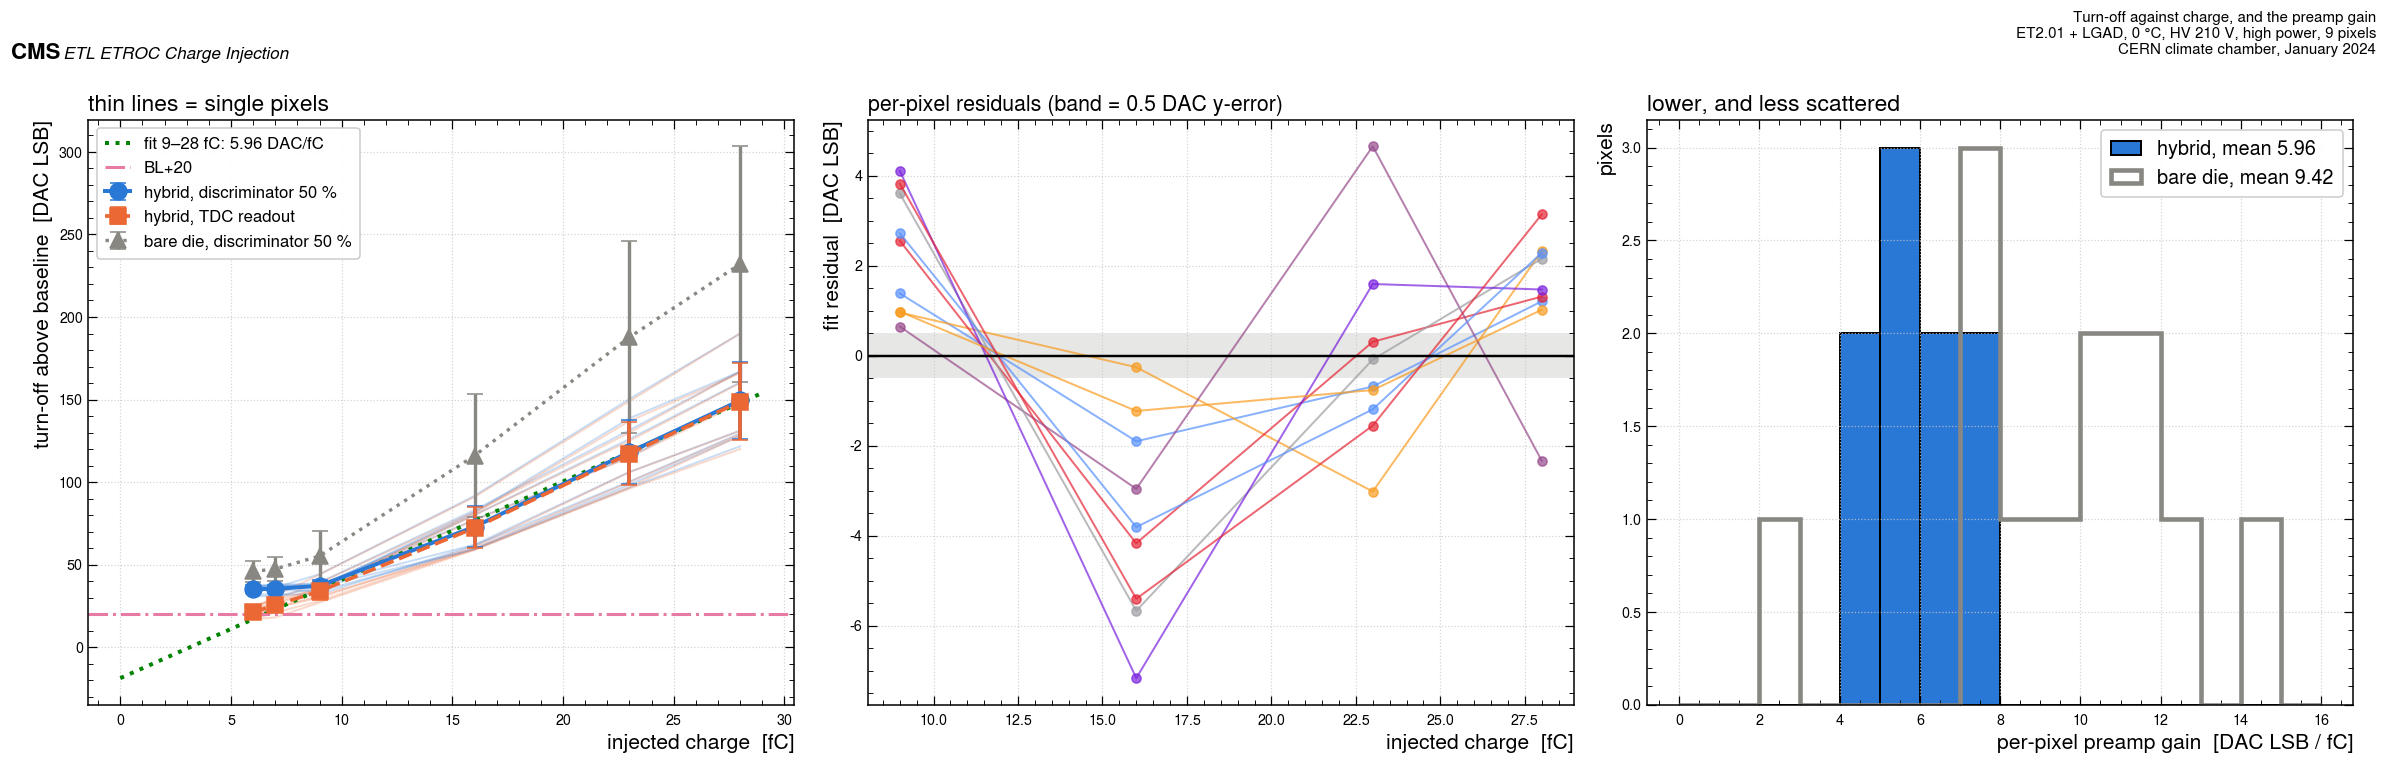

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(21.5, 6.4))
ax = axs[0]
for (r, c), g in tp.groupby(["row", "col"]):
    g = g.sort_values("charge_fC")
    ax.plot(g.charge_fC, g.trig_turnoff_offset, "-", color=Q.C_BLUE, alpha=0.25, lw=1.3)
    ax.plot(g.charge_fC, g.tdc_turnoff_offset, "-", color=Q.C_ORANGE, alpha=0.25, lw=1.3)
po = tp.groupby("charge_fC").agg(trig=("trig_turnoff_offset", "mean"), trig_r=("trig_turnoff_offset", "std"),
                                 tdc=("tdc_turnoff_offset", "mean"), tdc_r=("tdc_turnoff_offset", "std"))
ax.errorbar(po.index, po.trig, yerr=po.trig_r, fmt="o-", ms=11, lw=2.6, color=Q.C_BLUE, capsize=5,
            label="hybrid, discriminator 50 %", zorder=6)
ax.errorbar(po.index, po.tdc, yerr=po.tdc_r, fmt="s--", ms=10, lw=2.4, color=Q.C_ORANGE, capsize=5,
            label="hybrid, TDC readout", zorder=6)
ax.errorbar(Q.CHARGES, [B["turnoff_off_by_charge"][str(c)] for c in Q.CHARGES],
            yerr=[B["turnoff_off_rms_by_charge"][str(c)] for c in Q.CHARGES],
            fmt="^:", ms=10, lw=2.2, color=Q.GREY, capsize=5, label="bare die, discriminator 50 %")
xf = np.linspace(0, 29, 50)
ax.plot(xf, pg["mean"] * xf + pi["mean"], ":", color=Q.C_GREEN, lw=2.6,
        label=f"fit 9–28 fC: {pg['mean']:.2f} DAC/fC")
ax.axhline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2, label="BL+20")
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("turn-off above baseline  [DAC LSB]")
ax.legend(fontsize=11, loc="upper left")
ax.set_title("thin lines = single pixels", loc="left", fontsize=15)

ax = axs[1]
for (r, c), g in tp.groupby(["row", "col"]):
    h = g[g.charge_fC >= 9].sort_values("charge_fC")
    f = GF[(GF.config == PRIMARY) & (GF.row == r) & (GF.col == c)]
    if not len(f) or pd.isna(f.gain_dac_per_fc.iloc[0]):
        continue
    resid = h.trig_turnoff_dac - (f.gain_dac_per_fc.iloc[0] * h.charge_fC + f.intercept_dac.iloc[0])
    ax.plot(h.charge_fC, resid, "o-", ms=6, alpha=0.7, lw=1.3)
ax.axhline(0, color="black", lw=1.6)
ax.axhspan(-0.5, 0.5, color=Q.GREY, alpha=0.2, lw=0)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("fit residual  [DAC LSB]")
ax.set_title("per-pixel residuals (band = 0.5 DAC y-error)", loc="left", fontsize=14)

ax = axs[2]
bins = np.arange(0, 16.1, 1.0)
ax.hist(GF[GF.config == PRIMARY].gain_dac_per_fc.dropna(), bins=bins, color=Q.C_BLUE,
        edgecolor="black", lw=1.3, label=f"hybrid, mean {pg['mean']:.2f}")
bg = pd.read_csv(Q.OUTDIR / "bare_gain_fits.csv")
bg = bg[(bg.dose == 0) & (bg.temp == 12)].gain_dac_per_fc.dropna()
ax.hist(bg, bins=bins, histtype="step", color=Q.GREY, lw=3, label=f"bare die, mean {bg.mean():.2f}")
ax.set_xlabel("per-pixel preamp gain  [DAC LSB / fC]")
ax.set_ylabel("pixels")
ax.legend(fontsize=13)
ax.set_title("lower, and less scattered", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "Turn-off against charge, and the preamp gain",
       tag="ET2.01 + LGAD, 0 °C, HV 210 V, high power, 9 pixels", scale=0.62)
Q.save_fig(fig, "hyb_fig1_turnoff_and_gain")
plt.show()

## 7. The money plot

median CAL 172.25 codes -> one TOA code 18.142 ps, quantisation floor 5.237 ps
[OK  ] TOA LSB                                              recomputed    18.1421  published    18.1421  |d|   0.0000 (tol 0.005) ps
[OK  ] TDC quantisation floor                               recomputed     5.2372  published     5.2372  |d|   0.0000 (tol 0.005) ps
bare die, for comparison: TOA LSB 18.61 ps, floor 5.37 ps


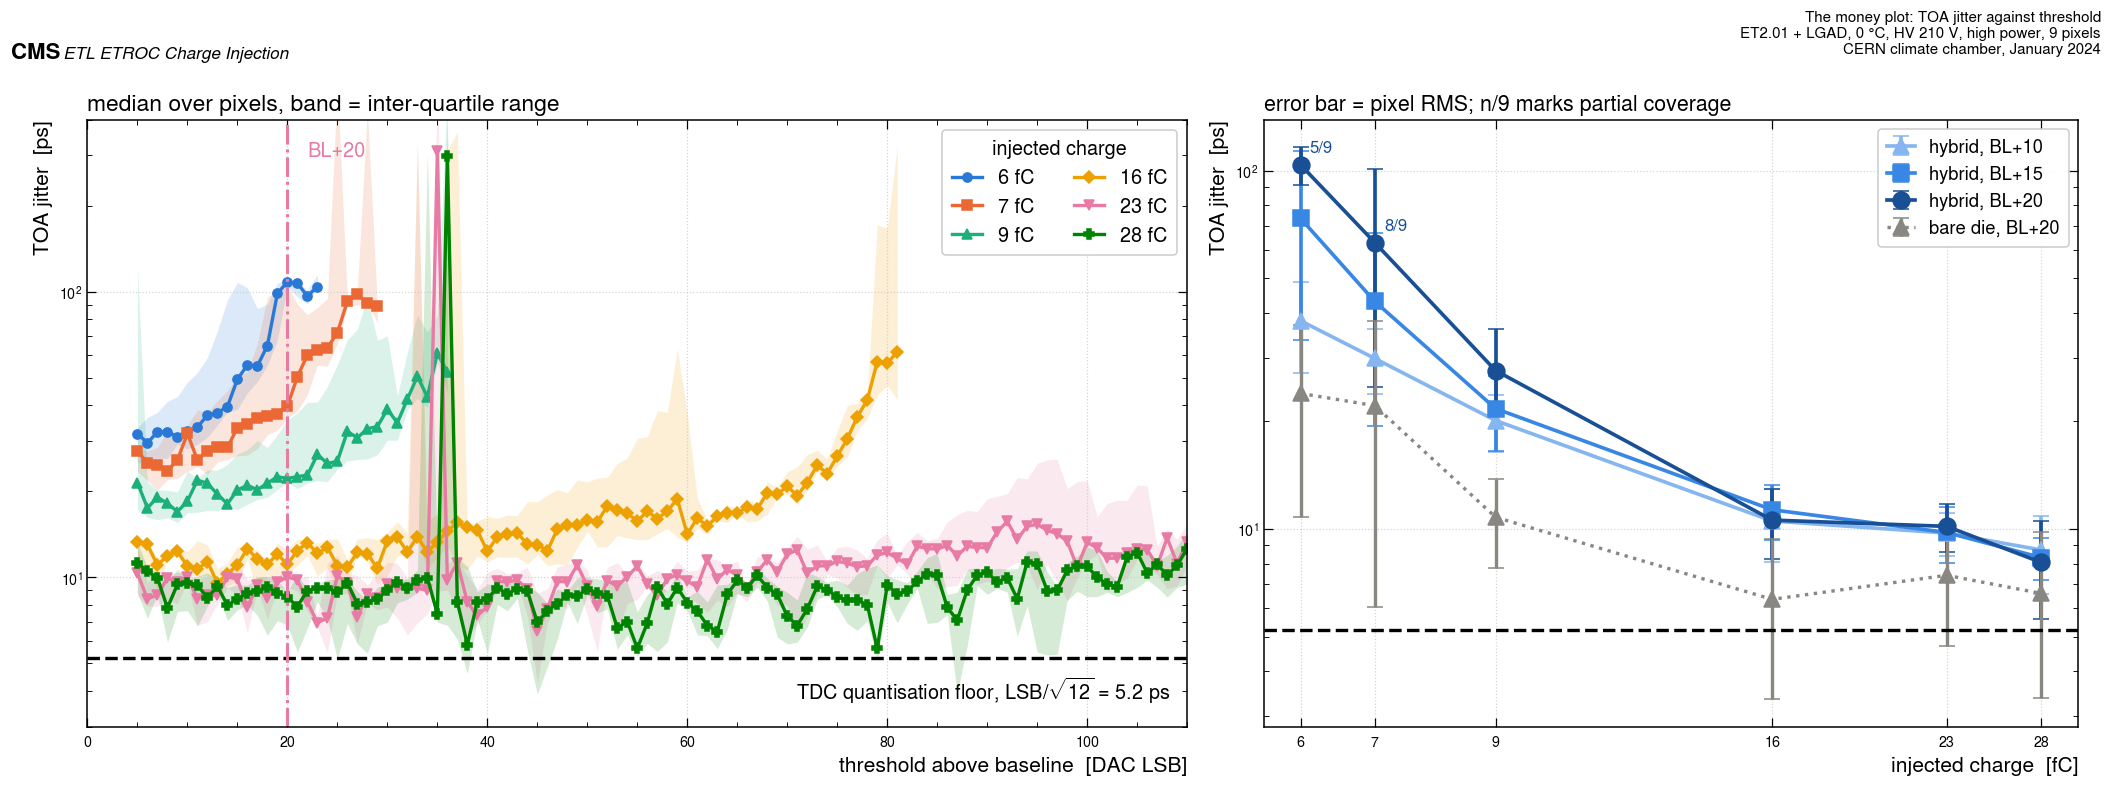


TOA jitter at BL+20 [ps]:
             mean    std  size   bare  hybrid / bare
charge_fC                                           
6          103.70  12.43     5  23.88           4.34
7           62.95  38.11     8  22.07           2.85
9           27.66   8.53     9  10.78           2.57
16          10.58   2.36     9   6.36           1.66
23          10.16   1.54     9   7.42           1.37
28           8.06   2.46     9   6.61           1.22
[OK  ] TOA jitter at BL+20, 6 fC                            recomputed   103.6959  published   103.7000  |d|   0.0041 (tol 0.06) ps
[OK  ] TOA jitter at BL+20, 7 fC                            recomputed    62.9513  published    63.0000  |d|   0.0487 (tol 0.06) ps
[OK  ] TOA jitter at BL+20, 9 fC                            recomputed    27.6587  published    27.7000  |d|   0.0413 (tol 0.06) ps
[OK  ] TOA jitter at BL+20, 16 fC                           recomputed    10.5812  published    10.6000  |d|   0.0188 (tol 0.06) ps
[OK  ] TOA jitter at 

In [15]:
lsb_ps, floor_ps = Q.quantisation_floor_ps(DP.cal_mean.median())
print("median CAL %.2f codes -> one TOA code %.3f ps, quantisation floor %.3f ps"
      % (DP.cal_mean.median(), lsb_ps, floor_ps))
Q.check("TOA LSB", lsb_ps, SN["cal"]["median_lsb_ps"], 0.005, "ps", LEDGER)
Q.check("TDC quantisation floor", floor_ps, SN["quantisation_floor_ps"], 0.005, "ps", LEDGER)
print("bare die, for comparison: TOA LSB %.2f ps, floor %.2f ps" % (B["toa_lsb_ps"], B["quantisation_floor_ps"]))

fig, axs = plt.subplots(1, 2, figsize=(19, 6.6), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axs[0]
for ch in Q.CHARGES:
    sub = DP[DP.charge_fC == ch]
    grp = sub.groupby("offset").jitter_ps
    med, q1, q3, n = grp.median(), grp.quantile(0.25), grp.quantile(0.75), grp.size()
    keep = n >= 3
    ax.plot(med.index[keep], med[keep], "-", marker=Q.CMK[ch], ms=6, lw=2.2, color=Q.CCOL[ch],
            label=f"{ch} fC")
    ax.fill_between(med.index[keep], q1[keep], q3[keep], color=Q.CCOL[ch], alpha=0.16, lw=0)
ax.axhline(floor_ps, color="black", ls="--", lw=2.2)
ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
ax.set_yscale("log")
ax.set_xlim(0, 110)
ax.set_ylim(3, 400)
ax.text(0.985, 0.035, f"TDC quantisation floor, LSB/$\\sqrt{{12}}$ = {floor_ps:.1f} ps",
        transform=ax.transAxes, fontsize=13, ha="right", va="bottom")
ax.text(Q.OP_OFFSET + 2, 0.94, "BL+20", color=Q.C_MAG, fontsize=13, transform=ax.get_xaxis_transform())
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("TOA jitter  [ps]")
ax.legend(title="injected charge", ncol=2, fontsize=13, title_fontsize=13)
ax.set_title("median over pixels, band = inter-quartile range", loc="left", fontsize=15)

ax = axs[1]
jit_off = {}
for off in Q.OFFS:
    p = DP[DP.offset == off].groupby("charge_fC").jitter_ps.agg(["mean", "std", "size"])
    jit_off[off] = p
    ax.errorbar(p.index, p["mean"], yerr=p["std"], fmt="-", marker=Q.OMK[off], ms=11, lw=2.4,
                color=Q.OCOL[off], capsize=5, label=f"hybrid, BL+{off}")
    for ch in p.index:
        if p.loc[ch, "size"] < 9:
            ax.annotate(f"{int(p.loc[ch, 'size'])}/9", (ch, p.loc[ch, "mean"]),
                        textcoords="offset points", xytext=(6, 8), fontsize=11, color=Q.OCOL[off])
ax.errorbar(Q.CHARGES, [B["jitter_off20_by_charge"][str(c)] for c in Q.CHARGES],
            yerr=[B["jitter_off20_rms_by_charge"][str(c)] for c in Q.CHARGES],
            fmt="^:", ms=10, lw=2.2, color=Q.GREY, capsize=5, label="bare die, BL+20")
ax.axhline(floor_ps, color="black", ls="--", lw=2.2)
Q.charge_axis(ax)
ax.set_yscale("log")
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOA jitter  [ps]")
ax.legend(fontsize=12)
ax.set_title("error bar = pixel RMS; n/9 marks partial coverage", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "The money plot: TOA jitter against threshold",
       tag="ET2.01 + LGAD, 0 °C, HV 210 V, high power, 9 pixels", scale=0.62)
Q.save_fig(fig, "hyb_fig2_money_plot")
plt.show()

j20 = jit_off[20]
print("\nTOA jitter at BL+20 [ps]:")
out = j20.copy()
out["bare"] = [B["jitter_off20_by_charge"][str(int(c))] for c in out.index]
out["hybrid / bare"] = (out["mean"] / out.bare).round(2)
print(out.round(2).to_string())
pool_pub = ({int(r["charge_fC"]) + Q.QSEL_LABEL_OFFSET_FC: r for r in SN["pooled_primary"]}   # published keys are QSel labels
            if isinstance(SN["pooled_primary"], list) else {})
for ch, want in zip(Q.CHARGES, [103.7, 63.0, 27.7, 10.6, 10.2, 8.1]):
    Q.check(f"TOA jitter at BL+20, {ch} fC", j20.loc[ch, "mean"], want, 0.06, "ps", LEDGER)

**This is where the sensor becomes visible, and it is at the bottom of the charge range, not
the top.** For 16 fC and above the hybrid sits within a factor of two of the quantisation
floor, exactly as the bare die did: those points are limits, not resolutions, because the
injection is synchronous with the clock and the LGAD is attached but is not generating the
signal. The high-charge branch still cannot be compared with a beam per-board resolution.

At 6, 7 and 9 fC the hybrid is far above the floor **and far above the bare die** — the ratios
in the table above. The bare-die study predicted that "a hybrid showing larger jitter is not a
regression, it is the first time the measurement is above its floor". That is what happened.
The 9 fC point at BL+20 is the lowest charge that is comfortably above the floor, and it is
the number a future scan should be designed around.

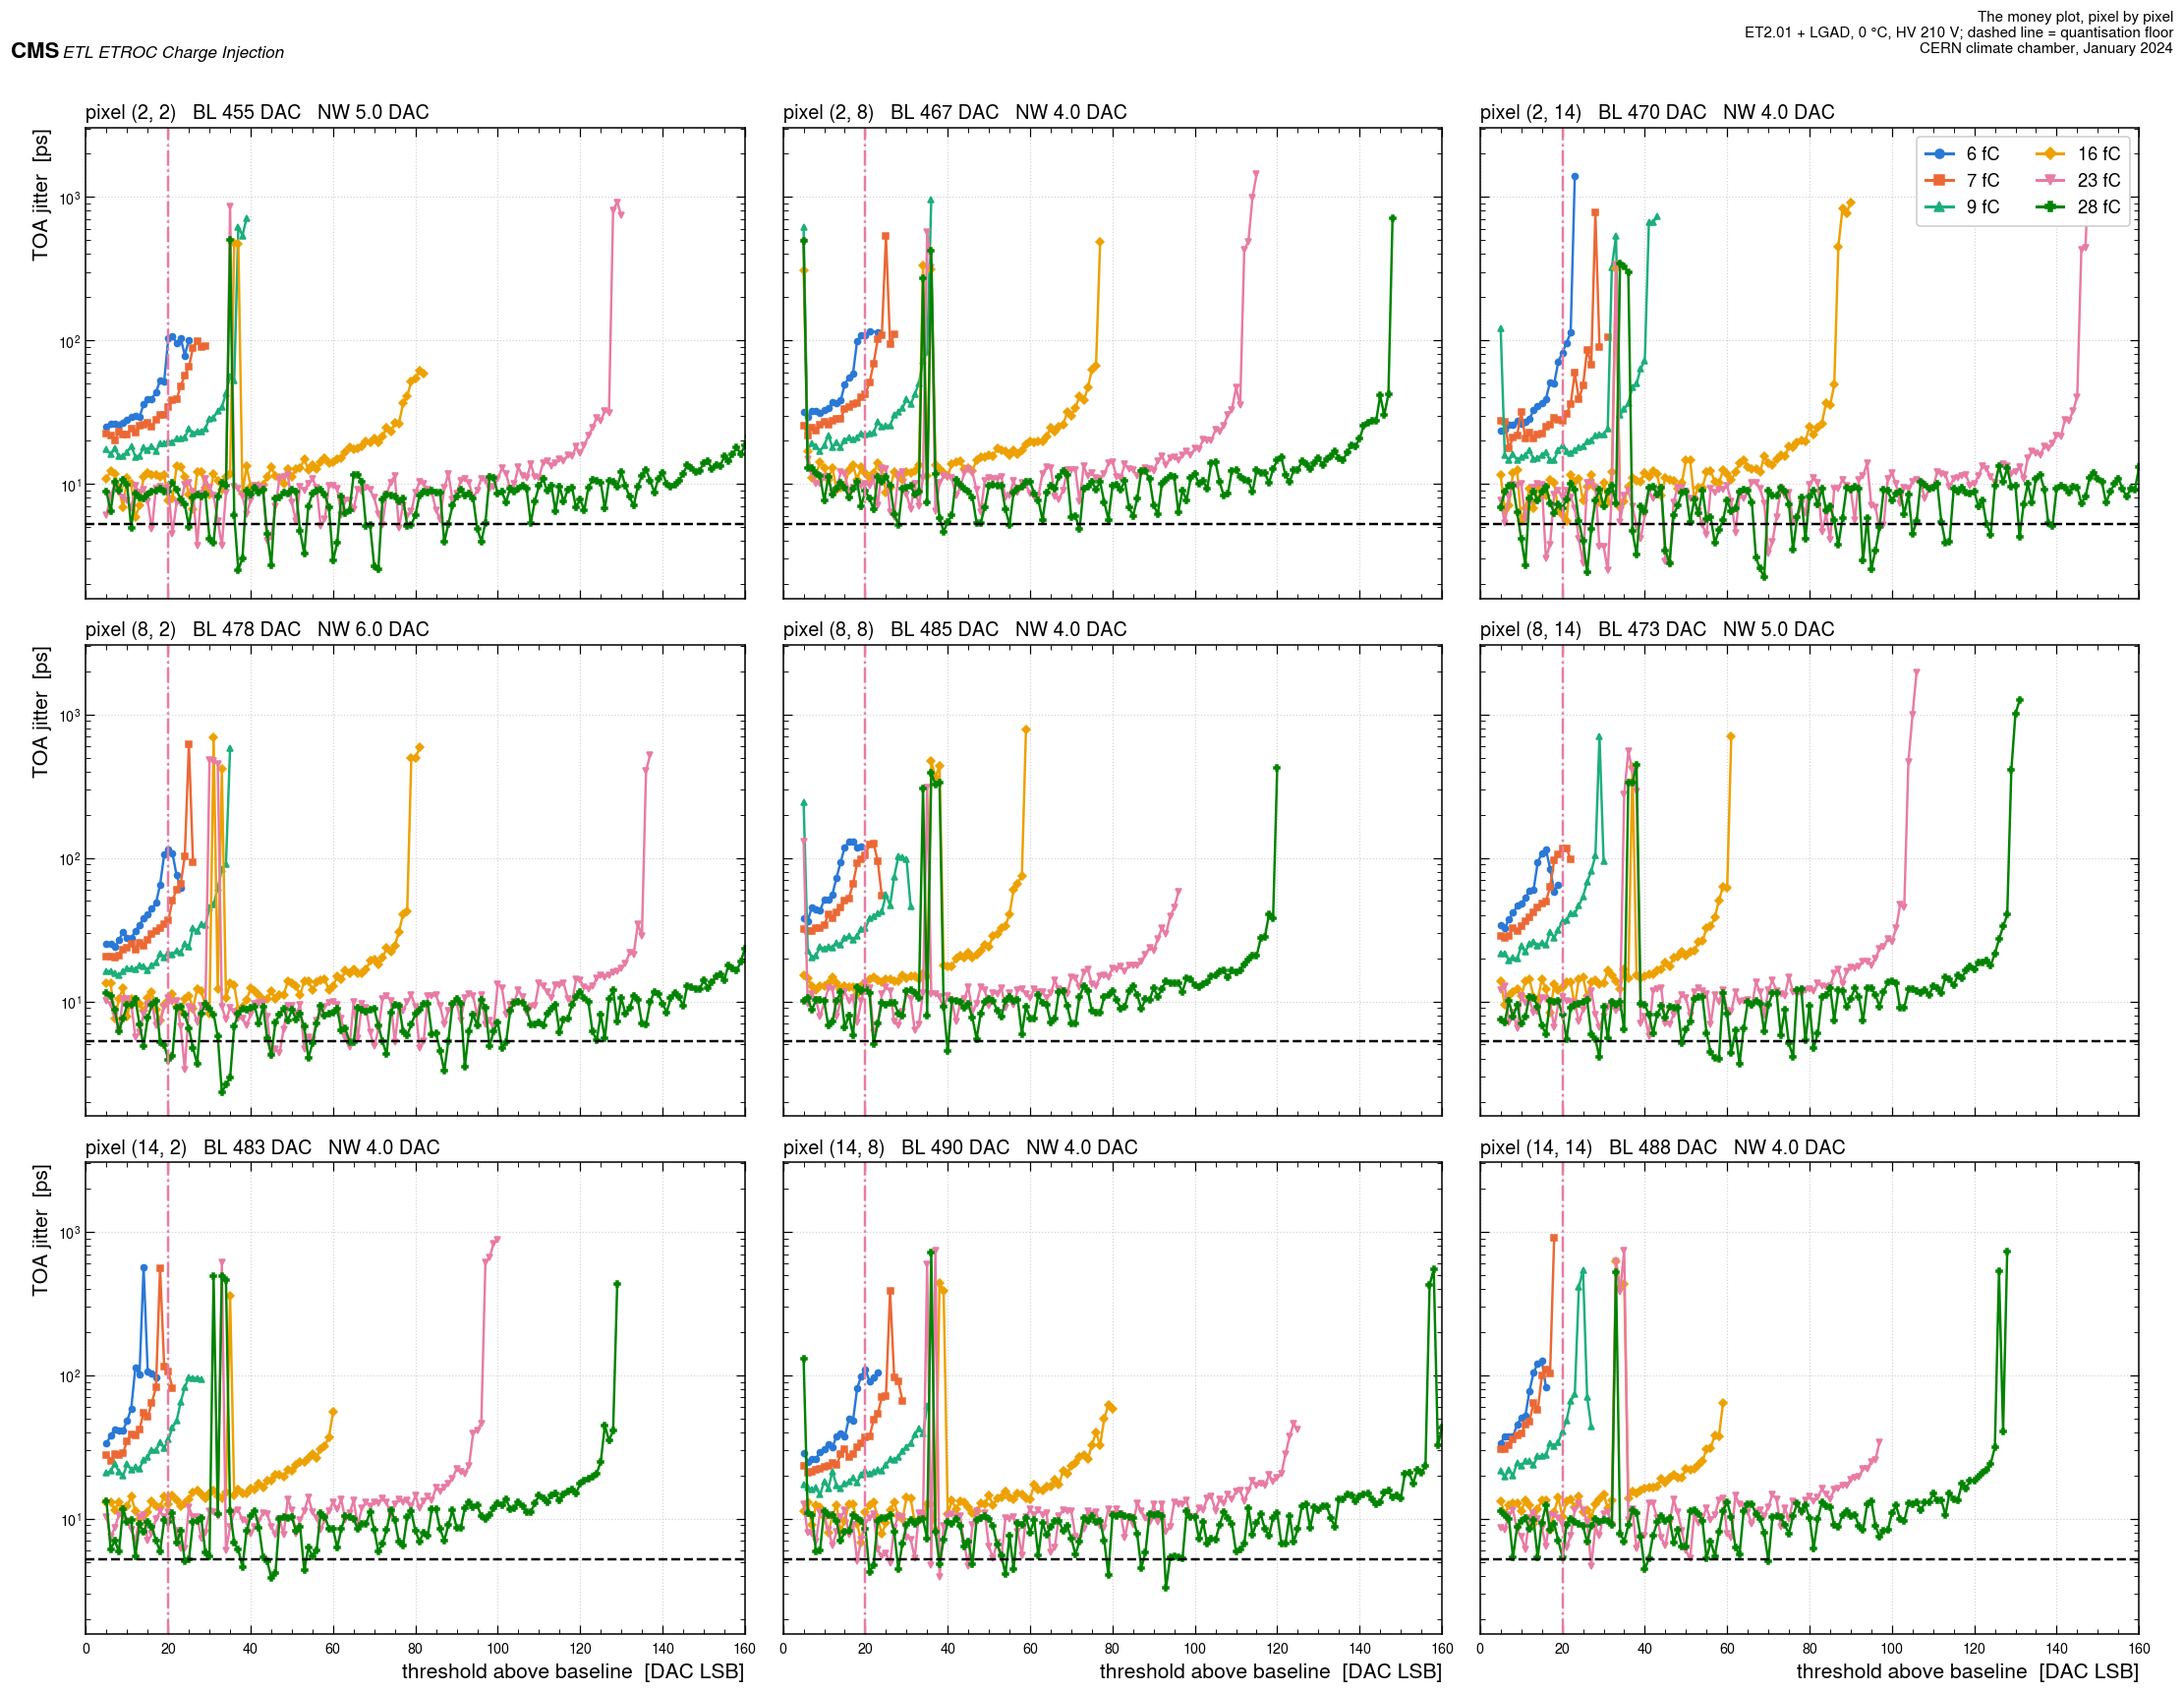

The spikes at the far end of some curves are the points flagged cal_rms > 2 codes;
they sit within a few DAC of turn-off and are flagged, not cut.


In [16]:
fig, axs = plt.subplots(3, 3, figsize=(20, 15), sharex=True, sharey=True)
for ax, ((r, c), g) in zip(axs.ravel(), DP.groupby(["row", "col"])):
    for ch in Q.CHARGES:
        s = g[g.charge_fC == ch].sort_values("offset")
        if len(s) < 2:
            continue
        ax.plot(s.offset, s.jitter_ps, "-", marker=Q.CMK[ch], ms=4, lw=1.6, color=Q.CCOL[ch])
    ax.axhline(floor_ps, color="black", ls="--", lw=1.6)
    ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=1.6)
    ax.set_yscale("log")
    ax.set_title(f"pixel ({r}, {c})   BL {g.BL_dac.iloc[0]:.0f} DAC   NW {g.NW_map_dac.iloc[0]:.1f} DAC",
                 loc="left", fontsize=13)
for ax in axs[-1]:
    ax.set_xlabel("threshold above baseline  [DAC LSB]")
for ax in axs[:, 0]:
    ax.set_ylabel("TOA jitter  [ps]")
axs[0, 0].set_xlim(0, 160)
handles = [plt.Line2D([], [], color=Q.CCOL[c], marker=Q.CMK[c], lw=2, label=f"{c} fC") for c in Q.CHARGES]
axs[0, -1].legend(handles=handles, fontsize=12, ncol=2, loc="upper right")
fig.tight_layout()
Q.fig_header(fig, "The money plot, pixel by pixel",
       tag="ET2.01 + LGAD, 0 °C, HV 210 V; dashed line = quantisation floor", scale=0.62)
Q.save_fig(fig, "hyb_fig3_money_plot_per_pixel")
plt.show()
print("The spikes at the far end of some curves are the points flagged cal_rms > 2 codes;")
print("they sit within a few DAC of turn-off and are flagged, not cut.")

## 8. The threshold edge, ENC, and the capacitance question

The same shared-σ fit as in notebook 01, on the 54 S-curves of the primary configuration.

In [17]:
curves, meta = Q.curves_from(PR[PR.config == PRIMARY], keys=("row", "col", "charge_fC"))
sigma, sigma_sd, mus, _ = Q.scurve_sigma(curves, boot=200)
gain = pg["mean"]
enc = Q.enc_electrons(sigma, gain)
enc_err = enc * np.hypot(sigma_sd / sigma, pg["sem"] / gain)
nw = Q.pooled(BLC[BLC.config == PRIMARY].NW_map_dac)
norms = Q.pooled(BLC[BLC.config == PRIMARY].noise_rms_dac)
print("S-curves fitted        %d  (9 pixels x 6 charges)" % len(curves))
print("shared-sigma fit       sigma = %.3f +- %.3f DAC = %.4f mV" % (sigma, sigma_sd, sigma * Q.LSB_MV))
print("ENC = sigma / (preamp gain)     %.0f +- %.0f electrons" % (enc, enc_err))
print("autocal noise width    NW = %.3f +- %.3f DAC (pixel RMS %.3f)" % (nw["mean"], nw["sem"], nw["rms"]))
print("in-config NoiseOnly    RMS = %.3f +- %.3f DAC" % (norms["mean"], norms["sem"]))
print("NW / sigma             %.3f" % (nw["mean"] / sigma))
Q.check("S-curve width sigma", sigma, SN["sigma"]["dac"], 0.011, "DAC", LEDGER)
Q.check("ENC", enc, SN["enc"]["e"], 2.0, "electrons", LEDGER)
Q.check("autocal noise width NW", nw["mean"], SN["nw"]["map"], 0.01, "DAC", LEDGER)
Q.check("NW / sigma", nw["mean"] / sigma, SN["nw"]["nw_over_sigma"], 0.01, "", LEDGER)

print("\n--- against the bare die, from notebook 01 ---")
print("sigma  hybrid %.3f DAC / bare %.3f DAC  = x %.3f" % (sigma, B["sigma_dac"], sigma / B["sigma_dac"]))
print("preamp gain   hybrid %.3f / bare %.3f          = x %.3f" % (gain, B["gain_dac_per_fc"], gain / B["gain_dac_per_fc"]))
print("ENC    hybrid %.0f e- / bare %.0f e-      = x %.3f" % (enc, B["enc_e"], enc / B["enc_e"]))
print("NW     hybrid %.2f DAC / bare %.2f DAC   = x %.3f" % (nw["mean"], B["nw_dac"], nw["mean"] / B["nw_dac"]))

S-curves fitted        54  (9 pixels x 6 charges)
shared-sigma fit       sigma = 0.930 +- 0.073 DAC = 0.3633 mV
ENC = sigma / (preamp gain)     974 +- 97 electrons
autocal noise width    NW = 4.444 +- 0.242 DAC (pixel RMS 0.726)
in-config NoiseOnly    RMS = 1.149 +- 0.062 DAC
NW / sigma             4.779
[OK  ] S-curve width sigma                                  recomputed     0.9300  published     0.9300  |d|   0.0000 (tol 0.011) DAC
[OK  ] ENC                                                  recomputed   974.4711  published   974.7948  |d|   0.3237 (tol 2) electrons
[OK  ] autocal noise width NW                               recomputed     4.4444  published     4.4444  |d|   0.0000 (tol 0.01) DAC
[OK  ] NW / sigma                                           recomputed     4.7790  published     4.7790  |d|   0.0000 (tol 0.01) 

--- against the bare die, from notebook 01 ---
sigma  hybrid 0.930 DAC / bare 0.920 DAC  = x 1.011
preamp gain   hybrid 5.957 / bare 9.416          = x 0.633
EN

### The headline result, and why it inverts the expectation

The threshold-edge width in DAC is **unchanged** by bonding a sensor — 0.93 against 0.92 DAC,
a ratio of 1.01, well inside the bootstrap error on either. What changed is the **preamp gain**,
which fell to 63 % of the bare value. ENC is the ratio of the two, so the ENC grew by a factor
of about 1.6 **entirely through the preamp gain, not through the noise edge**.

The usual capacitance argument predicts a *wider* threshold edge on a sensor-loaded front end.
Here the edge width in DAC did not move, and the charge-referred noise grew because the
volts-per-fC fell. Referred to charge the front end is noisier; referred to threshold DAC it
is not. Both statements are true and they are not in conflict — but only one of them is what
"the sensor makes it noisier" is usually taken to mean.

In [18]:
sc_rows = []
for cfg in sorted(TOF.config.unique()):
    cv, _ = Q.curves_from(PR[PR.config == cfg], keys=("row", "col", "charge_fC"))
    if len(cv) < 6:
        continue
    s, sd, _, _ = Q.scurve_sigma(cv, boot=120)
    gg = Q.pooled(GF[GF.config == cfg].gain_dac_per_fc)
    nn = Q.pooled(BLC[BLC.config == cfg].NW_map_dac)
    nr = Q.pooled(BLC[BLC.config == cfg].noise_rms_dac)
    sc_rows.append(dict(config=cfg, temperature_C=CFG.loc[cfg, "temperature_C"],
                        hv_state=CFG.loc[cfg, "hv_state"], power_tag=CFG.loc[cfg, "power_tag"],
                        n_pixels=gg["n"], n_curves=len(cv), gain_dac_per_fc=gg["mean"],
                        gain_sem=gg["sem"], gain_pixel_rms=gg["rms"], sigma_dac=s, sigma_sd=sd,
                        ENC_e=Q.enc_electrons(s, gg["mean"]), NW_map=nn["mean"], NW_rms=nn["rms"],
                        noise_rms=nr["mean"], BL_mean=BLC[BLC.config == cfg].BL_dac.mean(),
                        has_sweep=int(CFG.loc[cfg, "n_tdc_dirs"] > 100)))
GB = pd.DataFrame(sc_rows)
GB["T_num"] = pd.to_numeric(GB.temperature_C, errors="coerce")
GB = GB.sort_values(["T_num", "config"], na_position="last")
GB.to_csv(Q.OUTDIR / "hybrid_gain_by_config.csv", index=False)
print(GB[["config", "temperature_C", "hv_state", "power_tag", "n_pixels", "gain_dac_per_fc",
          "gain_sem", "sigma_dac", "ENC_e", "NW_map", "noise_rms", "BL_mean", "has_sweep"]]
      .round(3).to_string(index=False))
print("\nsigma spans %.2f to %.2f DAC across -25 to +22 C and both bias states, while the preamp gain"
      % (GB.sigma_dac.min(), GB.sigma_dac.max()))
print("moves by %.0f %%. Every ENC difference in this table is a preamp gain difference in disguise."
      % (100 * (GB.gain_dac_per_fc.max() / GB.gain_dac_per_fc.min() - 1)))

                                    config temperature_C              hv_state    power_tag  n_pixels  gain_dac_per_fc  gain_sem  sigma_dac    ENC_e  NW_map  noise_rms  BL_mean  has_sweep
                       2024-01-12__m25c_v4           -25          not recorded not recorded         9            6.469     0.431       0.99  955.116   5.444        NaN  531.111          1
                       2024-01-13__m25c_v6           -25          not recorded not recorded         9            6.473     0.433       0.98  944.892   5.667      1.227  533.444          1
                       2024-01-14__m25c_v8           -25          not recorded not recorded         9            6.493     0.431       1.12 1076.698   5.444      1.300  535.667          1
                      2024-01-16__m25c_v10           -25          not recorded not recorded         9            6.479     0.434       0.97  934.411   5.667      1.182  536.889          0
2024-01-16__m25c_v12_HV_off_CablePluggedIn           -25 0 V

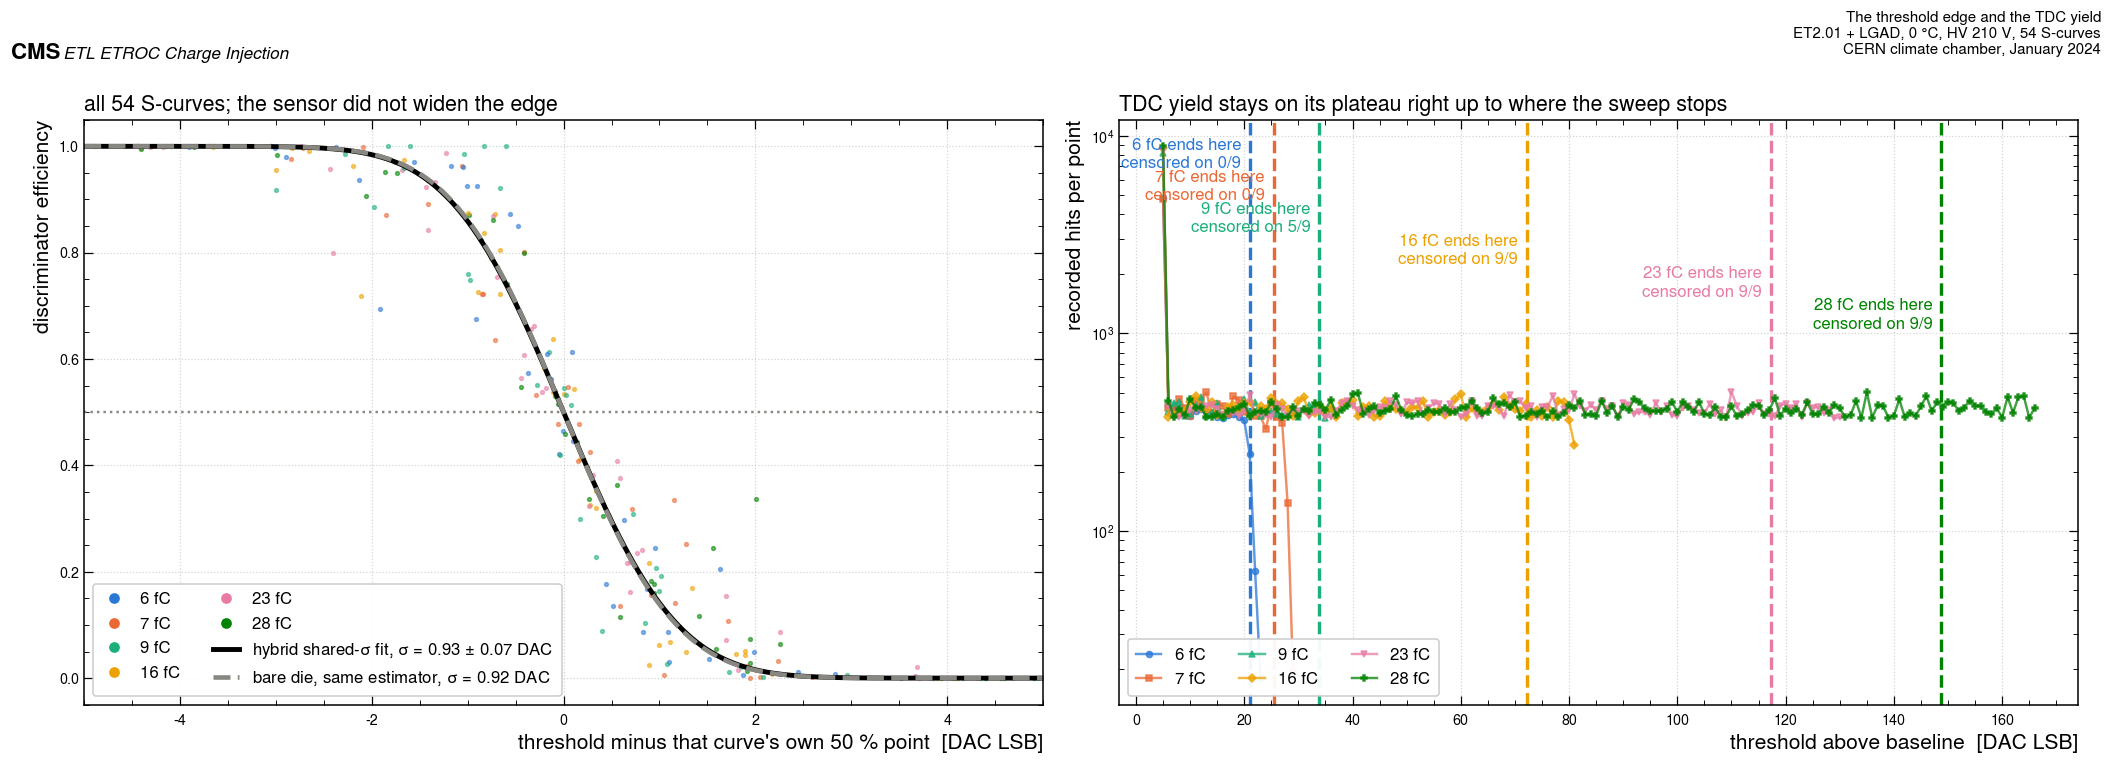

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(19, 6.4))
ax = axs[0]
for (d, f), m, k in zip(curves, mus, meta):
    ax.plot(d - m, f, ".", ms=5, color=Q.CCOL[k[2]], alpha=0.55)
xx = np.linspace(-5, 5, 400)
ax.plot(xx, Q.gauss_cdf(xx, 0.0, sigma), "-", color="black", lw=3.2,
        label=f"hybrid shared-$\\sigma$ fit, $\\sigma$ = {sigma:.2f} $\\pm$ {sigma_sd:.2f} DAC")
ax.plot(xx, Q.gauss_cdf(xx, 0.0, B["sigma_dac"]), "--", color=Q.GREY, lw=3.0,
        label=f"bare die, same estimator, $\\sigma$ = {B['sigma_dac']:.2f} DAC")
ax.axhline(0.5, color=Q.GREY, ls=":", lw=1.6)
ax.set_xlim(-5, 5)
ax.set_xlabel("threshold minus that curve's own 50 % point  [DAC LSB]")
ax.set_ylabel("discriminator efficiency")
handles = [plt.Line2D([], [], color=Q.CCOL[c], marker="o", ls="", label=f"{c} fC") for c in Q.CHARGES]
ax.legend(handles=handles + ax.get_legend_handles_labels()[0], fontsize=11, ncol=2, loc="lower left")
ax.set_title(f"all {len(curves)} S-curves; the sensor did not widen the edge", loc="left", fontsize=14)

ax = axs[1]
for ch in Q.CHARGES:
    sub = DP[DP.charge_fC == ch]
    grp = sub.groupby("offset").n_hits
    med, n = grp.median(), grp.size()
    keep = n >= 3
    ax.plot(med.index[keep], med[keep], "-", marker=Q.CMK[ch], ms=4, lw=1.6, color=Q.CCOL[ch],
            alpha=0.75, label=f"{ch} fC")
    tt = tp[tp.charge_fC == ch]
    ax.axvline(tt.tdc_turnoff_offset.mean(), color=Q.CCOL[ch], ls="--", lw=2.2)
    ax.annotate(f"{ch} fC ends here\ncensored on {int(tt.tdc_turnoff_censored.sum())}/9",
                (tt.tdc_turnoff_offset.mean(), 0.97 - 0.055 * Q.CHARGES.index(ch)),
                xycoords=ax.get_xaxis_transform(), textcoords="offset points", xytext=(-6, 0),
                ha="right", va="top", fontsize=11, color=Q.CCOL[ch])
ax.set_yscale("log")
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("recorded hits per point")
ax.legend(fontsize=11, ncol=3, loc="lower left")
ax.set_title("TDC yield stays on its plateau right up to where the sweep stops", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "The threshold edge and the TDC yield",
       tag="ET2.01 + LGAD, 0 °C, HV 210 V, 54 S-curves", scale=0.62)
Q.save_fig(fig, "hyb_fig4_scurves")
plt.show()

## 9. Time over threshold — the largest unexplained difference

In [20]:
tot_rows = []
for off in Q.OFFS:
    for ch, g in DP[DP.offset == off].groupby("charge_fC"):
        p, pn = Q.pooled(g.tot_mean), Q.pooled(g.tot_ns)
        tot_rows.append(dict(offset=off, charge_fC=ch, tot_code_mean=p["mean"],
                             tot_code_pixel_rms=p["rms"], tot_code_sem=p["sem"],
                             tot_ns_mean=pn["mean"], tot_ns_pixel_rms=pn["rms"], n_pixels=p["n"]))
TOT = pd.DataFrame(tot_rows)
TOT.to_csv(Q.OUTDIR / "hybrid_tot_vs_charge_offsets.csv", index=False)
t20 = TOT[TOT.offset == 20].set_index("charge_fC")
t20["bare_tot_code"] = [B["tot_off20_by_charge"][str(int(c))] for c in t20.index]
t20["hybrid / bare"] = (t20.tot_code_mean / t20.bare_tot_code).round(2)
print(t20[["tot_code_mean", "tot_code_pixel_rms", "tot_ns_mean", "n_pixels",
           "bare_tot_code", "hybrid / bare"]].round(2).to_string())

fits = {}
for off in Q.OFFS:
    s = TOT[(TOT.offset == off) & (TOT.n_pixels >= 2)].sort_values("charge_fC")
    a, b_, ae, be, c2, res = Q.logfit(s.charge_fC, s.tot_code_mean, s.tot_code_sem)
    fits[off] = dict(a=a, b=b_, chi2_ndf=c2, res=dict(zip(s.charge_fC.astype(int), res.round(2))))
    print("\nBL+%d:  TOT = %.2f + %.2f ln(Q/fC),  chi2/ndf %.2f" % (off, a, b_, c2))
    print("        residuals [code]:", fits[off]["res"])
Q.check("TOT at BL+20, 16 fC", t20.loc[16, "tot_code_mean"], 84.9, 0.06, "code", LEDGER)
# The published log laws were fitted in ln of the QSel label; ln Q is not shift-invariant, so the
# ledger refits on the label axis to check reproduction, and the physical law above is what is quoted.
fits_label = {}
for off in Q.OFFS:
    s = TOT[(TOT.offset == off) & (TOT.n_pixels >= 2)].sort_values("charge_fC")
    a, b_, _, _, c2, _ = Q.logfit(s.charge_fC - Q.QSEL_LABEL_OFFSET_FC, s.tot_code_mean, s.tot_code_sem)
    fits_label[off] = dict(a=a, b=b_, chi2_ndf=c2)
print("\nBL+20 on the QSel-label axis (as published): TOT = %.2f + %.2f ln(label), chi2/ndf %.2f"
      % (fits_label[20]["a"], fits_label[20]["b"], fits_label[20]["chi2_ndf"]))
Q.check("TOT log law intercept a at BL+20, QSel-label axis", fits_label[20]["a"], SN["tot_fit_off20"]["a"], 0.02, "code", LEDGER)
Q.check("TOT log law slope b at BL+20, QSel-label axis", fits_label[20]["b"], SN["tot_fit_off20"]["b"], 0.02, "code", LEDGER)
Q.check("TOT log law chi2/ndf at BL+20, QSel-label axis", fits_label[20]["chi2_ndf"], SN["tot_fit_off20"]["chi2_ndf"], 0.02, "", LEDGER)
for off in (10, 15):
    Q.check(f"TOT log law chi2/ndf at BL+{off}, QSel-label axis", fits_label[off]["chi2_ndf"],
            SN["tot_fits_other"][f"{PRIMARY}|off{off}"]["chi2_ndf"], 0.02, "", LEDGER)

           tot_code_mean  tot_code_pixel_rms  tot_ns_mean  n_pixels  bare_tot_code  hybrid / bare
charge_fC                                                                                        
6                  24.14                4.52         0.87         5          26.85           0.90
7                  40.93               12.61         1.46         8          32.02           1.28
9                  60.03               11.05         2.15         9          41.83           1.44
16                 84.94                6.37         3.04         9          49.87           1.70
23                 94.38                6.03         3.38         9          52.29           1.81
28                 97.73                5.51         3.50         9          53.40           1.83

BL+10:  TOT = 19.85 + 27.42 ln(Q/fC),  chi2/ndf 2.73
        residuals [code]: {6: np.float64(-6.45), 7: np.float64(-1.45), 9: np.float64(3.95), 16: np.float64(4.82), 23: np.float64(0.88), 28: np.float64(-2.81)}

BL

**TOT did not transfer, and the campaign cannot say why.** At BL+20 the hybrid sits at about
1.7 to 1.8 times the bare TOT above 9 fC, and the bare chip's well-behaved
`16.6 + 11.4 ln(Q/fC)` is replaced by a much steeper, badly fitting law with χ²/ndf near 10
and residuals reaching +11 codes. The fit is progressively better further down the edge —
χ²/ndf 4.2 at BL+15 and 2.7 at BL+10 — so the poor fit at BL+20 is a real change of shape near the
operating point, not a fitting artefact.

The bare-die study listed TOT-versus-charge as "expected to transfer". It does not. But this
**cannot be attributed to the sensor**: RFSel sets the preamplifier feedback resistance and
therefore directly sets TOT, and RFSel is **not recorded on either data set**. A different
RFSel would produce exactly this signature. The honest statement is that TOT-versus-charge did
not transfer and the cause is not determinable from what was recorded.

One thing does improve: these values are much closer to beam data, where hits sit near TOT
code 135, than the bare chip's were. Closer, still not the same part of the curve.

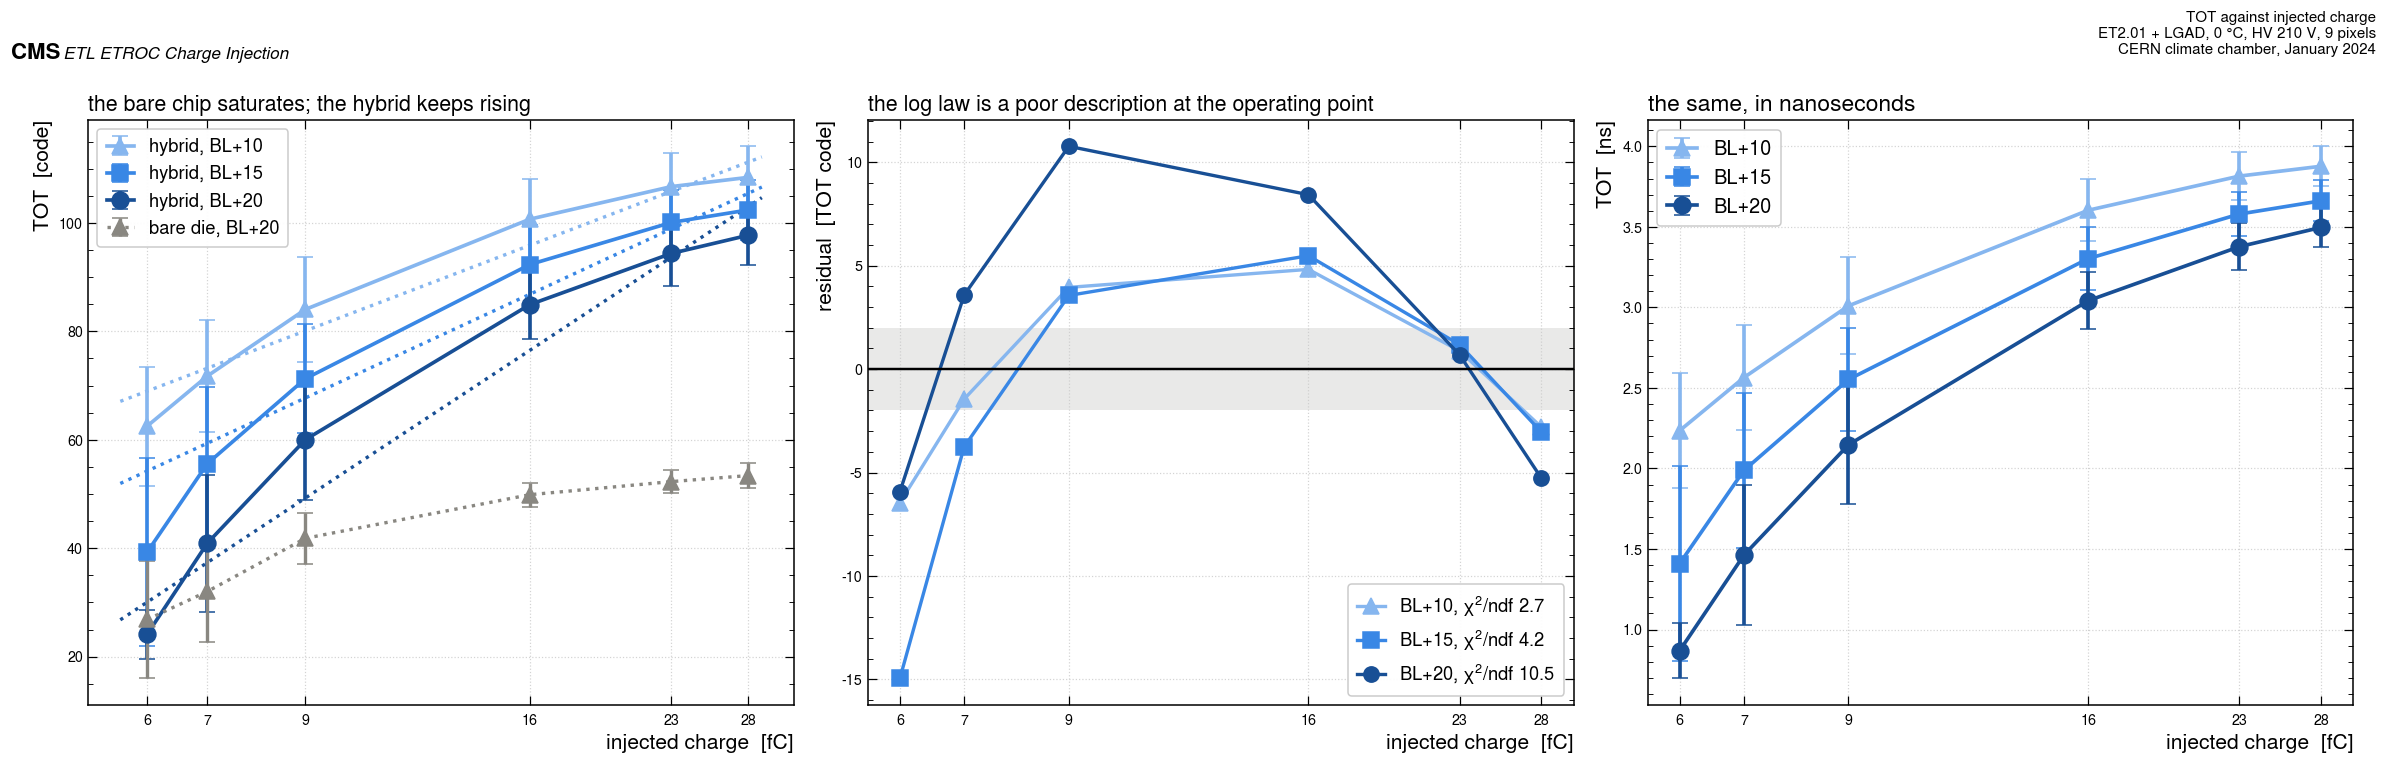

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(21.5, 6.4))
ax = axs[0]
for off in Q.OFFS:
    s = TOT[TOT.offset == off].sort_values("charge_fC")
    ax.errorbar(s.charge_fC, s.tot_code_mean, yerr=s.tot_code_pixel_rms, fmt="-", marker=Q.OMK[off],
                ms=11, lw=2.4, color=Q.OCOL[off], capsize=5, label=f"hybrid, BL+{off}")
    qq = np.linspace(5.6, 29, 200)
    ax.plot(qq, fits[off]["a"] + fits[off]["b"] * np.log(qq), ":", color=Q.OCOL[off], lw=2.2)
ax.errorbar(Q.CHARGES, [B["tot_off20_by_charge"][str(c)] for c in Q.CHARGES],
            yerr=[B["tot_off20_rms_by_charge"][str(c)] for c in Q.CHARGES],
            fmt="^:", ms=10, lw=2.2, color=Q.GREY, capsize=5, label="bare die, BL+20")
Q.charge_axis(ax)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT  [code]")
ax.legend(fontsize=12)
ax.set_title("the bare chip saturates; the hybrid keeps rising", loc="left", fontsize=14)

ax = axs[1]
for off in Q.OFFS:
    ax.plot(list(fits[off]["res"].keys()), list(fits[off]["res"].values()), "-", marker=Q.OMK[off],
            ms=10, lw=2.2, color=Q.OCOL[off],
            label=f"BL+{off}, $\\chi^2$/ndf {fits[off]['chi2_ndf']:.1f}")
ax.axhline(0, color="black", lw=1.6)
ax.axhspan(-2, 2, color=Q.GREY, alpha=0.18, lw=0)
Q.charge_axis(ax)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("residual  [TOT code]")
ax.legend(fontsize=12)
ax.set_title("the log law is a poor description at the operating point", loc="left", fontsize=14)

ax = axs[2]
for off in Q.OFFS:
    s = TOT[TOT.offset == off].sort_values("charge_fC")
    ax.errorbar(s.charge_fC, s.tot_ns_mean, yerr=s.tot_ns_pixel_rms, fmt="-", marker=Q.OMK[off],
                ms=11, lw=2.4, color=Q.OCOL[off], capsize=5, label=f"BL+{off}")
Q.charge_axis(ax)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT  [ns]")
ax.legend(fontsize=13)
ax.set_title("the same, in nanoseconds", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "TOT against injected charge",
       tag="ET2.01 + LGAD, 0 °C, HV 210 V, 9 pixels", scale=0.62)
Q.save_fig(fig, "hyb_fig5_tot_vs_charge")
plt.show()

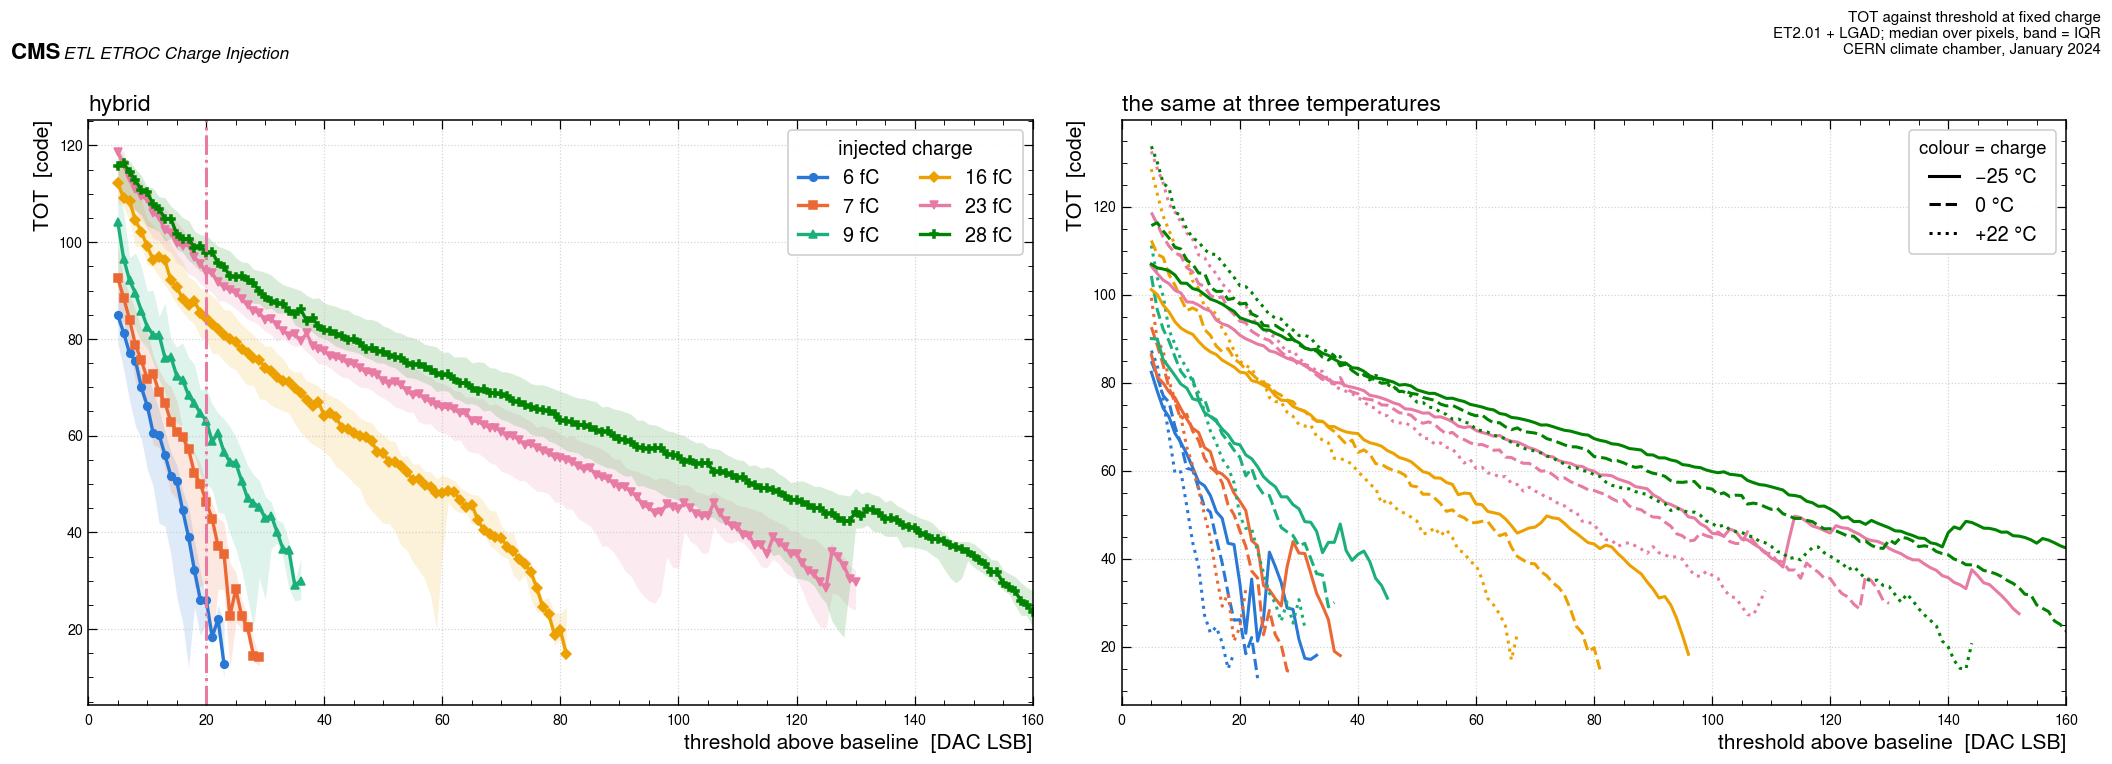

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(19, 6.4))
ax = axs[0]
for ch in Q.CHARGES:
    sub = DP[DP.charge_fC == ch]
    grp = sub.groupby("offset").tot_mean
    med, q1, q3, n = grp.median(), grp.quantile(0.25), grp.quantile(0.75), grp.size()
    keep = n >= 3
    ax.plot(med.index[keep], med[keep], "-", marker=Q.CMK[ch], ms=5, lw=2.2, color=Q.CCOL[ch],
            label=f"{ch} fC")
    ax.fill_between(med.index[keep], q1[keep], q3[keep], color=Q.CCOL[ch], alpha=0.15, lw=0)
ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
ax.set_xlim(0, 160)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("TOT  [code]")
ax.legend(title="injected charge", ncol=2, fontsize=13, title_fontsize=13)
ax.set_title("hybrid", loc="left", fontsize=15)

ax = axs[1]
for ch in Q.CHARGES:
    for cfg, ls, lab in [(CFG_M25, "-", "−25 °C"), (PRIMARY, "--", "0 °C"), (CFG_22, ":", "+22 °C")]:
        sub = D[(D.config == cfg) & (D.charge_fC == ch)]
        if not len(sub):
            continue
        m = sub.groupby("offset").tot_mean.median()
        n = sub.groupby("offset").size()
        ax.plot(m.index[n >= 3], m[n >= 3], ls, lw=2.0, color=Q.CCOL[ch])
ax.set_xlim(0, 160)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("TOT  [code]")
h = [plt.Line2D([], [], color="black", ls=ls, lw=2, label=lab)
     for ls, lab in [("-", "−25 °C"), ("--", "0 °C"), (":", "+22 °C")]]
ax.legend(handles=h, fontsize=13, title="colour = charge", title_fontsize=12)
ax.set_title("the same at three temperatures", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "TOT against threshold at fixed charge",
       tag="ET2.01 + LGAD; median over pixels, band = IQR", scale=0.62)
Q.save_fig(fig, "hyb_fig6_tot_vs_threshold")
plt.show()

## 10. Time walk and CAL

In [23]:
walk_thr, walk_full = [], []
for (r, c, q), g in DP.groupby(["row", "col", "charge_fC"]):
    g = g.set_index("offset")
    if 5 in g.index and 20 in g.index:
        walk_thr.append((g.loc[20, "toa_ns"] - g.loc[5, "toa_ns"]) * 1e3)
    if len(g) > 3:
        walk_full.append((g.toa_ns.iloc[-1] - g.toa_ns.iloc[0]) * 1e3)
w20_mean = DP[DP.offset == 20].groupby("charge_fC").toa_ns.mean() * 1e3
w20_med = DP[DP.offset == 20].groupby("charge_fC").toa_ns.median() * 1e3
print("walk with threshold, BL+5 -> BL+20, per (pixel, charge): min %.0f, max %.0f, median %.0f ps"
      % (np.nanmin(walk_thr), np.nanmax(walk_thr), np.nanmedian(walk_thr)))
print("  bare die, same quantity computed on the pooled curve: -146 to +17 ps")
print("walk with charge at BL+20, 6 -> 28 fC: %+.0f ps (mean over pixels), %+.0f ps (median)"
      % (w20_mean[28] - w20_mean[6], w20_med[28] - w20_med[6]))
print("  9 -> 28 fC, excluding the marginal 6 fC point: %+.0f ps" % (w20_mean[28] - w20_mean[9]))
print("  bare die, 6 -> 28 fC at BL+20: %+.0f ps" % B["walk_charge_6to28_at_off20_ps"])
# published under the QSel-label names 5to27 and 8to27: the same points
Q.check("walk with charge, 6->28 fC at BL+20", w20_mean[28] - w20_mean[6],
        SN["walk_charge_5to27_at_off20_ps"], 1.0, "ps", LEDGER)
Q.check("walk with charge, 9->28 fC at BL+20", w20_mean[28] - w20_mean[9],
        SN["walk_charge_8to27_at_off20_ps"], 1.0, "ps", LEDGER)
Q.check("walk with threshold, minimum", float(np.nanmin(walk_thr)), SN["walk_thr_5to20_ps"]["min"], 1.0, "ps", LEDGER)
Q.check("walk with threshold, median", float(np.nanmedian(walk_thr)), SN["walk_thr_5to20_ps"]["median"], 1.0, "ps", LEDGER)

print("\nCAL: min %.2f, max %.2f, median %.2f codes; median per-point RMS %.3f codes (%.2f %%)"
      % (DP.cal_mean.min(), DP.cal_mean.max(), DP.cal_mean.median(), DP.cal_std.median(),
         100 * DP.cal_std.median() / DP.cal_mean.median()))
print("points outside the pipeline guard band %s: %d of %d"
      % (Q.CAL_GUARD, int(((DP.cal_mean < Q.CAL_GUARD[0]) | (DP.cal_mean > Q.CAL_GUARD[1])).sum()), len(DP)))
Q.check("median per-point CAL RMS", DP.cal_std.median(), SN["cal"]["median_point_rms"], 0.005, "code", LEDGER)
Q.check("fraction of points with CAL RMS > 2 codes", DP.cal_rms_gt2.mean(),
        SN["cal"]["frac_points_cal_rms_gt2"], 0.002, "", LEDGER)

walk with threshold, BL+5 -> BL+20, per (pixel, charge): min -819, max -79, median -172 ps
  bare die, same quantity computed on the pooled curve: -146 to +17 ps
walk with charge at BL+20, 6 -> 28 fC: +1384 ps (mean over pixels), +1317 ps (median)
  9 -> 28 fC, excluding the marginal 6 fC point: +721 ps
  bare die, 6 -> 28 fC at BL+20: +493 ps
[OK  ] walk with charge, 6->28 fC at BL+20                  recomputed  1383.6604  published  1383.6604  |d|   0.0000 (tol 1) ps
[OK  ] walk with charge, 9->28 fC at BL+20                  recomputed   720.9204  published   720.9204  |d|   0.0000 (tol 1) ps
[OK  ] walk with threshold, minimum                         recomputed  -819.2097  published  -819.2097  |d|   0.0000 (tol 1) ps
[OK  ] walk with threshold, median                          recomputed  -171.5335  published  -171.5335  |d|   0.0000 (tol 1) ps

CAL: min 164.29, max 196.93, median 172.25 codes; median per-point RMS 0.459 codes (0.27 %)
points outside the pipeline guard band (100, 

np.True_

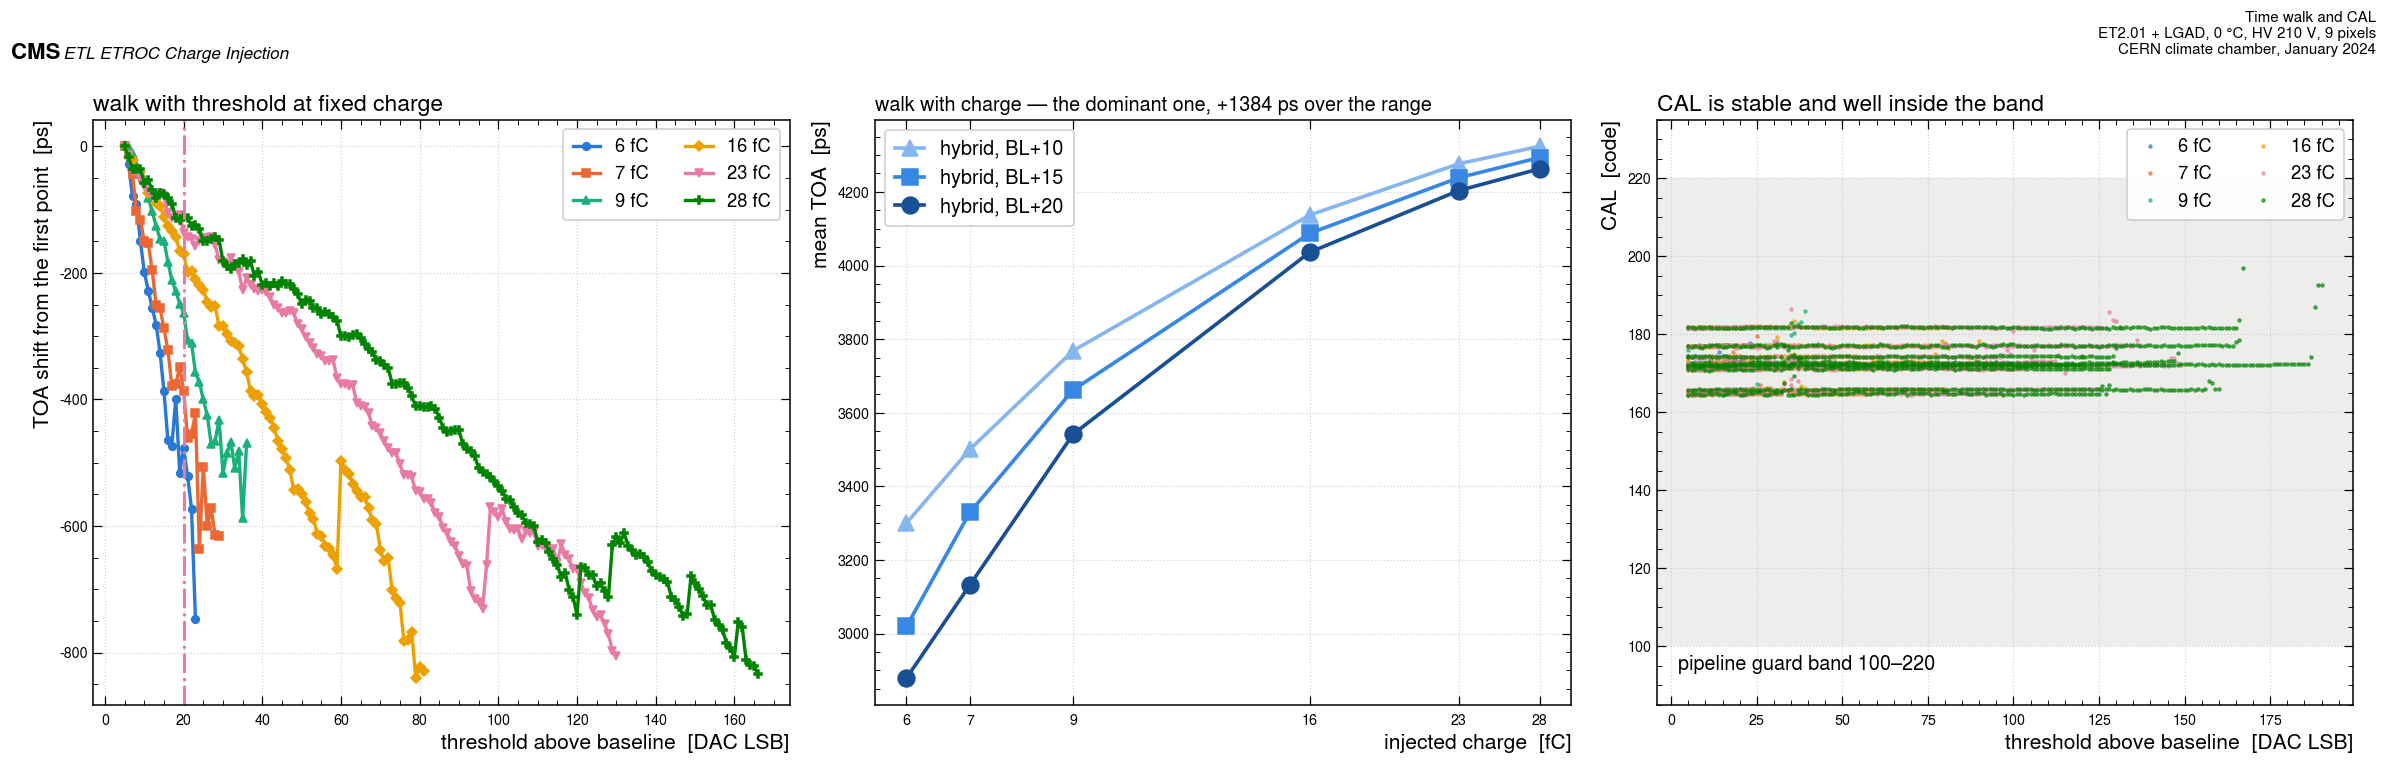

In [24]:
fig, axs = plt.subplots(1, 3, figsize=(21.5, 6.4))
ax = axs[0]
for ch in Q.CHARGES:
    sub = DP[DP.charge_fC == ch]
    m = sub.groupby("offset").toa_ns.median() * 1e3
    n = sub.groupby("offset").size()
    keep = n >= 3
    ax.plot(m.index[keep], m[keep] - m[keep].iloc[0], "-", marker=Q.CMK[ch], ms=5, lw=2.2,
            color=Q.CCOL[ch], label=f"{ch} fC")
ax.axvline(Q.OP_OFFSET, color=Q.C_MAG, ls="-.", lw=2)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("TOA shift from the first point  [ps]")
ax.legend(fontsize=12, ncol=2)
ax.set_title("walk with threshold at fixed charge", loc="left", fontsize=15)

ax = axs[1]
for off in Q.OFFS:
    s = DP[DP.offset == off].groupby("charge_fC").toa_ns.mean() * 1e3
    ax.plot(s.index, s.values, "-", marker=Q.OMK[off], ms=11, lw=2.4, color=Q.OCOL[off],
            label=f"hybrid, BL+{off}")
Q.charge_axis(ax)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("mean TOA  [ps]")
ax.legend(fontsize=13)
ax.set_title("walk with charge — the dominant one, +1384 ps over the range", loc="left", fontsize=13)

ax = axs[2]
for ch in Q.CHARGES:
    sub = DP[DP.charge_fC == ch]
    ax.plot(sub.offset, sub.cal_mean, ".", ms=4, color=Q.CCOL[ch], alpha=0.6, label=f"{ch} fC")
ax.axhspan(*Q.CAL_GUARD, color=Q.GREY, alpha=0.15, lw=0)
ax.set_ylim(min(Q.CAL_GUARD) - 15, max(Q.CAL_GUARD) + 15)
ax.set_xlabel("threshold above baseline  [DAC LSB]")
ax.set_ylabel("CAL  [code]")
ax.text(0.03, 0.06, "pipeline guard band 100–220", transform=ax.transAxes, fontsize=13)
ax.legend(fontsize=12, ncol=2, loc="upper right")
ax.set_title("CAL is stable and well inside the band", loc="left", fontsize=15)
fig.tight_layout()
Q.fig_header(fig, "Time walk and CAL", tag="ET2.01 + LGAD, 0 °C, HV 210 V, 9 pixels", scale=0.62)
Q.save_fig(fig, "hyb_fig7_walk_and_cal")
plt.show()

The threshold walk is substantially larger here than on the bare die — a median of about
−170 ps over BL+5 to BL+20, against a few tens of picoseconds on the pooled bare curve. A
few-DAC threshold error is no longer cheap on a hybrid. The charge walk is larger too,
+1384 ps from 6 to 28 fC against +493 ps bare, and it is measured against a *known* injected
charge, which is exactly the handle beam data does not have.

## 11. The bias bracket and the temperature series

The bare-versus-hybrid comparison in the next section cannot be clean: chip, temperature, bias
and pixel set all differ at once. The campaign does contain one comparison that **is** clean.
On 2024-01-16, the same nine pixels, the same temperature, hours apart, the bias supply was
turned down to 0 V with the sensor cable still connected. That is a **depletion bracket**: the
LGAD is still bonded and still loading the preamplifier input, and an undepleted LGAD presents
a *larger* capacitance than a depleted one.

In [25]:
br = GB.set_index("config").loc[[CFG_HVREF, CFG_HV0]]
bracket = pd.DataFrame({
    "preamp gain [DAC/fC]": br.gain_dac_per_fc, "sigma [DAC]": br.sigma_dac,
    "ENC [e-]": br.ENC_e, "NoiseOnly RMS [DAC]": br.noise_rms, "BL [DAC]": br.BL_mean})
bracket.loc["ratio (HV 0 V / reference)"] = bracket.iloc[1] / bracket.iloc[0]
bracket.index = ["m25c_v10, HV not recorded", "m25c_v12, HV 0 V, cable plugged in",
                 "ratio (HV 0 V / reference)"]
print(bracket.round(3).to_string())
Q.check("bias bracket, preamp gain ratio", bracket.iloc[2]["preamp gain [DAC/fC]"],
        br.gain_dac_per_fc.iloc[1] / br.gain_dac_per_fc.iloc[0], 1e-9, "", LEDGER)
print("\ngain x %.3f, sigma x %.3f, ENC x %.3f -- the sign and the size the capacitance argument"
      % (bracket.iloc[2]["preamp gain [DAC/fC]"], bracket.iloc[2]["sigma [DAC]"], bracket.iloc[2]["ENC [e-]"]))
print("predicts, free of every confound that limits the bare-versus-hybrid comparison.")
print("\nIt also settles, by measurement rather than by naming, that m25c_v10 was NOT at 0 V --")
print("the only handle anywhere on the bias state of the -25 C series.")

                                    preamp gain [DAC/fC]  sigma [DAC]  ENC [e-]  NoiseOnly RMS [DAC]  BL [DAC]
m25c_v10, HV not recorded                          6.479        0.970   934.411                1.182   536.889
m25c_v12, HV 0 V, cable plugged in                 5.792        1.160  1249.920                1.254   536.889
ratio (HV 0 V / reference)                         0.894        1.196     1.338                1.061     1.000
[OK  ] bias bracket, preamp gain ratio                      recomputed     0.8940  published     0.8940  |d|   0.0000 (tol 1e-09) 

gain x 0.894, sigma x 1.196, ENC x 1.338 -- the sign and the size the capacitance argument
predicts, free of every confound that limits the bare-versus-hybrid comparison.

It also settles, by measurement rather than by naming, that m25c_v10 was NOT at 0 V --
the only handle anywhere on the bias state of the -25 C series.


**What the tag does and does not mean.** `HV_off_CablePluggedIn` means the bias supply was set
to 0 V with the sensor cable still connected. The LGAD is therefore still bonded and still
loading the input: this is a depletion bracket, **not** a disconnection bracket. It is not
equivalent to a bare die, and the 0.89 preamp gain step must not be extrapolated to the 0.63
bare-versus-hybrid step.

In [26]:
TSERIES = [(CFG_M25, -25), (PRIMARY, 0), (CFG_22, 22)]
ts = GB.set_index("config").loc[[c for c, _ in TSERIES]]
ts["T"] = [t for _, t in TSERIES]
print(ts[["T", "hv_state", "gain_dac_per_fc", "gain_sem", "BL_mean", "NW_map", "sigma_dac"]]
      .round(3).to_string())
slope_bl = np.polyfit(ts["T"], ts.BL_mean, 1)[0]
print("\nbaseline against temperature: %.3f DAC per degree C" % slope_bl)
print("  bare die, from notebook 01 : %.3f DAC per degree C" % B["bl_per_degC_at_0MRad"])
g22, gm25 = float(ts[ts["T"] == 22].gain_dac_per_fc.iloc[0]), float(ts[ts["T"] == -25].gain_dac_per_fc.iloc[0])
print("\ngain on cooling +22 -> -25 C : x %.3f  (%+.0f %%)" % (gm25 / g22, 100 * (gm25 / g22 - 1)))
print("bare die on cooling +12 -> -25 C: %+.1f %%  -- THE OPPOSITE SIGN" % -7.7)

                                       T      hv_state  gain_dac_per_fc  gain_sem  BL_mean  NW_map  sigma_dac
config                                                                                                       
2024-01-12__m25c_v4                  -25  not recorded            6.469     0.431  531.111   5.444       0.99
2024-01-18__0c_v15_HV_210_highpower    0         210 V            5.957     0.366  476.556   4.444       0.93
2024-01-19__22c_v20_HV_210_highpower  22         210 V            5.226     0.299  421.222   4.444       0.91

baseline against temperature: -2.335 DAC per degree C
  bare die, from notebook 01 : -2.079 DAC per degree C

gain on cooling +22 -> -25 C : x 1.238  (+24 %)
bare die on cooling +12 -> -25 C: -7.7 %  -- THE OPPOSITE SIGN


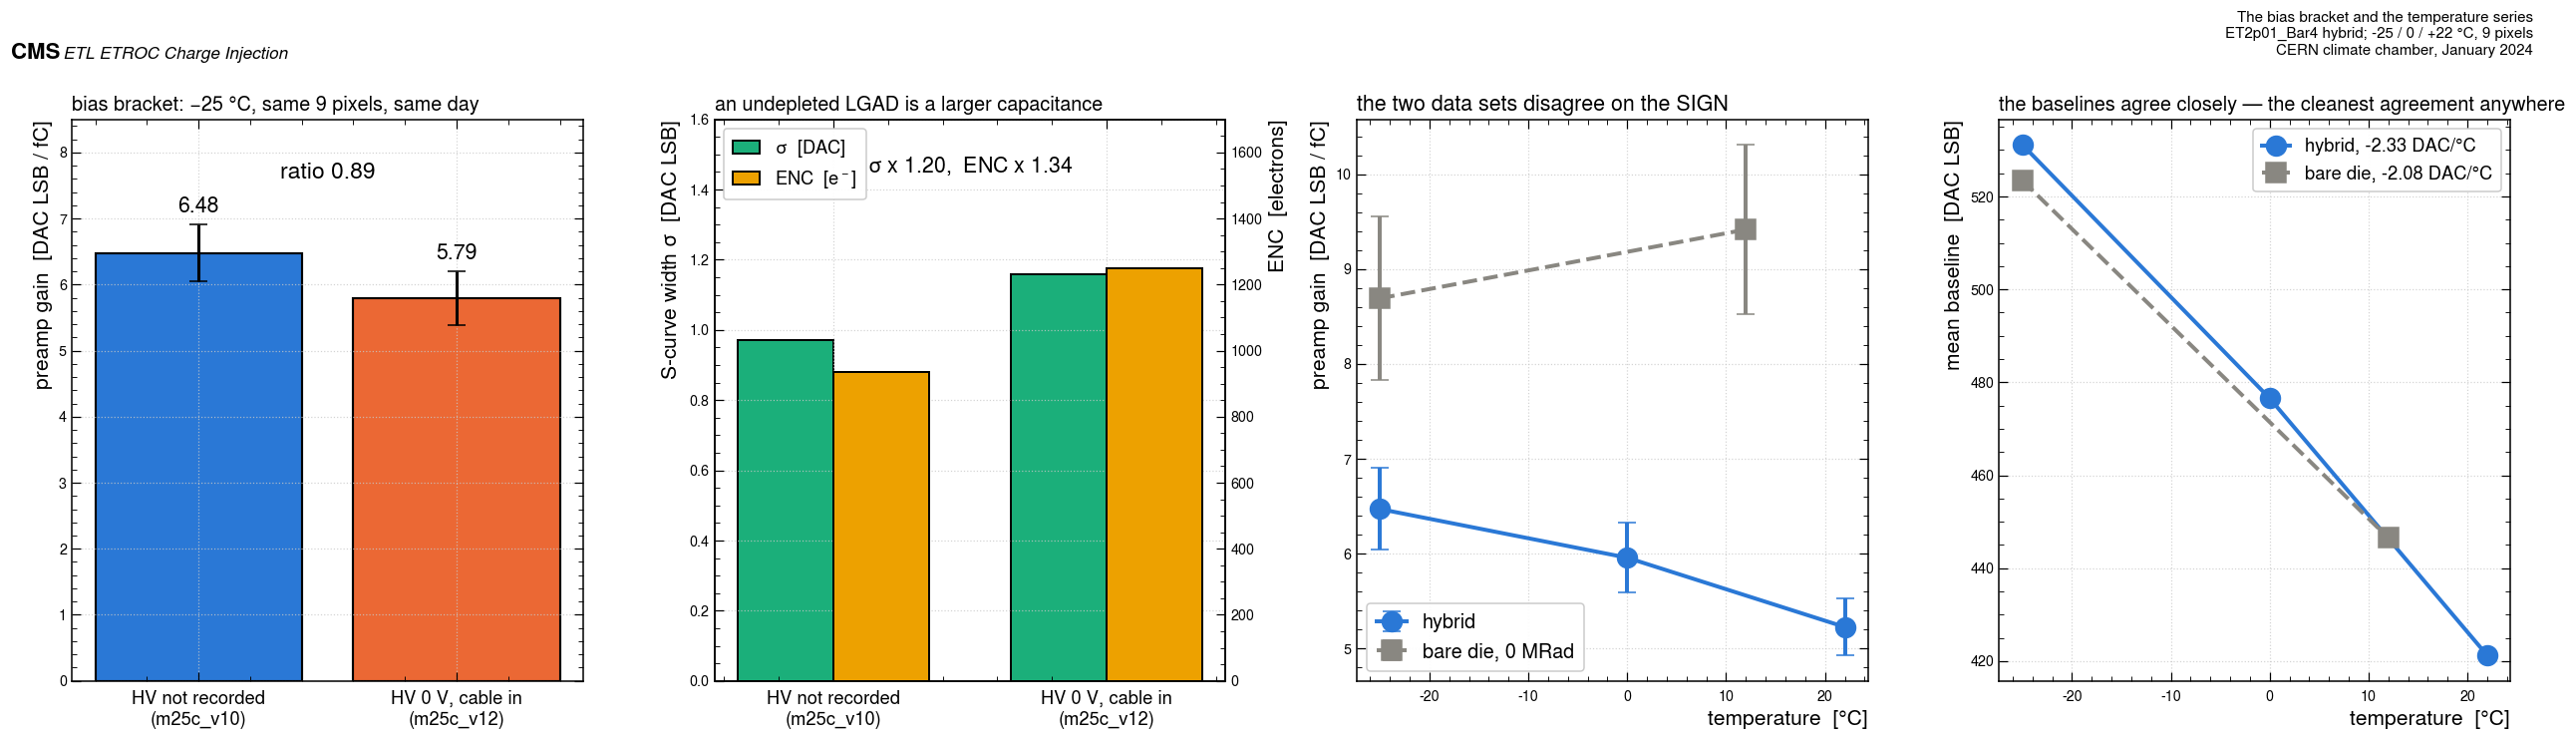

In [27]:
fig, axs = plt.subplots(1, 4, figsize=(23, 6.2))
ax = axs[0]
lbl = ["HV not recorded\n(m25c_v10)", "HV 0 V, cable in\n(m25c_v12)"]
ax.bar([0, 1], br.gain_dac_per_fc.values, yerr=br.gain_sem.values, capsize=6,
       color=[Q.C_BLUE, Q.C_ORANGE], edgecolor="black", lw=1.4)
for i, (v, e) in enumerate(zip(br.gain_dac_per_fc.values, br.gain_sem.values)):
    ax.text(i, v + e + 0.18, f"{v:.2f}", ha="center", fontsize=14)
ax.set_xticks([0, 1])
ax.set_xticklabels(lbl, fontsize=12)
ax.set_ylabel("preamp gain  [DAC LSB / fC]")
ax.set_ylim(0, 8.5)
ax.text(0.5, 7.6, f"ratio {bracket.iloc[2]['preamp gain [DAC/fC]']:.2f}", ha="center", fontsize=15)
ax.set_title("bias bracket: −25 °C, same 9 pixels, same day", loc="left", fontsize=13)

ax = axs[1]
w = 0.35
ax.bar(np.arange(2) - w / 2, br.sigma_dac.values, w, color=Q.C_AQUA, edgecolor="black", lw=1.3,
       label="$\\sigma$  [DAC]")
ax2 = ax.twinx()
ax2.bar(np.arange(2) + w / 2, br.ENC_e.values, w, color=Q.C_YELLOW, edgecolor="black", lw=1.3,
        label="ENC  [e$^-$]")
ax2.set_ylabel("ENC  [electrons]")
ax2.grid(False)
ax.set_xticks([0, 1])
ax.set_xticklabels(lbl, fontsize=12)
ax.set_ylabel("S-curve width $\\sigma$  [DAC LSB]")
ax.set_ylim(0, 1.6)
ax2.set_ylim(0, 1700)
ax.text(0.5, 1.45, f"$\\sigma$ x {bracket.iloc[2]['sigma [DAC]']:.2f},  ENC x {bracket.iloc[2]['ENC [e-]']:.2f}",
        ha="center", fontsize=14)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=12, loc="upper left", framealpha=0.95)
ax.set_title("an undepleted LGAD is a larger capacitance", loc="left", fontsize=13)

ax = axs[2]
ax.errorbar(ts["T"], ts.gain_dac_per_fc, yerr=ts.gain_sem, fmt="o-", ms=13, lw=2.6,
            color=Q.C_BLUE, capsize=6, label="hybrid")
bgc = pd.read_csv(Q.OUTDIR / "bare_gain_by_condition.csv")
bgc0 = bgc[bgc.dose == 0]
ax.errorbar(bgc0.temp, bgc0.gain_dac_per_fc, yerr=bgc0.gain_sem, fmt="s--", ms=13, lw=2.6,
            color=Q.GREY, capsize=6, label="bare die, 0 MRad")
ax.set_xlabel("temperature  [°C]")
ax.set_ylabel("preamp gain  [DAC LSB / fC]")
ax.legend(fontsize=13)
ax.set_title("the two data sets disagree on the SIGN", loc="left", fontsize=14)

ax = axs[3]
ax.plot(ts["T"], ts.BL_mean, "o-", ms=13, lw=2.6, color=Q.C_BLUE,
        label=f"hybrid, {slope_bl:.2f} DAC/°C")
ax.plot([-25, 12], [float(bgc0[bgc0.temp == -25].BL_mean.iloc[0]),
                    float(bgc0[bgc0.temp == 12].BL_mean.iloc[0])], "s--", ms=13, lw=2.6,
        color=Q.GREY, label=f"bare die, {B['bl_per_degC_at_0MRad']:.2f} DAC/°C")
ax.set_xlabel("temperature  [°C]")
ax.set_ylabel("mean baseline  [DAC LSB]")
ax.legend(fontsize=12)
ax.set_title("the baselines agree closely — the cleanest agreement anywhere", loc="left", fontsize=13)
fig.tight_layout()
Q.fig_header(fig, "The bias bracket and the temperature series",
       tag="ET2p01_Bar4 hybrid; -25 / 0 / +22 °C, 9 pixels", scale=0.62)
Q.save_fig(fig, "hyb_fig8_bias_and_temperature")
plt.show()

### An open discrepancy, stated rather than smoothed over

**The preamp gain rises on cooling here — about +24 % from +22 to −25 °C — while the bare die went the
other way, −7.7 % on cooling from +12 to −25 °C.** The two data sets disagree on the sign of
the temperature coefficient of preamp gain, and this analysis cannot resolve it. The hybrid's −25 °C
point has a bias state that is `not recorded`, and the bare chip's −25 °C point came from
turn-off files only. It is recorded here as an open discrepancy.

What the two *do* agree on is the baseline: −2.34 DAC per degree here against −2.08 on the
bare die. That is the cleanest agreement anywhere between the two data sets, and it supports
the operational conclusion both campaigns reach — **autocalibrate, then work at a fixed offset
above the new baseline**, which is what the beam pipeline does with `threshold = BL + 20`.

In [28]:
# Is the hybrid's rising-on-cooling preamp gain a configuration artefact? The one check the data allow:
# at 0 C the campaign has BOTH an untagged configuration and a fully tagged one (HV 210 V,
# highpower), and at 22 C an untagged one and a tagged one. If the untagged -25 C configurations
# were in a different power state, the untagged/tagged pairs should disagree.
pairs = [("0 °C", "2024-01-12__0c_v2", "2024-01-18__0c_v15_HV_210_highpower"),
         ("22 °C", "2024-01-12_22C_ONR__(none)", "2024-01-19__22c_v20_HV_210_highpower")]
gb_ = GB.set_index("config").gain_dac_per_fc
for T_, u, t in pairs:
    if u in gb_.index and t in gb_.index:
        print("%s: untagged %.3f  tagged (HV 210 V, highpower) %.3f  ratio %.3f" % (T_, gb_[u], gb_[t], gb_[u] / gb_[t]))
print("\nAt 0 C the two agree to 0.4 %, so an untagged configuration is not by itself a different power state;")
print("at 22 C they differ by 15 % (the 22C_ONR acquisition is a different session and setup). The -25 C")
print("series (four untagged configurations agreeing with each other to 0.4 %) therefore most likely IS at")
print("the tagged settings, and the +24 % rise on cooling is most likely real for this hybrid. The bare")
print("die's -7.7 % on cooling rests on a different scan type at -25 C (turn-off files, not a sweep), so the")
print("disagreement is between two methods as much as between two devices. It stays open, but the weight")
print("of evidence is on the hybrid side; a same-method temperature scan is the test (notebook 04, question 4).")

0 °C: untagged 5.936  tagged (HV 210 V, highpower) 5.957  ratio 0.996
22 °C: untagged 4.441  tagged (HV 210 V, highpower) 5.226  ratio 0.850

At 0 C the two agree to 0.4 %, so an untagged configuration is not by itself a different power state;
at 22 C they differ by 15 % (the 22C_ONR acquisition is a different session and setup). The -25 C
series (four untagged configurations agreeing with each other to 0.4 %) therefore most likely IS at
the tagged settings, and the +24 % rise on cooling is most likely real for this hybrid. The bare
die's -7.7 % on cooling rests on a different scan type at -25 C (turn-off files, not a sweep), so the
disagreement is between two methods as much as between two devices. It stays open, but the weight
of evidence is on the hybrid side; a same-method temperature scan is the test (notebook 04, question 4).


## 12. Bare against hybrid

Everything on the bare side comes from `outputs/bare_results.json`, written by notebook 01, so
both sides went through the same functions. Before the comparison, the conditions that differ.

In [29]:
DIFFS = pd.DataFrame([
    dict(quantity="chip", bare=B["chip"] + " (bare die)", hybrid="ET2p01_Bar4 (LGAD bonded)",
         matters="the point of the comparison, but also a chip-to-chip difference"),
    dict(quantity="chip revision", bare="ET2.01", hybrid="ET2.01", matters="same — good"),
    dict(quantity="temperature", bare="+12 °C", hybrid="0 °C",
         matters="differs; the two sets disagree on the sign of the preamp gain coefficient (section 11)"),
    dict(quantity="sensor bias", bare="no sensor", hybrid="210 V",
         matters="differs by construction"),
    dict(quantity="pixel set", bare="rows 0,1,3,12", hybrid="rows 2,8,14",
         matters="NO overlap; set-to-set, never pixel-to-pixel"),
    dict(quantity="pixels", bare="12", hybrid="9", matters="small samples on both sides"),
    dict(quantity="power mode", bare="not recorded", hybrid="highpower (a tag, see section 5)",
         matters="differs by an unknown amount"),
    dict(quantity="RFSel", bare="not recorded", hybrid="not recorded",
         matters="the largest unquantified systematic; sets preamp gain AND TOT"),
    dict(quantity="TID history", bare="0 MRad (explicitly pre-irradiation)", hybrid="not recorded",
         matters="whether Bar4 had seen dose is unknown"),
])
print(DIFFS.to_string(index=False))

     quantity                                bare                           hybrid                                                                                matters
         chip             ET2p01_W36_6 (bare die)        ET2p01_Bar4 (LGAD bonded)                        the point of the comparison, but also a chip-to-chip difference
chip revision                              ET2.01                           ET2.01                                                                            same — good
  temperature                              +12 °C                             0 °C differs; the two sets disagree on the sign of the preamp gain coefficient (section 11)
  sensor bias                           no sensor                            210 V                                                                differs by construction
    pixel set                       rows 0,1,3,12                      rows 2,8,14                                           NO overlap; set-to-set, n

In [30]:
def add(rows, quantity, unit, bare, hybrid, sens, note):
    rows.append(dict(quantity=quantity, unit=unit, bare=bare, hybrid=hybrid,
                     ratio=(hybrid / bare) if (bare and bare == bare) else np.nan,
                     capacitance_sensitivity=sens, note=note))


cmp_rows = []
add(cmp_rows, "Preamplifier gain, 9–28 fC", "DAC/fC", B["gain_dac_per_fc"], gain,
    "LOW — expected to transfer", "it did not: the sensor costs 37 % of the preamp gain")
add(cmp_rows, "Preamplifier gain", "mV/fC", B["gain_mv_per_fc"], gain * Q.LSB_MV,
    "LOW — expected to transfer", "the same statement in volts")
add(cmp_rows, "S-curve width sigma (shared-sigma fit)", "DAC", B["sigma_dac"], sigma,
    "HIGH — expected to grow", "it did not move: ratio 1.01")
add(cmp_rows, "ENC = sigma / (preamp gain)", "electrons", B["enc_e"], enc,
    "HIGH — expected to grow", "it grew — entirely through the preamp gain, not the edge")
add(cmp_rows, "Autocal noise width NW", "DAC", B["nw_dac"], nw["mean"],
    "HIGH — expected to grow", "it did grow, unlike sigma; NW is an accumulator measurement, not an edge")
add(cmp_rows, "Turn-off above baseline at 16 fC", "DAC", B["turnoff_off_by_charge"]["16"],
    float(tab.loc[16, "trig_turnoff_offset_mean"]), "LOW", "tracks the preamp gain ratio, as it must")
add(cmp_rows, "TOT at BL+20, 16 fC", "code", B["tot_off20_by_charge"]["16"],
    float(t20.loc[16, "tot_code_mean"]), "LOW — expected to transfer",
    "it did not: RFSel unrecorded on both sides is the likely cause")
add(cmp_rows, "TOA jitter at BL+20, 9 fC", "ps", B["jitter_off20_by_charge"]["9"],
    float(j20.loc[9, "mean"]), "HIGH", "above the floor on both sides — the useful jitter number")
add(cmp_rows, "TOA jitter at BL+20, 16 fC", "ps", B["jitter_off20_by_charge"]["16"],
    float(j20.loc[16, "mean"]), "HIGH", "both at the quantisation floor — a limit, not a resolution")
add(cmp_rows, "Minimum charge reaching BL+20", "fC", B["Qmin_at_off20_fC"], pq["mean"],
    "LOW", "higher, as the lower preamp gain requires")
add(cmp_rows, "Walk with charge, 6→28 fC at BL+20", "ps", B["walk_charge_6to28_at_off20_ps"],
    float(w20_mean[28] - w20_mean[6]), "MEDIUM", "much larger on the hybrid")
add(cmp_rows, "TDC quantisation floor", "ps", B["quantisation_floor_ps"], floor_ps,
    "none", "a property of the TDC and CAL, not of the front end")
CMP = pd.DataFrame(cmp_rows)
CMP.to_csv(Q.OUTDIR / "bare_vs_hybrid.csv", index=False)
print(CMP[["quantity", "unit", "bare", "hybrid", "ratio", "capacitance_sensitivity"]]
      .round(3).to_string(index=False))
print()
Q.check("preamp gain ratio hybrid / bare", gain / B["gain_dac_per_fc"], 0.632, 0.006, "", LEDGER)
Q.check("sigma ratio hybrid / bare", sigma / B["sigma_dac"], 1.011, 0.006, "", LEDGER)
Q.check("ENC ratio hybrid / bare (same estimator)", enc / B["enc_e"], 1.60, 0.01, "", LEDGER)
print("ENC against the bare study's published 584 e-: x %.3f" % (enc / 584.0))

                              quantity      unit    bare   hybrid  ratio    capacitance_sensitivity
            Preamplifier gain, 9–28 fC    DAC/fC   9.416    5.957  0.633 LOW — expected to transfer
                     Preamplifier gain     mV/fC   3.678    2.327  0.633 LOW — expected to transfer
S-curve width sigma (shared-sigma fit)       DAC   0.920    0.930  1.011    HIGH — expected to grow
           ENC = sigma / (preamp gain) electrons 609.838  974.471  1.598    HIGH — expected to grow
                Autocal noise width NW       DAC   3.167    4.444  1.404    HIGH — expected to grow
      Turn-off above baseline at 16 fC       DAC 116.030   72.940  0.629                        LOW
                   TOT at BL+20, 16 fC      code  49.873   84.939  1.703 LOW — expected to transfer
             TOA jitter at BL+20, 9 fC        ps  10.779   27.659  2.566                       HIGH
            TOA jitter at BL+20, 16 fC        ps   6.359   10.581  1.664                       HIGH


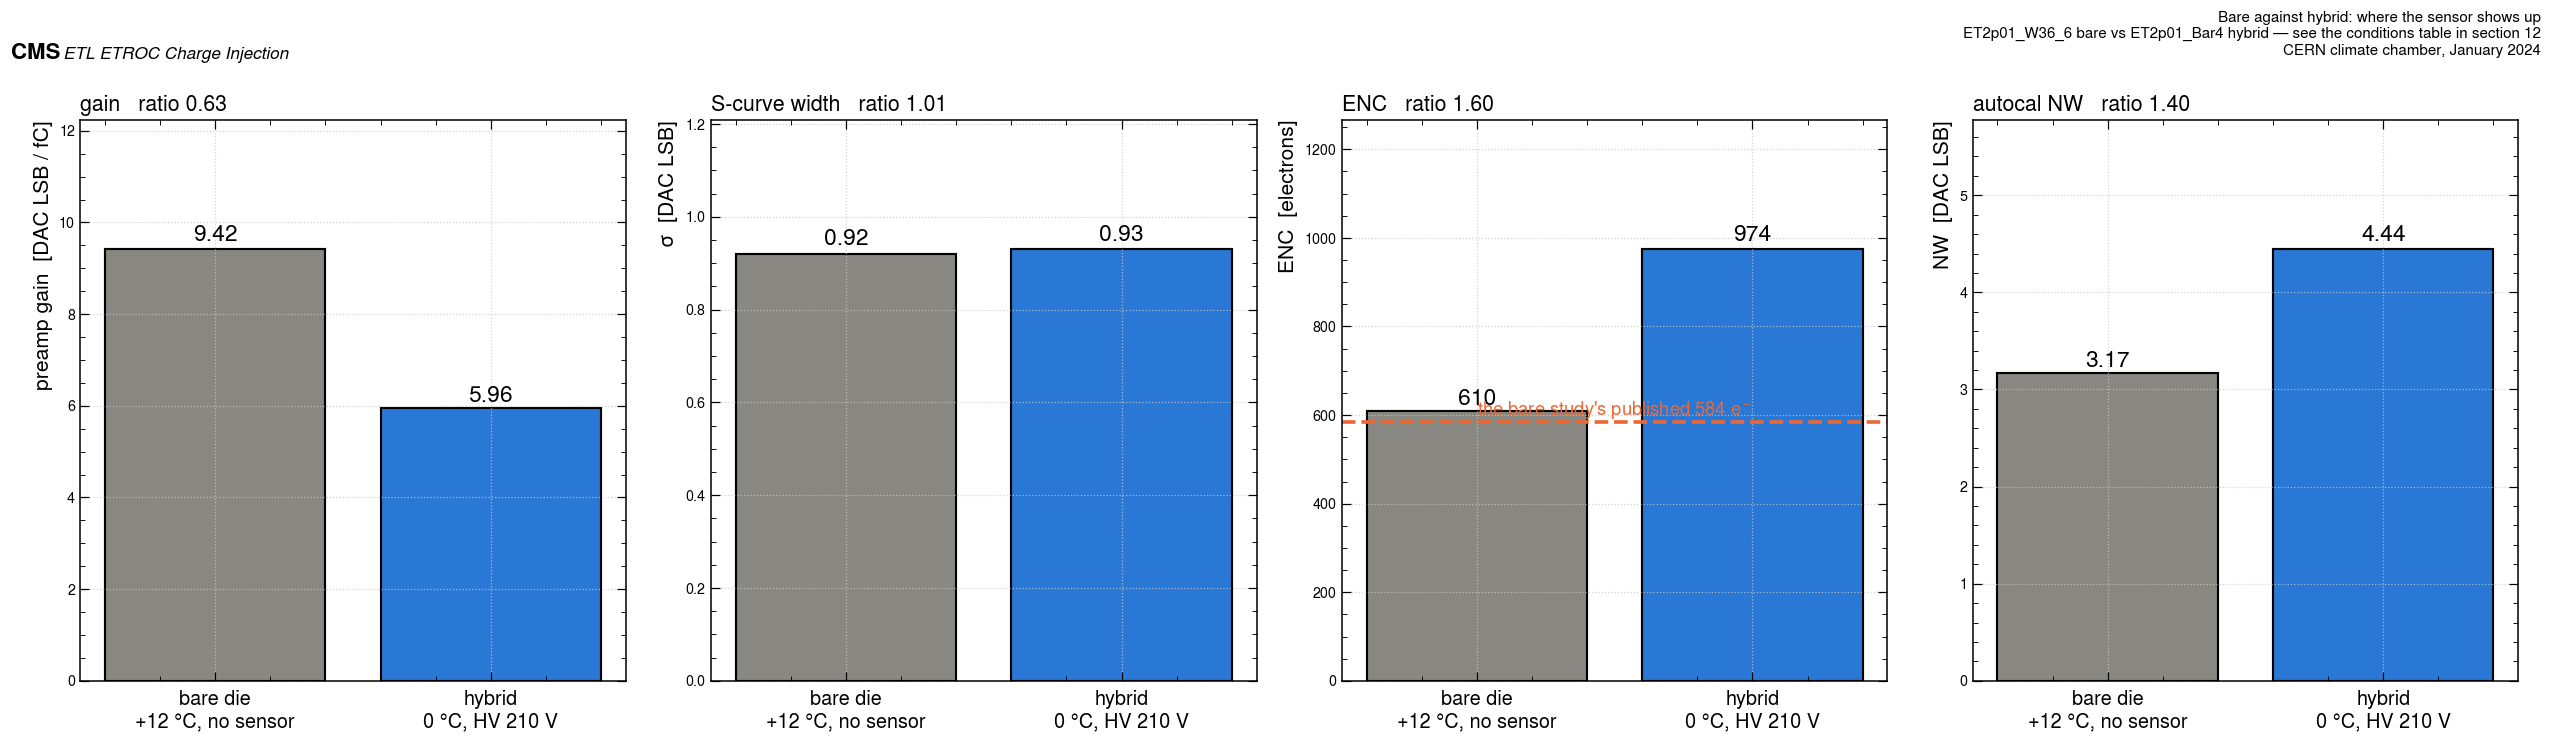

In [31]:
fig, axs = plt.subplots(1, 4, figsize=(23, 6.2))


def two_bars(ax, vals, labels, title, ylabel, fmt="%.2f"):
    ax.bar([0, 1], vals, color=[Q.GREY, Q.C_BLUE], edgecolor="black", lw=1.4)
    for i, v in enumerate(vals):
        ax.text(i, v * 1.02, fmt % v, ha="center", fontsize=15)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(labels, fontsize=13)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(vals) * 1.3)
    ax.set_title(title + f"   ratio {vals[1] / vals[0]:.2f}", loc="left", fontsize=14)


LBL = ["bare die\n+12 °C, no sensor", "hybrid\n0 °C, HV 210 V"]
two_bars(axs[0], [B["gain_dac_per_fc"], gain], LBL, "gain", "preamp gain  [DAC LSB / fC]")
two_bars(axs[1], [B["sigma_dac"], sigma], LBL, "S-curve width", "$\\sigma$  [DAC LSB]")
two_bars(axs[2], [B["enc_e"], enc], LBL, "ENC", "ENC  [electrons]", fmt="%.0f")
axs[2].axhline(584, color=Q.C_ORANGE, ls="--", lw=2.4)
axs[2].text(0.5, 600, "the bare study's published 584 e$^-$", ha="center", fontsize=12, color=Q.C_ORANGE)
two_bars(axs[3], [B["nw_dac"], nw["mean"]], LBL, "autocal NW", "NW  [DAC LSB]")
fig.tight_layout()
Q.fig_header(fig, "Bare against hybrid: where the sensor shows up",
       tag="ET2p01_W36_6 bare vs ET2p01_Bar4 hybrid — see the conditions table in section 12",
       scale=0.62)
Q.save_fig(fig, "hyb_fig9_bare_vs_hybrid")
plt.show()

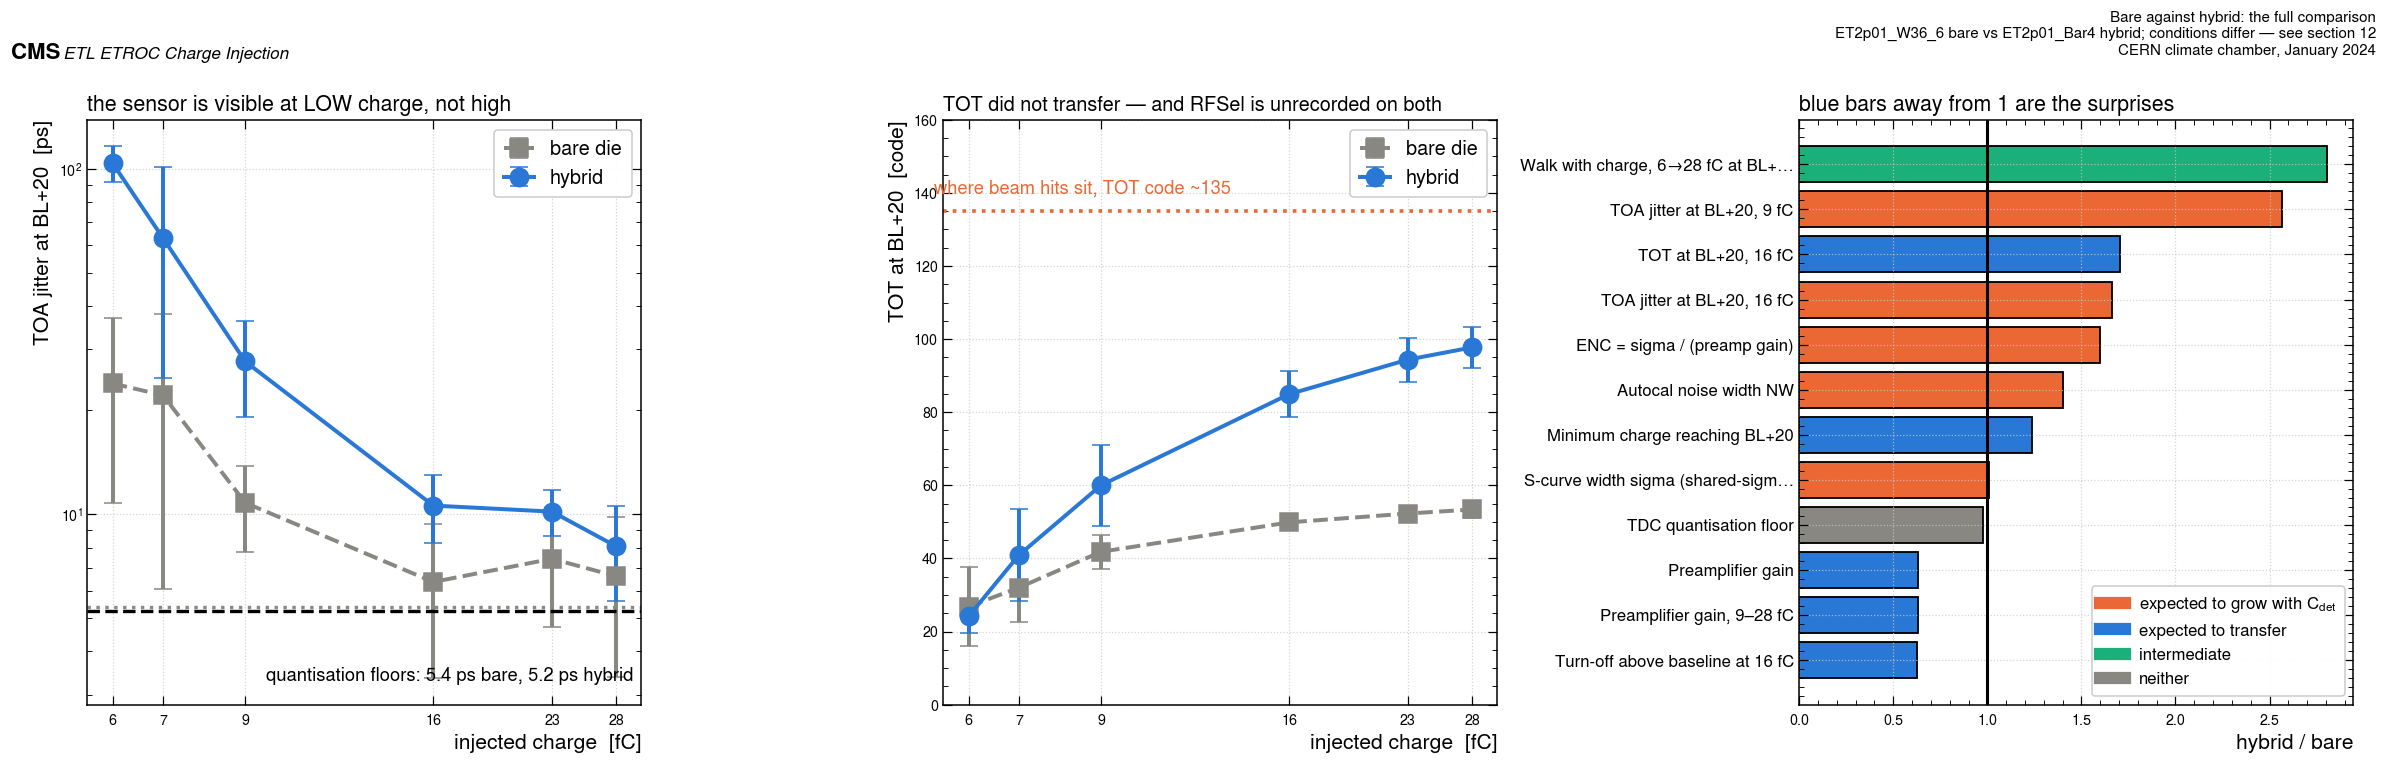

In [32]:
fig, axs = plt.subplots(1, 3, figsize=(21.5, 6.4))
ax = axs[0]
ax.errorbar(Q.CHARGES, [B["jitter_off20_by_charge"][str(c)] for c in Q.CHARGES],
            yerr=[B["jitter_off20_rms_by_charge"][str(c)] for c in Q.CHARGES],
            fmt="s--", ms=12, lw=2.6, color=Q.GREY, capsize=6, label="bare die")
ax.errorbar(j20.index, j20["mean"], yerr=j20["std"], fmt="o-", ms=12, lw=2.6, color=Q.C_BLUE,
            capsize=6, label="hybrid")
ax.axhline(B["quantisation_floor_ps"], color=Q.GREY, ls=":", lw=2.2)
ax.axhline(floor_ps, color="black", ls="--", lw=2.2)
ax.text(0.985, 0.035, "quantisation floors: %.1f ps bare, %.1f ps hybrid"
        % (B["quantisation_floor_ps"], floor_ps), transform=ax.transAxes, fontsize=12,
        ha="right", va="bottom")
Q.charge_axis(ax)
ax.set_yscale("log")
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOA jitter at BL+20  [ps]")
ax.legend(fontsize=13)
ax.set_title("the sensor is visible at LOW charge, not high", loc="left", fontsize=14)

ax = axs[1]
ax.errorbar(Q.CHARGES, [B["tot_off20_by_charge"][str(c)] for c in Q.CHARGES],
            yerr=[B["tot_off20_rms_by_charge"][str(c)] for c in Q.CHARGES],
            fmt="s--", ms=12, lw=2.6, color=Q.GREY, capsize=6, label="bare die")
ax.errorbar(t20.index, t20.tot_code_mean, yerr=t20.tot_code_pixel_rms, fmt="o-", ms=12, lw=2.6,
            color=Q.C_BLUE, capsize=6, label="hybrid")
ax.axhline(135, color=Q.C_ORANGE, ls=":", lw=2.4)
ax.text(5.4, 140, "where beam hits sit, TOT code ~135", fontsize=12, color=Q.C_ORANGE)
Q.charge_axis(ax)
ax.set_xlabel("injected charge  [fC]")
ax.set_ylabel("TOT at BL+20  [code]")
ax.set_ylim(0, 160)
ax.legend(fontsize=13)
ax.set_title("TOT did not transfer — and RFSel is unrecorded on both", loc="left", fontsize=13)

ax = axs[2]
r = CMP.dropna(subset=["ratio"]).sort_values("ratio")
cols = {"HIGH — expected to grow": Q.C_ORANGE, "HIGH": Q.C_ORANGE,
        "LOW — expected to transfer": Q.C_BLUE, "LOW": Q.C_BLUE,
        "MEDIUM": Q.C_AQUA, "none": Q.GREY}
ax.barh(range(len(r)), r.ratio, color=[cols.get(s, Q.GREY) for s in r.capacitance_sensitivity],
        edgecolor="black", lw=1.2)
ax.axvline(1.0, color="black", lw=2)
ax.set_yticks(range(len(r)))
ax.set_yticklabels([q if len(q) < 34 else q[:32] + "…" for q in r.quantity], fontsize=11)
ax.set_xlabel("hybrid / bare")
h = [plt.Line2D([], [], color=c, lw=8, label=l) for l, c in
     [("expected to grow with C$_{det}$", Q.C_ORANGE), ("expected to transfer", Q.C_BLUE),
      ("intermediate", Q.C_AQUA), ("neither", Q.GREY)]]
ax.legend(handles=h, fontsize=11, loc="lower right")
ax.set_title("blue bars away from 1 are the surprises", loc="left", fontsize=14)
fig.tight_layout()
Q.fig_header(fig, "Bare against hybrid: the full comparison",
       tag="ET2p01_W36_6 bare vs ET2p01_Bar4 hybrid; conditions differ — see section 12", scale=0.62)
Q.save_fig(fig, "hyb_fig10_bare_vs_hybrid_curves")
plt.show()

## 13. Summary

In [33]:
SUMMARY = pd.DataFrame([
    dict(n=1, quantity="Preamp gain (charge-to-threshold), 9–28 fC", value=f"{gain:.2f} ± {pg['sem']:.2f}",
         unit="DAC/fC", pixel_rms=f"{pg['rms']:.2f}", label="DERIVED"),
    dict(n=2, quantity="the same in volts", value=f"{gain * Q.LSB_MV:.2f} ± {pg['sem'] * Q.LSB_MV:.2f}",
         unit="mV/fC", pixel_rms=f"{pg['rms'] * Q.LSB_MV:.2f}", label="DERIVED"),
    dict(n=3, quantity="Turn-off above baseline at 16 fC",
         value=f"{tab.loc[16, 'trig_turnoff_offset_mean']:.1f}", unit="DAC",
         pixel_rms=f"{tab.loc[16, 'trig_pixel_rms']:.1f}", label="DERIVED from RAW FPGA counters"),
    dict(n=4, quantity="TOT at BL+20, 16 fC", value=f"{t20.loc[16, 'tot_code_mean']:.1f}",
         unit=f"code = {t20.loc[16, 'tot_ns_mean']:.2f} ns",
         pixel_rms=f"{t20.loc[16, 'tot_code_pixel_rms']:.1f}", label="DERIVED"),
    dict(n=5, quantity="TOA jitter at BL+20, 16 fC", value=f"{j20.loc[16, 'mean']:.1f}", unit="ps",
         pixel_rms=f"{j20.loc[16, 'std']:.1f}", label="DERIVED — near the quantisation floor"),
    dict(n=6, quantity="TOA jitter at BL+20, 9 fC", value=f"{j20.loc[9, 'mean']:.1f}", unit="ps",
         pixel_rms=f"{j20.loc[9, 'std']:.1f}", label="DERIVED — above the floor, the useful one"),
    dict(n=7, quantity="S-curve width σ (54 curves, shared σ)",
         value=f"{sigma:.2f} ± {sigma_sd:.2f}", unit=f"DAC = {sigma * Q.LSB_MV:.3f} mV",
         pixel_rms="—", label="DERIVED"),
    dict(n=8, quantity="ENC = σ / (preamp gain)", value=f"{enc:.0f} ± {enc_err:.0f}", unit="electrons",
         pixel_rms="—", label="DERIVED — the sensor-loaded number"),
    dict(n=9, quantity="Autocal noise width NW", value=f"{nw['mean']:.2f} ± {nw['sem']:.2f}",
         unit="DAC", pixel_rms=f"{nw['rms']:.2f}", label="RAW (NW_map)"),
    dict(n=10, quantity="Minimum charge reaching BL+20", value=f"{pq['mean']:.1f} ± {pq['sem']:.1f}",
         unit="fC", pixel_rms=f"{pq['rms']:.1f}", label="DERIVED, extrapolated"),
    dict(n=11, quantity="TOT-to-charge law at BL+20",
         value=f"TOT = {fits[20]['a']:.1f} + {fits[20]['b']:.1f} ln(Q/fC)",
         unit=f"χ²/ndf {fits[20]['chi2_ndf']:.1f}", pixel_rms="—", label="DERIVED — a poor fit"),
    dict(n=12, quantity="TDC quantisation floor, LSB/√12", value=f"{floor_ps:.2f}", unit="ps",
         pixel_rms="—", label=f"DERIVED, TOA LSB {lsb_ps:.2f} ps"),
    dict(n=13, quantity="Walk with charge, 6→28 fC at BL+20",
         value=f"{w20_mean[28] - w20_mean[6]:+.0f}", unit="ps", pixel_rms="—", label="DERIVED"),
    dict(n=14, quantity="Bias bracket, preamp gain ratio HV nominal → 0 V (cable in)",
         value=f"{bracket.iloc[2]['preamp gain [DAC/fC]']:.2f}", unit="—", pixel_rms="—",
         label="DERIVED — the only confound-free capacitance handle"),
    dict(n=15, quantity="Preamp gain ratio hybrid / bare", value=f"{gain / B['gain_dac_per_fc']:.2f}",
         unit="—", pixel_rms="—", label="DERIVED — conditions differ, section 12"),
    dict(n=16, quantity="ENC ratio hybrid / bare", value=f"{enc / B['enc_e']:.2f}", unit="—",
         pixel_rms="—", label="DERIVED — entirely through the preamp gain"),
])
SUMMARY.to_csv(Q.OUTDIR / "hybrid_summary_numbers.csv", index=False)
print(SUMMARY.to_string(index=False))

 n                                                    quantity                       value           unit pixel_rms                                               label
 1                  Preamp gain (charge-to-threshold), 9–28 fC                 5.96 ± 0.37         DAC/fC      1.10                                             DERIVED
 2                                           the same in volts                 2.33 ± 0.14          mV/fC      0.43                                             DERIVED
 3                            Turn-off above baseline at 16 fC                        72.9            DAC      12.3                      DERIVED from RAW FPGA counters
 4                                         TOT at BL+20, 16 fC                        84.9 code = 3.04 ns       6.4                                             DERIVED
 5                                  TOA jitter at BL+20, 16 fC                        10.6             ps       2.4               DERIVED — near the quantisatio

## 14. Reproduction ledger

Every headline number above was compared, in the cell that computed it, against the value
previously published for this data set (`summary_numbers.json`).

Rows are named by physical charge, (QSel + 1) fC. The published side was quoted at the QSel label,
charge − 1, which the `published_label_fC` column gives for each row that names a charge. Rows
marked "QSel-label axis" convert the recomputed value back to that axis before comparing: the fit
intercept as physical + (preamp gain) × 1 fC, `Q_min` as physical − 1 fC, and the TOT log law
refitted against the label.

In [34]:
LED = pd.DataFrame(LEDGER)
LED["|diff|"] = LED["diff"].abs()
print(LED[["quantity", "recomputed", "published", "published_label_fC", "|diff|", "tol", "unit", "agrees"]]
      .round(4).to_string(index=False))
LED.to_csv(Q.OUTDIR / "hybrid_reproduction_ledger.csv", index=False)
n_ok = int(LED.agrees.sum())
print("\n%d of %d checks agree within tolerance." % (n_ok, len(LED)))
if n_ok < len(LED):
    print("\nDisagreements:")
    print(LED[~LED.agrees][["quantity", "recomputed", "published", "|diff|", "unit"]]
          .round(4).to_string(index=False))

                                                  quantity  recomputed  published published_label_fC  |diff|   tol      unit  agrees
                             mean baseline, primary config    476.5556   476.5556                     0.0000 0.020       DAC    True
 analog rail current, 2024-01-18 (0c_v15_HV_210_highpower)      0.3419     0.3419                     0.0000 0.002         A    True
analog rail current, 2024-01-19 (22c_v20_HV_210_highpower)      0.4994     0.4995                     0.0001 0.002         A    True
                               preamp gain, primary config      5.9567     5.9547                     0.0020 0.010    DAC/fC    True
                       preamp gain uncertainty on the mean      0.3662     0.3660                     0.0001 0.010    DAC/fC    True
                                     preamp gain pixel RMS      1.0985     1.0981                     0.0004 0.010    DAC/fC    True
                                      preamp gain in volts      2.326

### The one systematic disagreement: the turn-off estimator

The published hybrid tables took the turn-off to be **the highest probe at or above 50 %**;
this notebook, like notebook 01, **interpolates the efficiency to 0.5** between that probe and
the next one above it. The interpolated point is sub-LSB and it is the estimator the bare-die
tables were built with, so using it is what makes the two campaigns comparable — but it lands
about half a probe step higher, which is why every turn-off offset here reads a few tenths of
a DAC above the published value, and why the low-charge preamp gain cross-check, the fit intercept
and `Q_min` shift slightly with it.

The cell below quantifies the shift so it can be seen rather than argued about. The preamp gain
itself is a *slope* and is almost untouched, which is why the headline number reproduces.

In [35]:
alt = Q.turnoff_table(PR[PR.config == PRIMARY], ["row", "col", "charge_fC"], method="maxdac")
cmp_est = (tp[["row", "col", "charge_fC", "trig_turnoff_dac"]]
           .merge(alt[["row", "col", "charge_fC", "trig_turnoff_dac"]],
                  on=["row", "col", "charge_fC"], suffixes=("_interp", "_maxdac")))
cmp_est["delta"] = cmp_est.trig_turnoff_dac_interp - cmp_est.trig_turnoff_dac_maxdac
print("interpolated 50 %% point minus highest-probe-above-50 %%, over %d (pixel, charge) pairs:"
      % len(cmp_est))
print("  mean %+.3f DAC, median %+.3f DAC, range %+.3f to %+.3f DAC"
      % (cmp_est.delta.mean(), cmp_est.delta.median(), cmp_est.delta.min(), cmp_est.delta.max()))
gf_alt = []
for (r, c), g in alt.merge(BLC[BLC.config == PRIMARY][["row", "col", "BL_dac"]],
                           on=["row", "col"]).groupby(["row", "col"]):
    rec = Q.gain_fit(g, g.BL_dac.iloc[0], charge_col="charge_fC")
    if rec:
        gf_alt.append(rec)
alt_gain = Q.pooled(pd.DataFrame(gf_alt).gain_dac_per_fc)
print("\ngain with the published estimator: %.3f +- %.3f DAC/fC  (published %.3f)"
      % (alt_gain["mean"], alt_gain["sem"], SN["gain"]["dac_per_fc"]))
print("preamp gain with this notebook's estimator: %.3f +- %.3f DAC/fC" % (gain, pg["sem"]))
print("difference %.3f DAC/fC, i.e. %.2f %% -- far inside the %.0f %% pixel spread."
      % (abs(gain - alt_gain["mean"]), 100 * abs(gain - alt_gain["mean"]) / gain,
         100 * pg["rms"] / gain))

interpolated 50 % point minus highest-probe-above-50 %, over 54 (pixel, charge) pairs:
  mean +0.437 DAC, median +0.428 DAC, range +0.028 to +0.955 DAC

gain with the published estimator: 5.955 +- 0.366 DAC/fC  (published 5.955)
preamp gain with this notebook's estimator: 5.957 +- 0.366 DAC/fC
difference 0.002 DAC/fC, i.e. 0.03 % -- far inside the 18 % pixel spread.


## 15. Caveats — all of them

**About the data set**

1. **The −25 °C bias is `not recorded`, everywhere.** There is no HV log in this campaign. The
   bracket in section 11 shows that `m25c_v10` differs from a known 0 V state, but the *value*
   of its bias is unknown.
2. **`HV_off_CablePluggedIn` is a depletion bracket, not a disconnection bracket.** The sensor
   is still bonded and still loading the input.
3. **`highpower` is a directory tag, not a measurement.** Both flagship configurations carry
   it, yet their logged analog currents differ by about half (section 5). Unresolved.
4. **RFSel is not recorded** — on this campaign or on the bare-die one. It sets the feedback
   resistance and therefore directly affects preamp gain and TOT. This is the single largest
   unquantified systematic here, and the most likely explanation of the ×1.7 TOT difference.
5. **Power mode is not recorded on the bare-die side at all**, so the bare-versus-hybrid
   comparison differs in power mode by an unknown amount as well.
6. **Three of the four −25 °C configurations wrote only undecoded binary**, so they contribute
   turn-off and NoiseOnly data but no sweep, no σ-from-sweep and no jitter.
7. **Scan windows are not recoverable** (section 5), so the auxiliary logs can be aligned with
   the scans only to the day.

**About the comparison**

8. **The bare and hybrid pixel sets do not overlap** for the flagship configurations. Given
   the 18–33 % pixel-to-pixel preamp gain spread, part of the 0.63 preamp gain ratio could be pixel
   selection. Nine and twelve pixels are small samples.
9. **Chip, temperature, bias and pixel set all differ at once** (the table in section 12). The
   internal bias bracket exists precisely because this comparison cannot be clean.
10. **Chip revision.** Both are ET2.01; the beam hardware is ET2.02, which fixed the on-chip
    voltage reference. The absolute DAC-to-millivolt scale is not guaranteed to carry over,
    which is a second reason to prefer offset above baseline everywhere.
11. **σ estimators are not interchangeable.** Notebook 01 records that the bare-die study
    published 0.88 DAC where the shared-σ fit gives 0.92; every σ, ENC and NW comparison here
    uses the 0.92, i.e. both sides on the same estimator. Against the published 584 e⁻ the ENC
    ratio would read 1.67 instead of 1.60.
12. **The two campaigns disagree on the sign of the temperature coefficient of preamp gain**
    (section 11). Open, not resolved.

**About the points themselves**

13. **The hit count is not an efficiency.** The sweep acquires for a fixed time. Efficiency
    statements come from the FPGA counters, which have a denominator.
14. **A missing (pixel, charge, threshold) row means zero hits, not "not scanned".** The
    directory census distinguishes the two, which is how the censoring flag is computed.
15. **No cut is applied at any stage.** `cal_rms > 2 codes` is written as a flag, not a filter;
    3.5 % of primary-configuration points carry it and they sit within a few DAC of turn-off.
    What varies is coverage: at BL+20 only 5 of 9 pixels have a 6 fC point and 8 of 9 a 7 fC
    point, so those pooled numbers average fewer pixels. Every pooled table carries its `n`.